<b><font size="6" color="#EE964B">Notes before running this notebook</font></b><br>

**Bonus code.** The interactive dashboard (Section 5, *Categorical Features Visualization*) is located at the **end of the notebook**. The rest of the notebook (data cleaning and exploratory analysis) does not depend on it, so it can be read and run without the dashboard.

**Why we use `%pip install`.** The dashboard needs the libraries `dash`, `dash-ag-grid` and `plotly`, which are not part of the base environment provided in `setup/fall2627_env.yml` and `setup/requirements.txt`. The first code cell runs `%pip install` to install them directly in the active kernel, so the notebook runs without any manual setup.

We use `%pip` instead of `!pip` because it installs the packages in the same environment as the selected kernel (`Fall2627`). With `!pip`, the packages may end up in a different Python installation, and the imports would still fail.

In [112]:
%pip install -q dash dash-ag-grid plotly

Note: you may need to restart the kernel to use updated packages.


<b><font size="6" color="#EE964B">1. Introduction</font></b><br>

In this project, we are going to analyze a dataset that belongs to a company that sells subscription-based memberships to a physical workspace. Clients choose a `plan_tier` and can add extra services. 

The dataset includes one row per client and it covers four kinds of information:

- **Profile:** age, gender, industry, country, and whether the account is a team account.
- **Contract:** plan tier, days per week included in the plan, membership start and end dates, number of renewals.
- **Behaviour:** total and average weekly visits, entitled vs. actual visits in the last period, last badge swipe, days since the last visit, hours of meeting rooms and event space, guest passes issued.
- **Value:** `lifetime_value`.

The goal of this project is to understand **who our clients are and how they use their subscription**, in order to support decisions on retention and on the commercial offer.

In [1]:
#libraries
import sqlite3
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from math import ceil
from matplotlib.colors import LinearSegmentedColormap
from dash import Dash, html, dcc, callback, Output, Input
import dash_ag_grid as dag
import plotly.express as px
from itertools import combinations

# for better resolution plots
%config InlineBackend.figure_format = 'retina' # optionally, you can change 'svg' to 'retina'

# Setting seaborn style
main_color = "#40916C"
colors = ["#1B4332", "#40916C", "#95D5B2", "#F4D35E", "#EE964B"]
sns.set_theme(style="ticks", palette=colors)

<b><font size="6" color="#EE964B">2. Data Exploration and Initial Analysis</font></b><br>

Before cleaning or analyzing relationships, we first need to understand what our dataset contains and how reliable it is. Starting by looking at the first five rows of the dataset.

In [2]:
df_raw = pd.read_csv("../data/acdc_dataset.csv", sep=";", index_col="member_id")
df = df_raw.copy()
df_raw.head()

,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,...,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
member_id,,,,,,,,,,,,,,,,,,,,,
CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,...,False,True,0,False,True,True,False,False,2,4477.97
CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,...,False,False,0,True,False,False,False,False,0,165.86
CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,...,False,False,0,False,False,False,False,False,1,4486.17
CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,...,False,False,0,False,False,False,False,False,0,258.63
CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,...,False,False,0,False,False,True,False,False,0,335.74


By looking at these rows, we can already see some inconsistencies. For example, `gender` has two different ways of representing female (**Female** and **F**), and `plan_tier` has two different ways of writing the same plan (**HOT_DESK** and **hot_desk**).

In the next cell, we use `.info()` to see the number of rows and columns of the dataset, the data type of each column and how many non-null values they have, as this information will be fundamental for many of our later decisions.

In [3]:
df_raw.info()

<class 'pandas.core.frame.DataFrame'>
Index: 15465 entries, CW000001 to CW015101
Data columns (total 30 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   age                          14907 non-null  float64
 1   gender                       14935 non-null  object 
 2   industry                     15465 non-null  object 
 3   country                      15035 non-null  object 
 4   is_team_account              15465 non-null  bool   
 5   n_colleagues_on_account      15465 non-null  int64  
 6   plan_tier                    15360 non-null  object 
 7   plan_days_per_week           15465 non-null  int64  
 8   membership_start             15465 non-null  object 
 9   membership_end               15465 non-null  object 
 10  last_badge_swipe             15465 non-null  object 
 11  days_since_last_visit        15465 non-null  int64  
 12  total_visits                 15465 non-null  int64  
 13  avg_weekly_

The dataset has a total of 15465 rows and 30 columns originally. We can already see some inconsistencies in the data types: 

- In the first rows of the dataset, we could see that `membership_start` and `membership_end` represent dates, however they are an object type.
- `uses_print` is supposed to be a boolean (like the other columns that start with `uses_`), but its an int type.
- When we checked the first five rows, `lifetime_value`appeared to be a float, and it should be by its description, however its type is object.

We can also see that some columns have null values, so we decided to analyze them in more detail.

In [4]:
missing = df.isna().sum()
missing_table = pd.DataFrame({
    "missing": missing,
    "percentage of rows": (missing / len(df) * 100).round(2),
})

missing_table = (missing_table[missing_table["missing"] > 0]
                 .sort_values("missing", ascending=False))
print(missing_table)
print(f"Total missing values: {missing_table['missing'].sum()}")
print(f"Total percentage of missing values: {100*(missing_table['missing'].sum())/(df.shape[0]*df.shape[1])}")

                     missing  percentage of rows
meeting_room_hours      1298                8.39
guest_passes_issued     1271                8.22
lifetime_value          1040                6.72
age                      558                3.61
gender                   530                3.43
country                  430                2.78
plan_tier                105                0.68
Total missing values: 5232
Total percentage of missing values: 1.1277077271257678


Seven of the dataset's columns have missing values: the three columns with the highest number of missing values are `meeting_room_hours` (8.39%), `guest_passes_issued` (8.22%) and `lifetime_value` (6.72%). The total number of cells with nulls is 5232, which corresponds to about 1.13% of all cells, therefore the missing data is limited and concentrated in a small number of variables. However, what may matter more is the number of rows affected, since a row with a single missing value may need to be removed or imputed lately.

Next, we used the `.describe()` method to get the descriptive statistics for the three types of columns we have: numeric, boolean and object.

In [5]:
df_raw.describe().T

,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.00,34.00,40.00,149.00
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.00,0.00,1.00,9.00
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.00,3.00,5.00,9.00
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.00,13.00,55.00,1212.00
total_visits,15465.0,110.406531,182.939340,-112.0,8.00,34.00,132.00,6530.00
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.40
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.800970,11.387207,0.0,5.00,10.00,20.00,60.00
meeting_room_hours,14167.0,33.075570,428.169678,-56.6,0.00,0.00,7.20,41220.00
event_space_hours,15465.0,5.117220,26.013097,-13.5,0.00,0.00,0.00,602.80


- `age`: the minimum age is 1 and the maximum is 149, so this column has invalid values.
- `n_colleagues_on_account`: the median is 0, so at least half of the customers do not have colleagues on the account. The minimum is -1, which tells us that this column also has invalid values.
- The columns `days_since_last_visit`, `total_visits`, `meeting_room_hours`, `event_space_hours`, `guest_passes_issued` and `n_renewals` have minimums below zero, so they also have invalid values. Their distributions are also highly skewed, since their means are significantly larger than their medians.
- The values of `entitled_visits_last_period` are larger than the values of `actual_visits_last_period`, which suggests that customers do not use all the visits they are entitled to.
- `uses_print`: at least half of the values are 0 and at least 25% of the values are 1, so it seems that the only values in this column are 0 and 1. The column appears to be a boolean, as we suspected.

In [6]:
df_raw.describe(include="bool").T

,count,unique,top,freq
is_team_account,15465,2,False,11112
uses_meeting_rooms,15465,2,False,10202
uses_event_space,15465,2,False,13624
uses_guest_passes,15465,2,False,12651
uses_mail_handling,15465,2,False,11901
uses_phone_booths,15465,2,False,11469
uses_day_passes,15465,2,False,12069
uses_storage,15465,2,False,13169
uses_bike_locker,15465,2,False,15439


The boolean columns have similar conclusions:

- As expected, they only have two unique values (True or False);
- All of them have a count of 15465, which confirms that they don't have missing values;
- The top value for all of them is False, with frequencies ranging from 10202 to 15439, which means that most customers don't use the additional features (almost no one uses the `uses_bike_locker`) and most of the accounts are from individual people, not teams.

In [7]:
df_raw.describe(include="object").T

,count,unique,top,freq
gender,14935,12,Female,7414
industry,15465,43,Information Technology,3322
country,15035,33,Portugal,9959
plan_tier,15360,19,flex,5182
membership_start,15465,1539,2021-01-01,560
membership_end,15465,1423,1970-01-01,3956
last_badge_swipe,15465,1543,2023-12-30,279
lifetime_value,14425,11860,0,1725


- `gender` has 12 different values, which is more than expected. The top gender is Female which represents about half of the gender non-null values.
- There are 43 unique values in `industry`, with the most common being Information Technology. The number of unique values is high, so we will analyze it later to check for inconsistencies.
- There are *apparently* 33 different countries in our dataset, the most frequent being Portugal which represents about 66% of all rows with country values.
- `plan_tier` should only have 5 unique values but it has 19. This confirms our previous suspicion that this column has inconsistent values.
- Like we said before `membership_start`, `membership_end` and `last_badge_swipe` should be dates and not objects. However, this table shows us that 3956 rows have a `membership_end` of 1970-01-01 that might be a placeholder for when there is no end date.
- `lifetime_value` appears to be a float (its values are numbers and it has 11860 unique values), so we have to change the data type for a better analysis. However, there are 1725 rows (about 12% of non-null rows) with 0 value. Many clients have never generated value. 

<b><font size="6" color="#EE964B">3. Data Quality Checks</font></b><br>

In this section we are going to analyze on a deeper level the inconsistencies we found in the descriptive statistics and data exploration. Starting by changing `membership_start`, `membership_end` and `last_badge_swipe` to date types and `lifetime_value` to float.

In [8]:
df['membership_start'] = pd.to_datetime(df["membership_start"], format='mixed')
df['membership_end'] = pd.to_datetime(df["membership_end"], format='mixed')
df['last_badge_swipe'] = pd.to_datetime(df["last_badge_swipe"], format='mixed')

When changing the type of the variable, we realized that some values had symbols that made their type object and not float.

In [9]:
df["lifetime_value"] = (
    df["lifetime_value"]
    .str.replace("€", "", regex=False)
    .str.replace(",", "", regex=False)
    .str.strip()
    .astype(float)
)

Next, we confirmed that the column `uses_print` only had the values 0 and 1, so we could turn it into a boolean column.

In [10]:
df_raw["uses_print"].unique()

array([0, 1])

In [11]:
df["uses_print"] = df["uses_print"].astype("bool")
df["uses_print"].dtype

dtype('bool')

The descriptive statistics of the categorical columns showed a high count of unique values for all variables, so we decided to check them all to look for inconsistencies.

To facilitate the correction of these values, we first put them all in lower case. This corrects errors like the one we saw in `plan_tier` when looking at the first five rows (hot_desk and HOT_DESK).

In [12]:
# Turn object values to lower case
cols_object = df.select_dtypes(include="object").columns
df[cols_object] = df[cols_object].apply(lambda s: s.str.lower())

# Unique values of each categorical column
for col in ["gender", "country", "plan_tier", "industry"]:
    values = sorted(df[col].dropna().unique())
    print(f"{col}  ({len(values)} unique values, {df[col].isna().sum()} missing)")
    print("   " + ", ".join(values))
    print()

gender  (9 unique values, 530 missing)
    female,  male,  other, f, female, m, male, o, other

country  (24 unique values, 430 missing)
   de, deutschland, es, espana, españa, fr, france, gb, germany, holland, ie, ireland, netherlands, nl, other (europe), portucal, portugal, portugal , pt, spain, the netherlands, u.k., uk, united kingdom

plan_tier  (13 unique values, 105 missing)
   dedicated desk, dedicated_desk, dedicateddesk, flex, full time, full_time, fulltime, hot desk, hot_desk, hotdesk, private office, private_office, privateoffice

industry  (19 unique values, 0 missing)
   consulting, design & creative, design and creative, design/creative, education, finance, health, information technology, it, legal, marketing & pr, marketing and pr, marketing/pr, other, real estate, real-estate, realestate, tech, unknown



- `gender` should only have 3 unique values (female, male and other);
- Multiple countries in `country` have more than one representation, so we should have less than 33 countries;
- `industry` also has inconsistencies so we were correct that 43 unique industries was too high;
- Like we expected `plan_tier` also has inconsistencies

We decided to replace the values with a single standardised value per category, so that each category is counted only once in the analysis.

In [13]:
#Replacing gender values
df["gender"] = df["gender"].replace([" female", "f"], "female")
df["gender"] = df["gender"].replace([" male", "m"], "male")
df["gender"] = df["gender"].replace([" other", "o"], "other")

#Replacing country values
df["country"] = df["country"].replace({
    "portucal":"portugal", "portugal ":"portugal", "pt":"portugal",
    "de":"germany", "deutschland":"germany",
    "uk":"united kingdom", "u.k.":"united kingdom", "gb":"united kingdom",
    "es":"spain", "españa":"spain", "espana":"spain",
    "nl":"netherlands", "the netherlands":"netherlands", "holland":"netherlands",
    "fr":"france",
    "ie":"ireland"})

#Replacing Plan tier values
df["plan_tier"] = df["plan_tier"].replace(["hotdesk", "hot desk"], "hot_desk")
df["plan_tier"] = df["plan_tier"].replace(["dedicateddesk", "dedicated desk"], "dedicated_desk")
df["plan_tier"] = df["plan_tier"].replace(["fulltime", "full time"], "full_time")
df["plan_tier"] = df["plan_tier"].replace(["privateoffice", "private office"], "private_office")

#Replacing Industry values
df["industry"] = df["industry"].replace(["it", "tech"], "information technology")
df["industry"] = df["industry"].replace(["design & creative", "design/creative"], "design and creative")
df["industry"] = df["industry"].replace(["marketing & pr", "marketing/pr"], "marketing and pr")
df["industry"] = df["industry"].replace(["realestate", "real-estate"], "real estate")

df.describe(include="object").T

,count,unique,top,freq
gender,14935,3,female,7867
industry,15465,11,information technology,3559
country,15035,8,portugal,10508
plan_tier,15360,5,flex,5453


The top values for each category didn't change, but their frequency had a small increase and we have signifficantly less unique values per category.

Lastly, we analyze if the dataset had duplicates and, if so, we remove them.

In [14]:
# Masks (each one flags the copies, not the first occurrence)
dup_values = df.duplicated().values            # same values (ignoring member_id)
dup_exact = df.reset_index().duplicated().values  # same values and same member_id
dup_ids = df.index.duplicated()                # repeated member_id

# Union: rows flagged by at least one criterion
dup_any = dup_values | dup_exact | dup_ids

print("Same values:", dup_values.sum())
print("Exact duplicates (with ID):", dup_exact.sum())
print("Repeated IDs:", dup_ids.sum())
print("Union (at least one criterion):", dup_any.sum())
print("Rows left after removing the union:", (~dup_any).sum())

Same values: 295
Exact duplicates (with ID): 15
Repeated IDs: 15
Union (at least one criterion): 295
Rows left after removing the union: 15170


In [15]:
df.duplicated().sum()

np.int64(295)

In [16]:
df_nodups = df.drop_duplicates()

The 295 duplicated rows are exact copies (same values and same `member_id`): there are no repeated IDs with different values, so removing duplicates by values would also be enough.

In [91]:
df_numeric = df_nodups[metric_features]
neg_counts = (df_numeric < 0).sum()
neg_vars = neg_counts[neg_counts > 0]

print("Numerical variables with negative values:")
display(neg_vars)

Numerical variables with negative values:


n_colleagues_on_account    557
days_since_last_visit       56
total_visits                42
meeting_room_hours          16
event_space_hours            8
guest_passes_issued          7
n_renewals                  65
lifetime_value              81
ltv_per_visit               50
tenure_days                192
tenure_years               192
renewals_per_year           64
dtype: Int64

In [92]:
(df_nodups["plan_days_per_week"] > 7).sum()

np.int64(53)

In [93]:
df_nodups.loc[df_nodups["plan_days_per_week"] > 7, "plan_days_per_week"].value_counts()

plan_days_per_week
9    53
Name: count, dtype: int64

In [95]:
(df_nodups["avg_weekly_visits"] > 7).sum()

np.int64(41)

In [96]:
df_nodups.loc[df_nodups["avg_weekly_visits"] > 7, "avg_weekly_visits"].value_counts()

avg_weekly_visits
35.8    2
19.9    2
26.2    2
43.1    1
26.3    1
8.9     1
47.4    1
27.3    1
42.8    1
10.0    1
46.5    1
8.3     1
31.4    1
26.6    1
27.0    1
20.9    1
21.5    1
43.3    1
7.7     1
15.3    1
10.7    1
36.8    1
10.4    1
41.8    1
44.5    1
7.6     1
42.3    1
25.0    1
43.2    1
29.3    1
28.4    1
8.8     1
8.5     1
27.7    1
19.1    1
38.8    1
27.2    1
10.9    1
Name: count, dtype: int64

We realize that 53 customers have impossible values for `plan_days_per_week` (>7).

We will also assume that the 41 observations with `avg_weekly_visits`>7 are data inconsistencies.

## <b><font size="6" color="#FAA85E">4. Engineered Variables </font></b><br>

We create features to help us explore relationships between variables, to capture what the original variables do not show directly and better understand how the data behaves.

These features are created in this section and used later on, the original columns are not changed.

| Feature | Formula | What it captures | Contribution to clustering |
|---|---|---|---|
| `utilization_rate` | actual_visits_last_period / entitled_visits_last_period | Share of the plan that is actually used | Separates heavy from light users on the same plan |
| `ltv_per_visit` | lifetime_value / total_visits | Revenue per visit | Value of each visit, how much a customer pays per use (a value of 0 means the customer does not generate revenue) |
| `tenure_days` | (membership_end, or reference date if still active) − membership_start | Days as a customer | Separates recent from loyal customers |
| `tenure_years` | tenure_days / 365 | Years as a customer | Same information as `tenure_days` in years; used to compute rates. Not used together with it in clustering |
| `visits_per_plan_day` | avg_weekly_visits / plan_days_per_week | How much customers use the plan they acquired | Separates customers that use their plan from the ones that do not |
| `usage_group` | High use: avg_weekly_visits >= 3; Low use: avg_weekly_visits < 3 (5- and 7-day plans only) | Usage level of customers on large plans | Separates customers on large plans that use them from those that do not |
| `n_add_on` |Sum of all the the boolean varibles that correspond to aditional features to the plan | Number of add-on services that the customer has | Summarises breadth of service use in a single variable; separates basic desk users from service-heavy users |
| `renewals_per_year` | n_renewals / tenure_years | Renewal rate | Fairer measure of loyalty than `n_renewals`, which grows simply with time as a member |
| `has_churned` | membership_end != 1970-01-01 | Whether the customer has left | Used to profile costumers |

In [17]:
#utilization_rate
df_nodups["utilization_rate"] = (
    df_nodups["actual_visits_last_period"]
    / df_nodups["entitled_visits_last_period"].replace(0, np.nan)
)

#ltv_per_visit
df_nodups["ltv_per_visit"] = (
    df_nodups["lifetime_value"]
    / df_nodups["total_visits"].replace(0, np.nan)
)

#tenure_days: days as a customer
#last date recorded: 2023-12-31
reference_date = pd.to_datetime("2023-12-31")
#if the account is active (membership_end = 1970-01-01), we use the last date recorded, if not, we use membership_end.
effective_end = df_nodups["membership_end"].where(
    df_nodups["membership_end"] != pd.to_datetime("1970-01-01"),
    reference_date
)
df_nodups["tenure_days"] = (effective_end - df_nodups["membership_start"]).dt.days

#tenure_years
df_nodups["tenure_years"] = df_nodups["tenure_days"] / 365

#visits_per_plan_day
df_nodups["visits_per_plan_day"] = (
    df_nodups["avg_weekly_visits"]
    / df_nodups["plan_days_per_week"].where(df_nodups["plan_days_per_week"].between(1, 7))
)

#usage_group (1 = High use, 0 = Low use)
df_nodups["usage_group"] = np.where(df_nodups["avg_weekly_visits"] >= 3, 1.0, 0.0)
df_nodups.loc[~df_nodups["plan_days_per_week"].isin([5, 7])
              | df_nodups["avg_weekly_visits"].isna(), "usage_group"] = np.nan
df_nodups["usage_group"] = df_nodups["usage_group"].astype("Int64")

#n_add_on
bool_cols = ['is_team_account',
 'uses_meeting_rooms',
 'uses_event_space',
 'uses_guest_passes',
 'uses_print',
 'uses_mail_handling',
 'uses_phone_booths',
 'uses_day_passes',
 'uses_storage',
 'uses_bike_locker',
 'has_churned']
add_ons = [c for c in bool_cols if c not in ['is_team_account', 'has_churned']]
df_nodups["n_add_on"] = df_nodups[add_ons].sum(axis=1)

#renewals_per_year
df_nodups["renewals_per_year"] = (
    df_nodups["n_renewals"]
    / df_nodups["tenure_years"].where(df_nodups["tenure_years"] > 0)
)

#has_churned: membership_end = 1970-01-01 is the placeholder for "still active"
df_nodups["has_churned"] = df_nodups["membership_end"] != pd.to_datetime("1970-01-01")

#checks:
new_features = ["utilization_rate", "ltv_per_visit", "tenure_days", "tenure_years",
                "visits_per_plan_day", "n_add_on", "renewals_per_year"]
display(df_nodups[new_features].describe().round(2).T)
display(df_nodups["usage_group"].value_counts(dropna=False))

C:\Users\35191\AppData\Local\Temp\ipykernel_5004\385656600.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_nodups["utilization_rate"] = (
C:\Users\35191\AppData\Local\Temp\ipykernel_5004\385656600.py:8: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_nodups["ltv_per_visit"] = (
C:\Users\35191\AppData\Local\Temp\ipykernel_5004\385656600.py:21: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the ca

,count,mean,std,min,25%,50%,75%,max
utilization_rate,15160.0,0.52,0.31,0.00,0.24,0.52,0.80,1.00
ltv_per_visit,14062.0,140.13,1125.83,-872.02,17.49,27.39,63.86,107874.75
tenure_days,15170.0,370.43,339.98,-302.00,64.00,278.00,634.00,1095.00
tenure_years,15170.0,1.01,0.93,-0.83,0.18,0.76,1.74,3.00
visits_per_plan_day,15074.0,0.55,0.49,0.00,0.26,0.52,0.82,9.95
n_add_on,15170.0,1.82,1.51,0.00,1.00,1.50,3.00,8.00
renewals_per_year,14978.0,2.51,25.03,-22.81,0.00,0.00,1.28,1825.00


usage_group
<NA>    10493
1        2385
0        2292
Name: count, dtype: Int64

## <b><font size="6" color="#EE964B"> 5. Separating the columns</font></b><br>

In this section we separated the columns into different categories that we later use in our analysis.

In [18]:
bool_cols = ['is_team_account',
 'uses_meeting_rooms',
 'uses_event_space',
 'uses_guest_passes',
 'uses_print',
 'uses_mail_handling',
 'uses_phone_booths',
 'uses_day_passes',
 'uses_storage',
 'uses_bike_locker',
 'has_churned']

In [19]:
object_features = [ 'industry','country','gender', 'plan_tier']

date_cols = ["membership_start", "membership_end", "last_badge_swipe"]

metric_features = [c for c in df_nodups.columns if (c not in object_features) and (c not in date_cols) and (c not in bool_cols)]

<b><font size="6" color="#FAA85E">6.Metric Features Visualization</font></b><br>

<b><font size="5" color="#FAA85E">6.1. Univariate Analysis</font></b><br>

<b><font size="4" color="#FAA85E">6.1.1. `age`</font></b><br>

For the variable `age`, since this is a coworking space, we decided to filter the plots to show only customers with ages between 18 and 90. Ages outside this range are considered invalid, as it is unlikely that a minor or a person older than 90 is a member of a coworking space.

In [20]:
print(f"Customers with age below 18: {(df_nodups['age'] < 18).sum()}")
print(f"Customers with age between 91 and 99: {((df_nodups['age'] > 90) & (df_nodups['age'] < 100)).sum()}")
print(f"Customers with age of 100 or more: {(df_nodups['age'] >= 100).sum()}")

Customers with age below 18: 98
Customers with age between 91 and 99: 4
Customers with age of 100 or more: 44


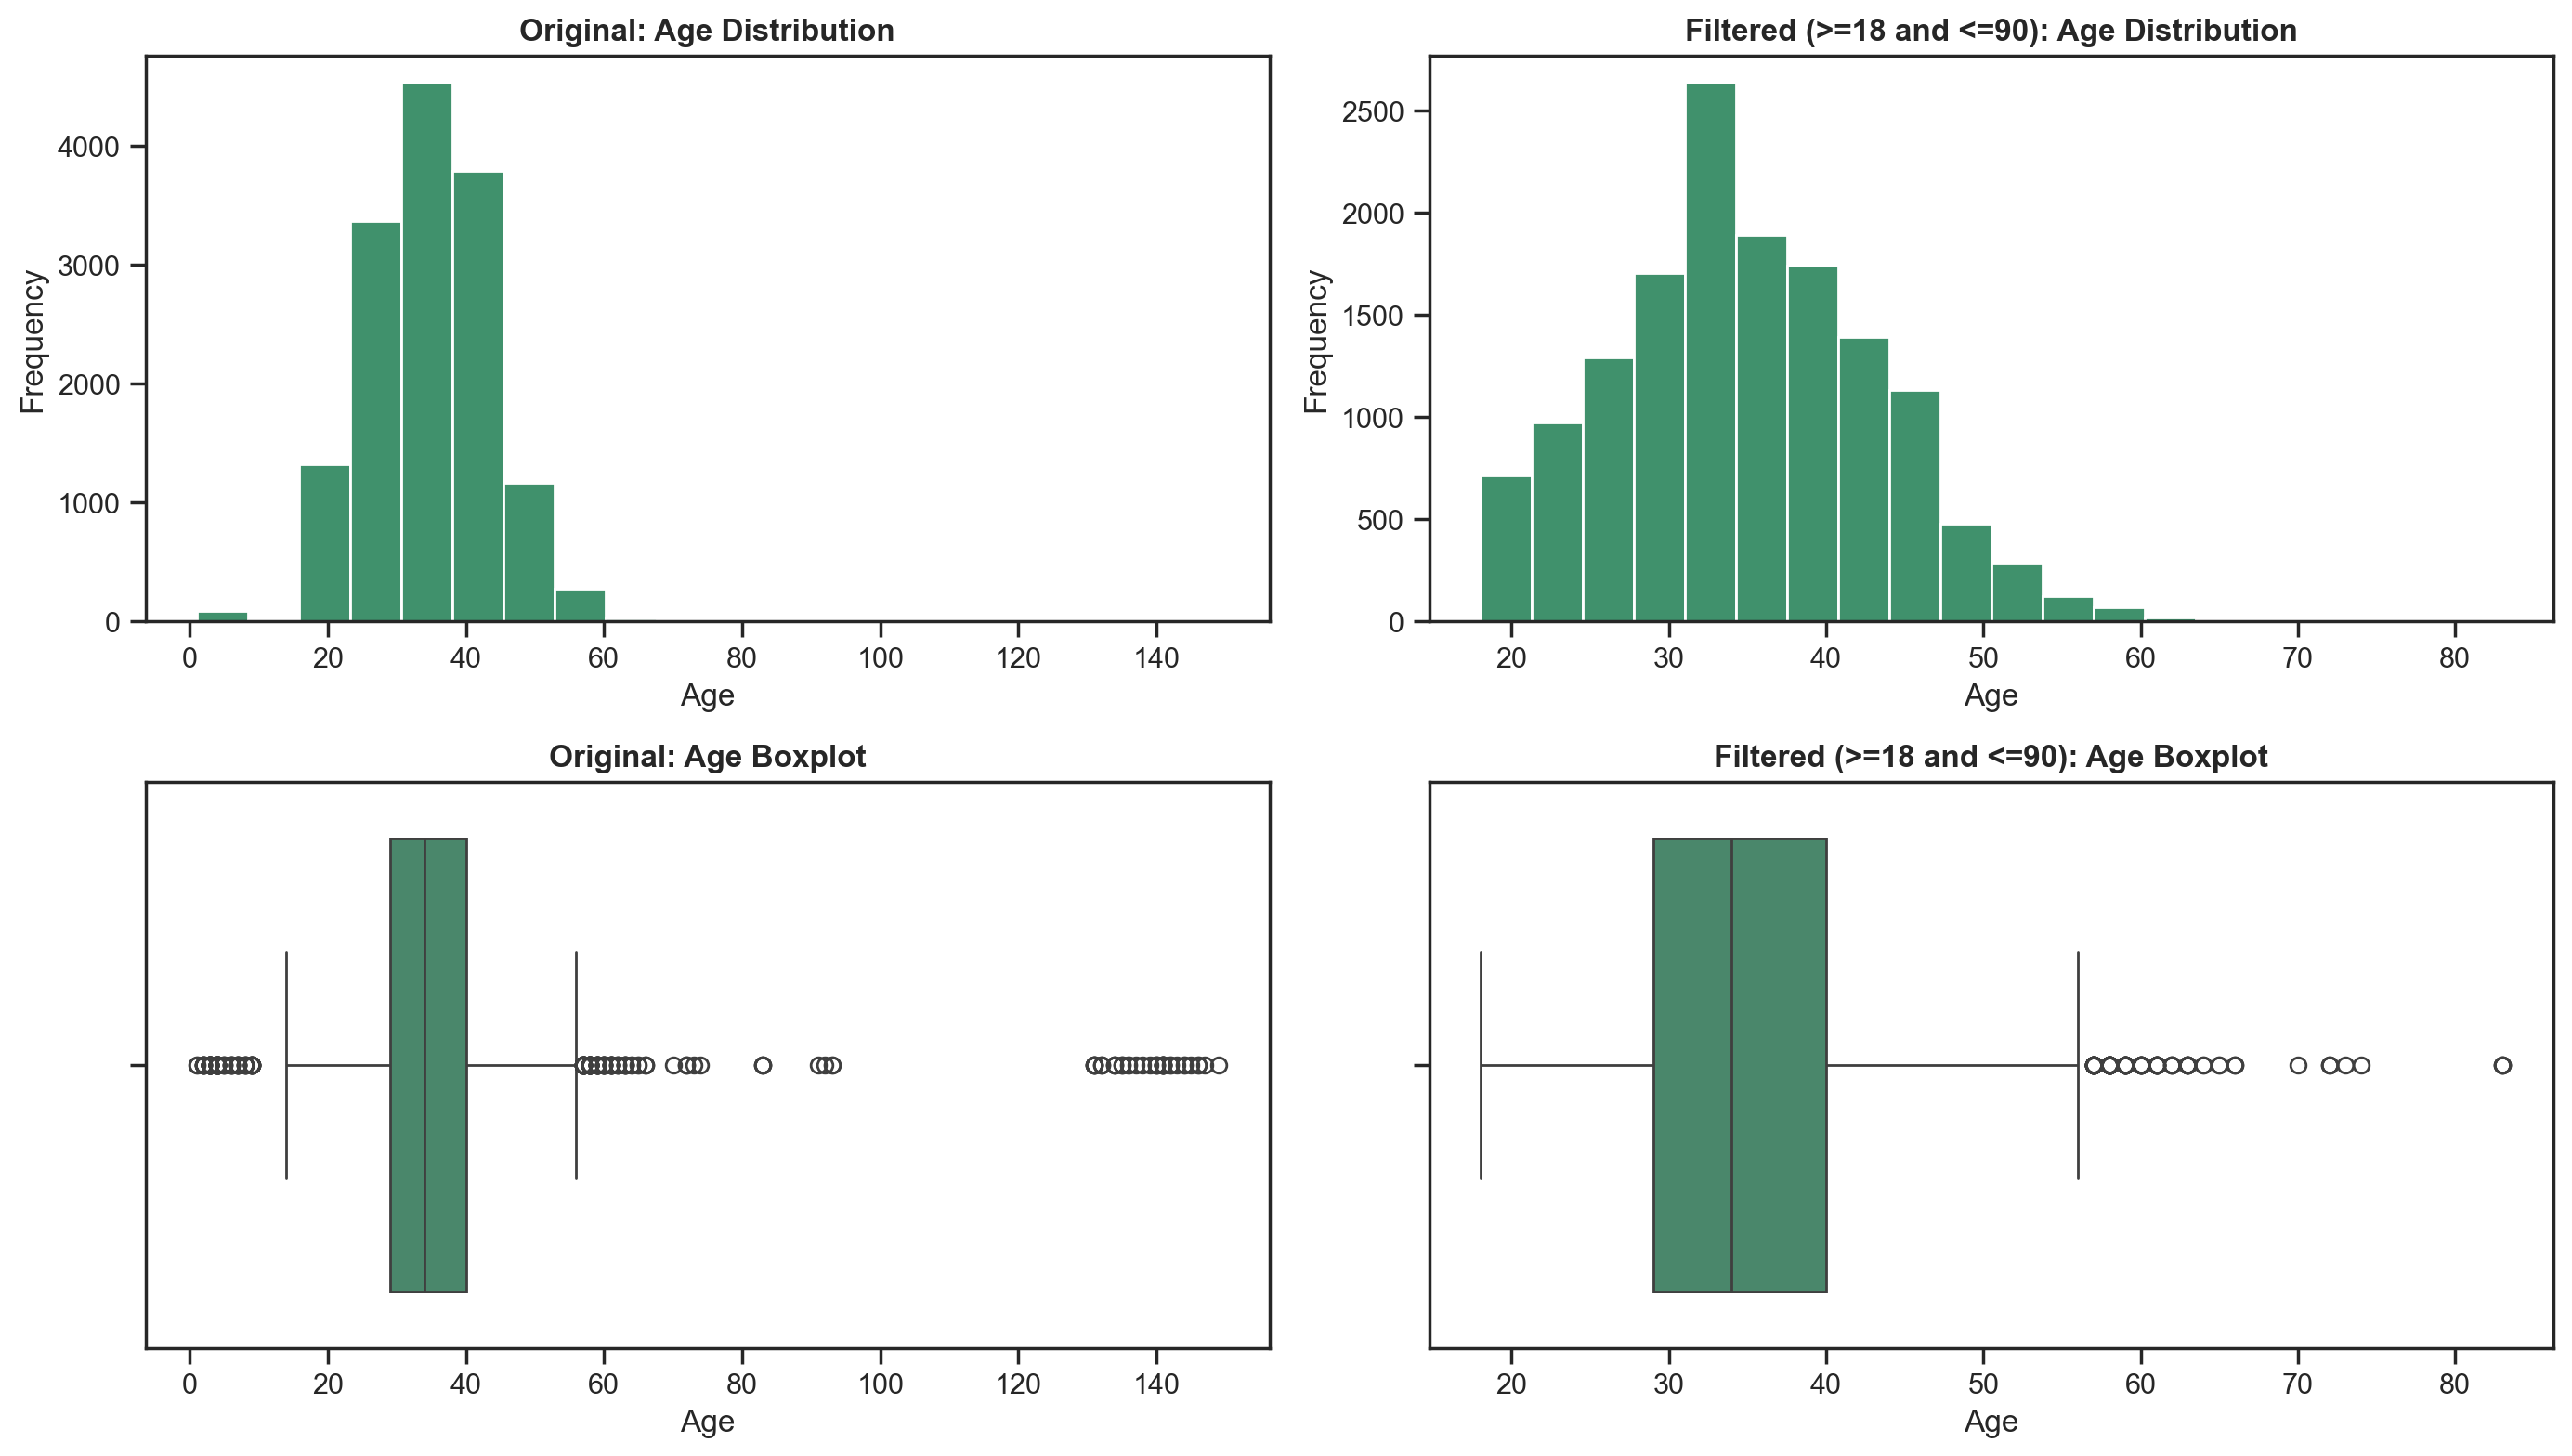

In [21]:
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, 
        2, 
        figsize=subplot_figsize)

df_age_filtered = df_nodups[(df_nodups["age"] > 17) & (df_nodups["age"] < 91)]

axes[0, 0].hist(df_nodups["age"].dropna(), bins=20, color=main_color)
axes[0, 1].hist(df_age_filtered["age"].dropna(), bins=20, color=main_color)

sns.boxplot(x=df_nodups["age"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_age_filtered["age"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Age Distribution', fontweight="bold") 
axes[0, 0].set_xlabel('Age')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Filtered (>=18 and <=90): Age Distribution', fontweight="bold") 
axes[0, 1].set_xlabel('Age')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Age Boxplot', fontweight="bold") 
axes[1, 0].set_xlabel('Age')

axes[1, 1].set_title('Filtered (>=18 and <=90): Age Boxplot', fontweight="bold") 
axes[1, 1].set_xlabel('Age')

plt.tight_layout()
plt.show()

After filtering, most customers are between about 29 and 40 years old, with a median of around 34, and the distribution is slightly right-skewed: the number of customers decreases as age increases. The boxplot shows some older customers (up to about 83) as outliers, but they are few and plausible. In the original plots, the invalid ages (below 15 and above 130) are clearly separated from the rest of the data, which supports our decision to filter them out.

<b><font size="4" color="#FAA85E">6.1.2. `n_colleagues_on_account`</font></b><br>

In [22]:
n_zero = (df_nodups["n_colleagues_on_account"] == 0).sum()
n_negative = (df_nodups["n_colleagues_on_account"] < 0).sum()

print(f"Customers with 0 colleagues: {n_zero}")
print(f"Customers with a negative value: {n_negative}")

pd.crosstab(
    df_nodups["n_colleagues_on_account"] > 0,
    df_nodups["is_team_account"],
    rownames=["colleagues > 0"],
    colnames=["is_team_account"],
    dropna=False
)

Customers with 0 colleagues: 10497
Customers with a negative value: 557


is_team_account,False,True
colleagues > 0,,
False,10905,149
True,0,4116


We compared `n_colleagues_on_account` with `is_team_account`:

- Every customer with at least one colleague on the account is a team account.
- However, there are 149 team accounts with no colleagues listed (value 0 or negative), so there are more team accounts (4265) than customers with at least one colleague (4116).

In [23]:
negatives = df_nodups.loc[df_nodups["n_colleagues_on_account"] < 0, "n_colleagues_on_account"]

print(negatives.unique())
print(negatives.value_counts())

[-1]
n_colleagues_on_account
-1    557
Name: count, dtype: int64


All the negative values of `n_colleagues_on_account` are equal to -1, which is probably a code for `NaN`.

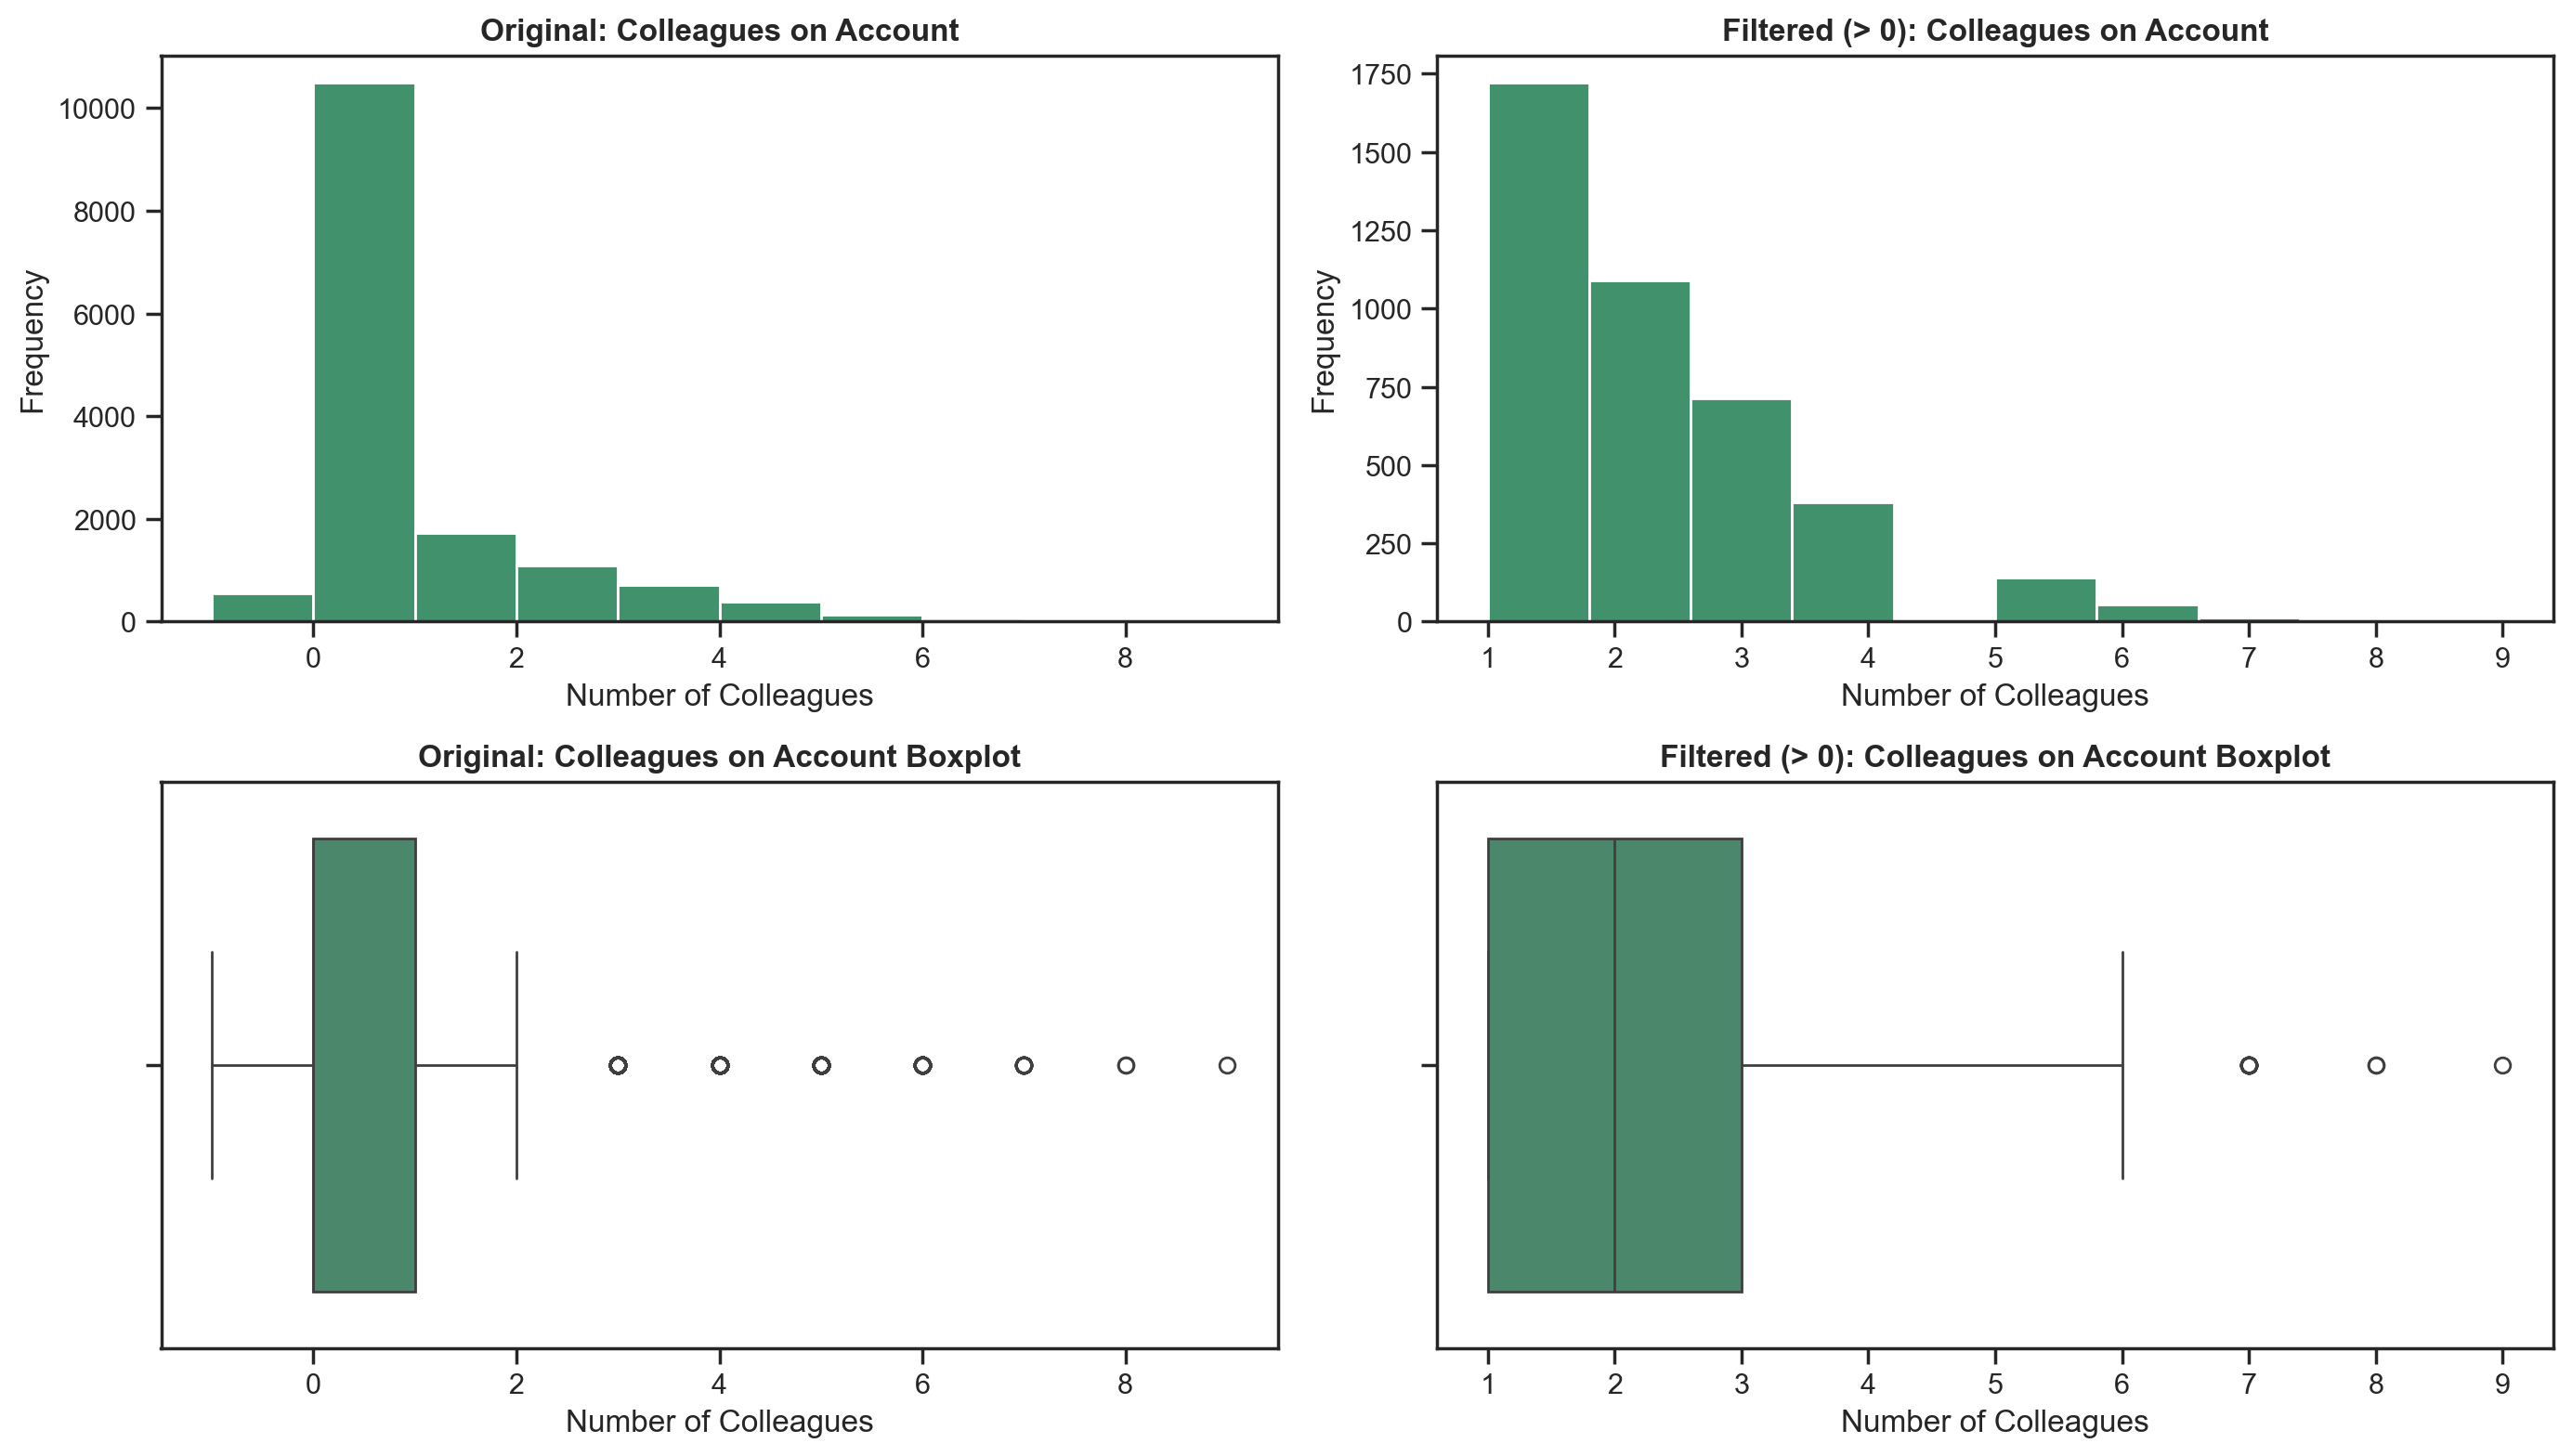

In [24]:
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, 
        2, 
        figsize=subplot_figsize)

df_colleagues_clean = df_nodups[df_nodups["n_colleagues_on_account"] > 0]

axes[0, 0].hist(df_nodups["n_colleagues_on_account"].dropna(), bins=10, color=main_color)
axes[0, 1].hist(df_colleagues_clean["n_colleagues_on_account"].dropna(), bins=10, color=main_color)
sns.boxplot(x=df_nodups["n_colleagues_on_account"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_colleagues_clean["n_colleagues_on_account"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Colleagues on Account', fontweight="bold") 
axes[0, 0].set_xlabel('Number of Colleagues')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Filtered (> 0): Colleagues on Account', fontweight="bold") 
axes[0, 1].set_xlabel('Number of Colleagues')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Colleagues on Account Boxplot', fontweight="bold") 
axes[1, 0].set_xlabel('Number of Colleagues')

axes[1, 1].set_title('Filtered (> 0): Colleagues on Account Boxplot', fontweight="bold") 
axes[1, 1].set_xlabel('Number of Colleagues')

plt.tight_layout()
plt.show()

Most customers have no colleagues on the account, so the distribution is strongly right-skewed. Among accounts with at least one colleague, the number drops quickly: most have 1 to 3 colleagues and larger teams (up to 9) are rare. The values 7, 8 and 9 appear as outliers in the boxplot, but they are plausible team sizes, so we keep them.

<b><font size="4" color="#FAA85E">6.1.3. `plan_days_per_week`</font></b><br>

In [25]:
df["plan_days_per_week"].unique()  

array([3, 2, 5, 7, 9, 0])

For this variable we keep only values `<= 7`, since a week cannot have more than 7 days (so the value 9 is excluded). The value 0 also does not make sense: a plan with 0 days per week would give no access to the space. The plans follow a logical order (2, 3, 5 and 7 days), so 0 is probably a data entry error.

In [26]:
zero_plan = df_nodups[df_nodups["plan_days_per_week"] == 0]

print(len(zero_plan))
print(zero_plan["plan_tier"].value_counts(dropna=False))

43
plan_tier
flex              20
hot_desk          14
full_time          5
dedicated_desk     3
private_office     1
Name: count, dtype: int64


All the zeros in `plan_days_per_week` belong to customers with a valid `plan_tier` (this variable has no missing values). Since each plan tier is tied to a number of days per week, we can probably recover the correct value from `plan_tier` later in the future, while handling invalid data.

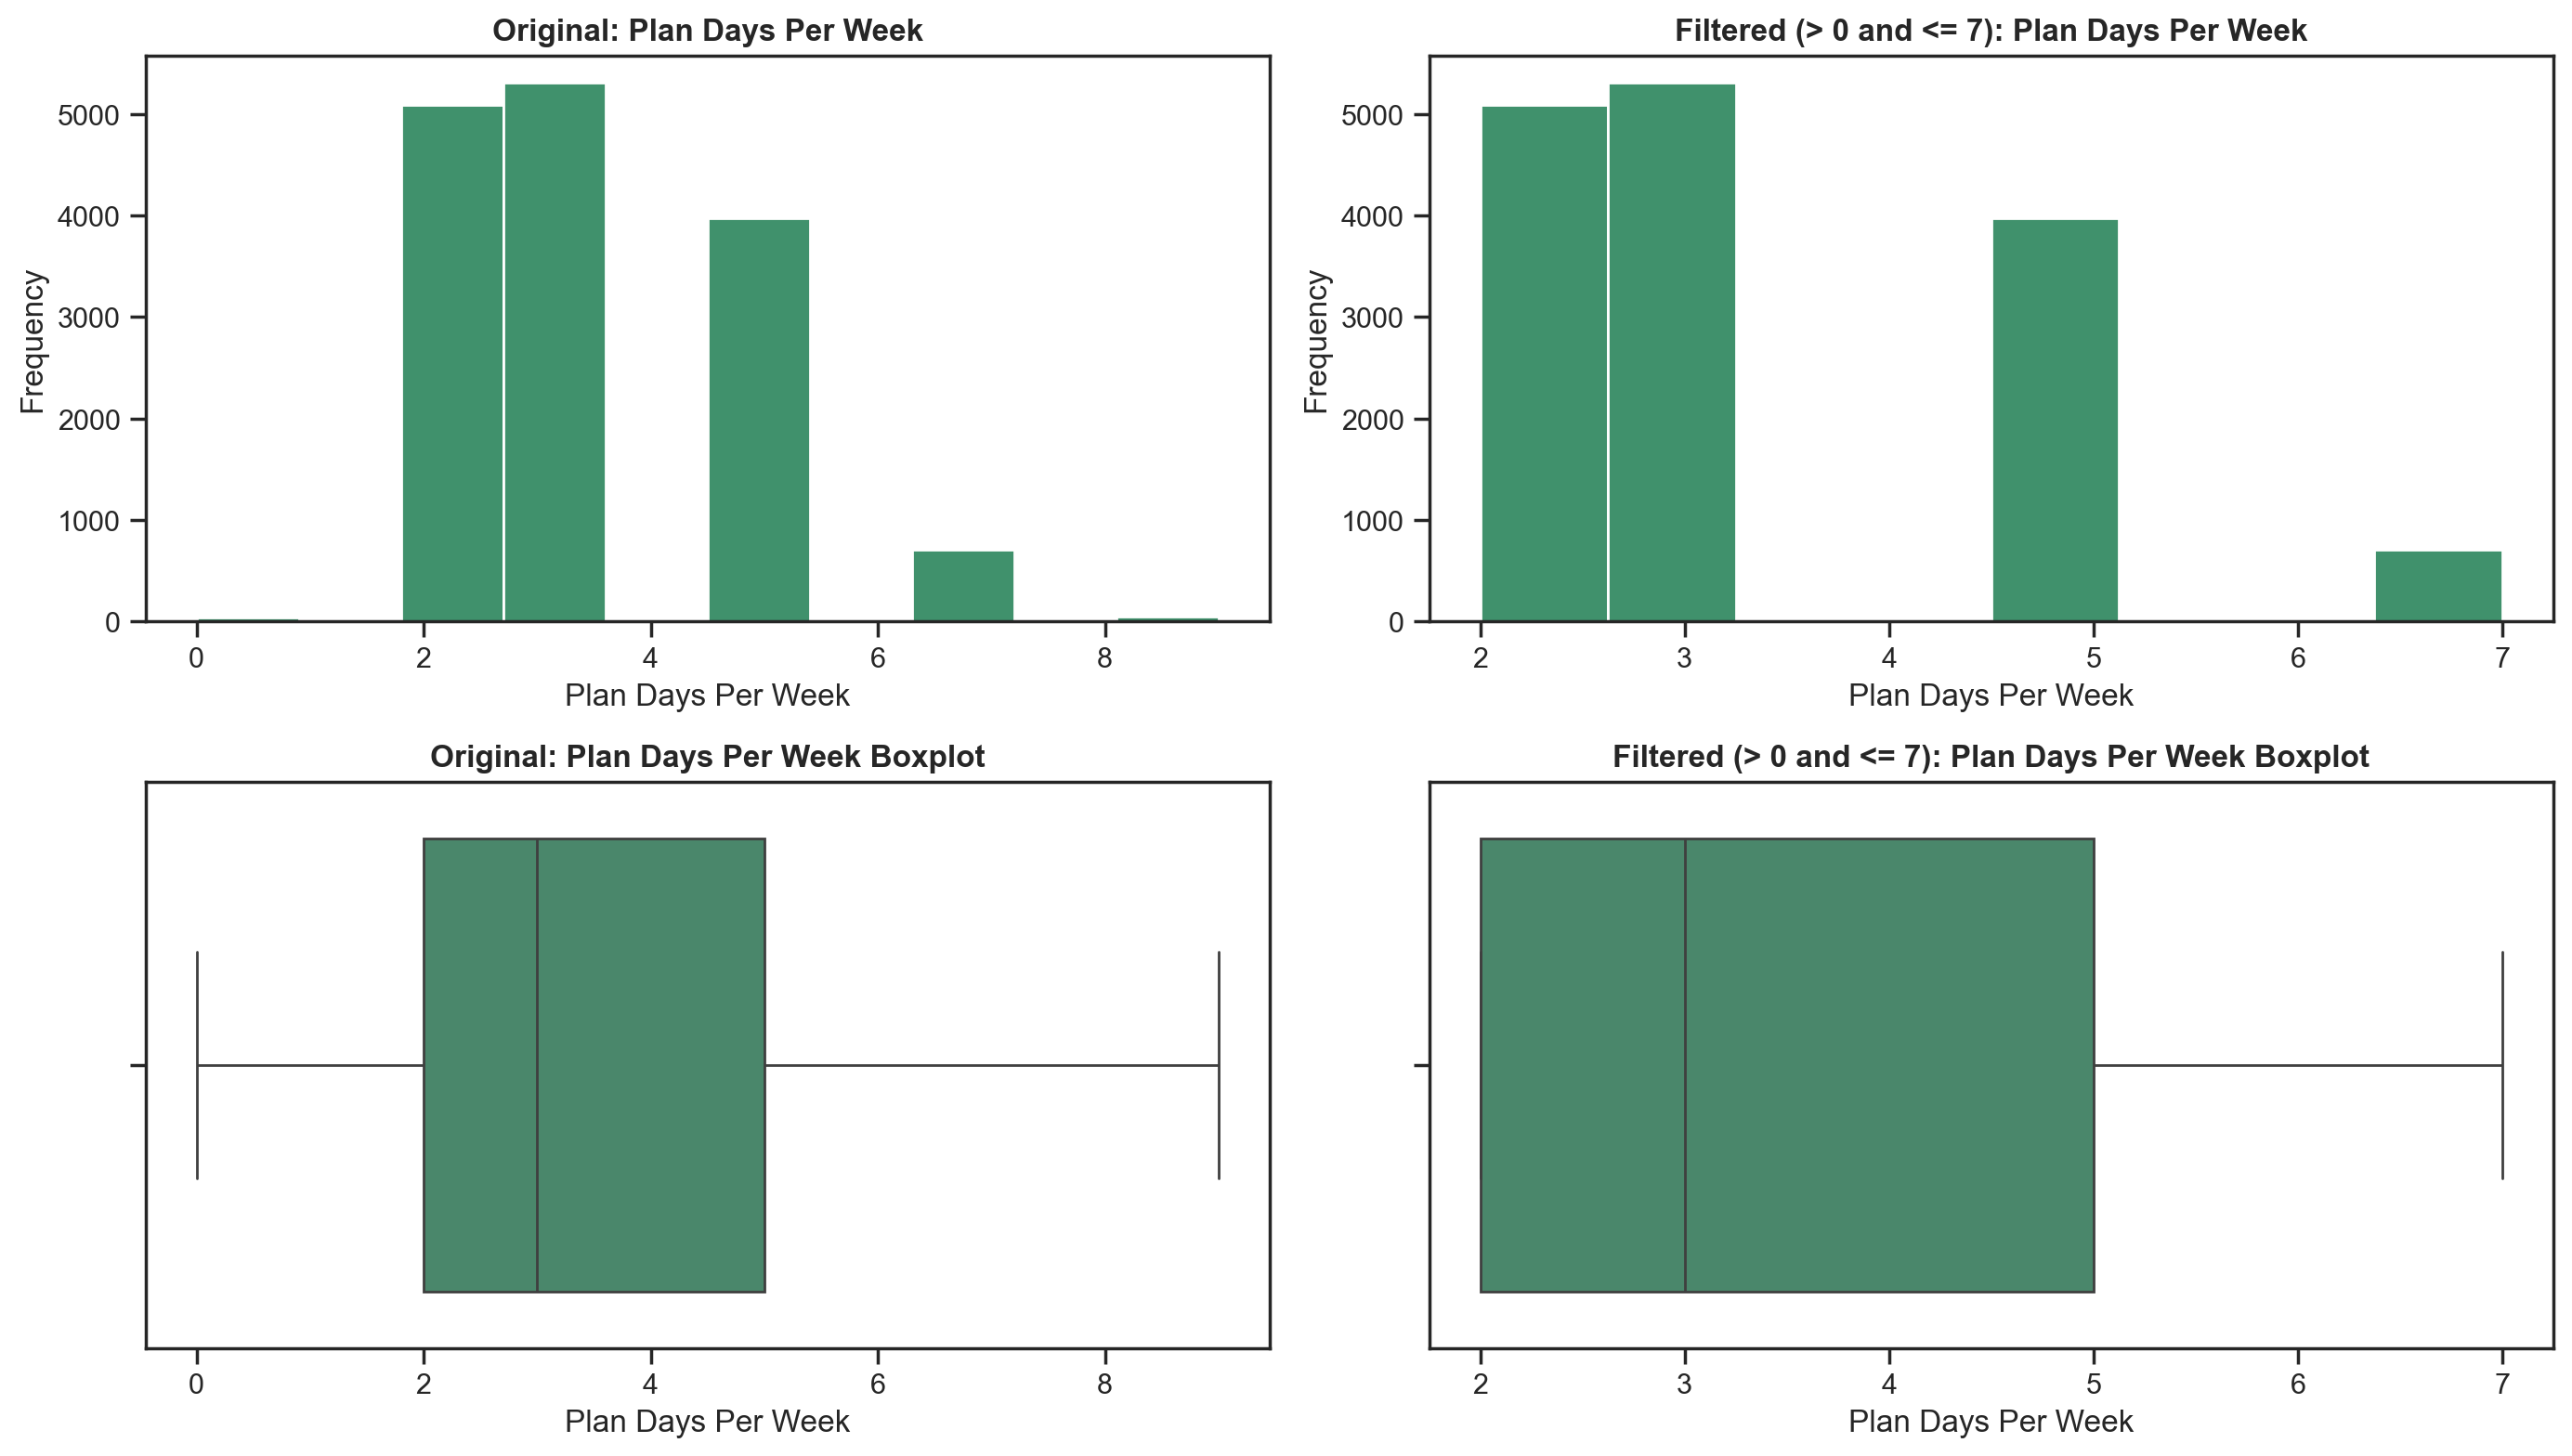

In [27]:
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, 
        2, 
        figsize=subplot_figsize)

df_plan_clean = df_nodups[(df_nodups["plan_days_per_week"] > 0) & (df_nodups["plan_days_per_week"] <= 7)]

axes[0, 0].hist(df_nodups["plan_days_per_week"].dropna(), bins=10, color=main_color)
axes[0, 1].hist(df_plan_clean["plan_days_per_week"].dropna(), bins=8, color=main_color)

sns.boxplot(x=df_nodups["plan_days_per_week"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_plan_clean["plan_days_per_week"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Plan Days Per Week', fontweight="bold") 
axes[0, 0].set_xlabel('Plan Days Per Week')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Filtered (> 0 and <= 7): Plan Days Per Week', fontweight="bold") 
axes[0, 1].set_xlabel('Plan Days Per Week')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Plan Days Per Week Boxplot', fontweight="bold") 
axes[1, 0].set_xlabel('Plan Days Per Week')

axes[1, 1].set_title('Filtered (> 0 and <= 7): Plan Days Per Week Boxplot', fontweight="bold") 
axes[1, 1].set_xlabel('Plan Days Per Week')

plt.tight_layout()
plt.show()

After removing the invalid values (0 and 9) for a better visualization, `plan_days_per_week` has only four possible values: 2, 3, 5 and 7, which are certainly related to the type of plan. Most customers choose plans with fewer days per week: plans with 2 or 3 days are the most common (about two thirds of the customers), followed by 5 days, while the 7-day plan is rare. This may suggest that a few days per week are enough for the needs of most customers, but we cannot confirm this from this variable alone.

Additionally, there are 5 plan types but only 4 possible values of plan days, so two plan types must share the same number of days. Since the number of customers tends to decrease as the number of days increases, it is likely that the shared value is 5 (probably `dedicated_desk` and `full_time`, according to the Metadata section). We can confirm this later by comparing both variables.

<b><font size="4" color="#FAA85E">6.1.4. `days_since_last_visit`</font></b><br>

In [28]:
s = df_nodups["days_since_last_visit"].dropna()

pd.DataFrame({
    "days_since_last_visit": {
        "min": s.min(),
        "% zeros": (s == 0).mean() * 100,
        "median": s.median(),
        "p90": s.quantile(0.90),
        "p99": s.quantile(0.99),
        "max": s.max()
    }
}).T.round(1)

,min,% zeros,median,p90,p99,max
days_since_last_visit,-956.0,0.6,13.0,263.0,999.0,1212.0


In [29]:
# Highest values and how often they appear
s.value_counts().sort_index(ascending=False).head(10)

days_since_last_visit
1212       1
1147       1
1004       1
1003       1
1002       1
1001       1
999     1272
997        1
946        1
921        1
Name: count, dtype: int64

For this variable, we filtered out the negative values (0.6%), since they are impossible. The value 999 is clearly special: it appears 1272 times, while every other large value appears only once. This suggests that 999 is a placeholder code and not a real number of days. We do not know yet what it means, but we can start taking a look:

In [30]:
days_999 = (df_nodups['days_since_last_visit'] == 999)

cols_dates = ['customer_id', 'days_since_last_visit', 'membership_end', 'last_badge_swipe']
cols = [col for col in cols_dates if col in df_nodups.columns]

display(df_nodups.loc[days_999, cols].head(15))

if 'last_badge_swipe' in df_nodups.columns:
    print(f"NaN in last_badge_swipe and days_since_last_visit = 999: {df_nodups.loc[days_999, 'last_badge_swipe'].isna().sum()} of {days_999.sum()}")
    print(f"NaN in last_badge_swipe and days_since_last_visit != 999: {df_nodups.loc[~days_999, 'last_badge_swipe'].isna().sum()} of {(~days_999).sum()}")

if 'membership_end' in df_nodups.columns:
    still_active = df_nodups['membership_end'] == pd.Timestamp("1970-01-01")
    print(f"Still active (membership_end = 1970-01-01) and days_since_last_visit = 999: {still_active[days_999].sum()} of {days_999.sum()}")
    print(f"Still active and days_since_last_visit != 999: {still_active[~days_999].sum()} of {(~days_999).sum()}")

# Other key variables: 999 vs the rest
cols_num = ["lifetime_value", "avg_weekly_visits", "n_renewals"]
df_nodups.assign(is_999=days_999).groupby("is_999")[cols_num].agg(["mean", "median"]).round(2).T

,days_since_last_visit,membership_end,last_badge_swipe
member_id,,,
CW000044,999,2023-06-07,2023-04-19
CW000058,999,1970-01-01,2023-12-28
CW000080,999,2023-12-02,2023-11-27
CW000085,999,2023-05-07,2023-03-14
CW000092,999,2021-09-08,2021-08-02
CW000104,999,2023-07-08,2023-05-21
CW000144,999,2023-03-16,2023-01-27
CW000145,999,2023-10-14,2023-10-11
CW000157,999,1970-01-01,2023-12-23


NaN in last_badge_swipe and days_since_last_visit = 999: 0 of 1272
NaN in last_badge_swipe and days_since_last_visit != 999: 0 of 13898
Still active (membership_end = 1970-01-01) and days_since_last_visit = 999: 367 of 1272
Still active and days_since_last_visit != 999: 3518 of 13898


is_999                      False  True 
lifetime_value    mean    7099.20   8.92
                  median  1426.22   0.00
avg_weekly_visits mean       1.81   1.36
                  median     1.50   0.95
n_renewals        mean       1.02   0.86
                  median     1.00   0.00

The 999 customers do have a registered `last_badge_swipe` (no missing values), so 999 does not mean "no visit registered". The main difference is financial: their `lifetime_value` is almost always 0 (median 0 vs 1426 for the other customers) and they have fewer renewals (median 0 vs 1). Their weekly visits are somewhat lower (median 0.95 vs 1.50), but not zero, and the share of still active memberships is similar (29% vs 25%). 

So 999 is probably a code for customers with no recorded value (for example, no payments registered), where `days_since_last_visit` was not computed. We keep it separate from real values in the analysis, so we can visualize better its distribution:

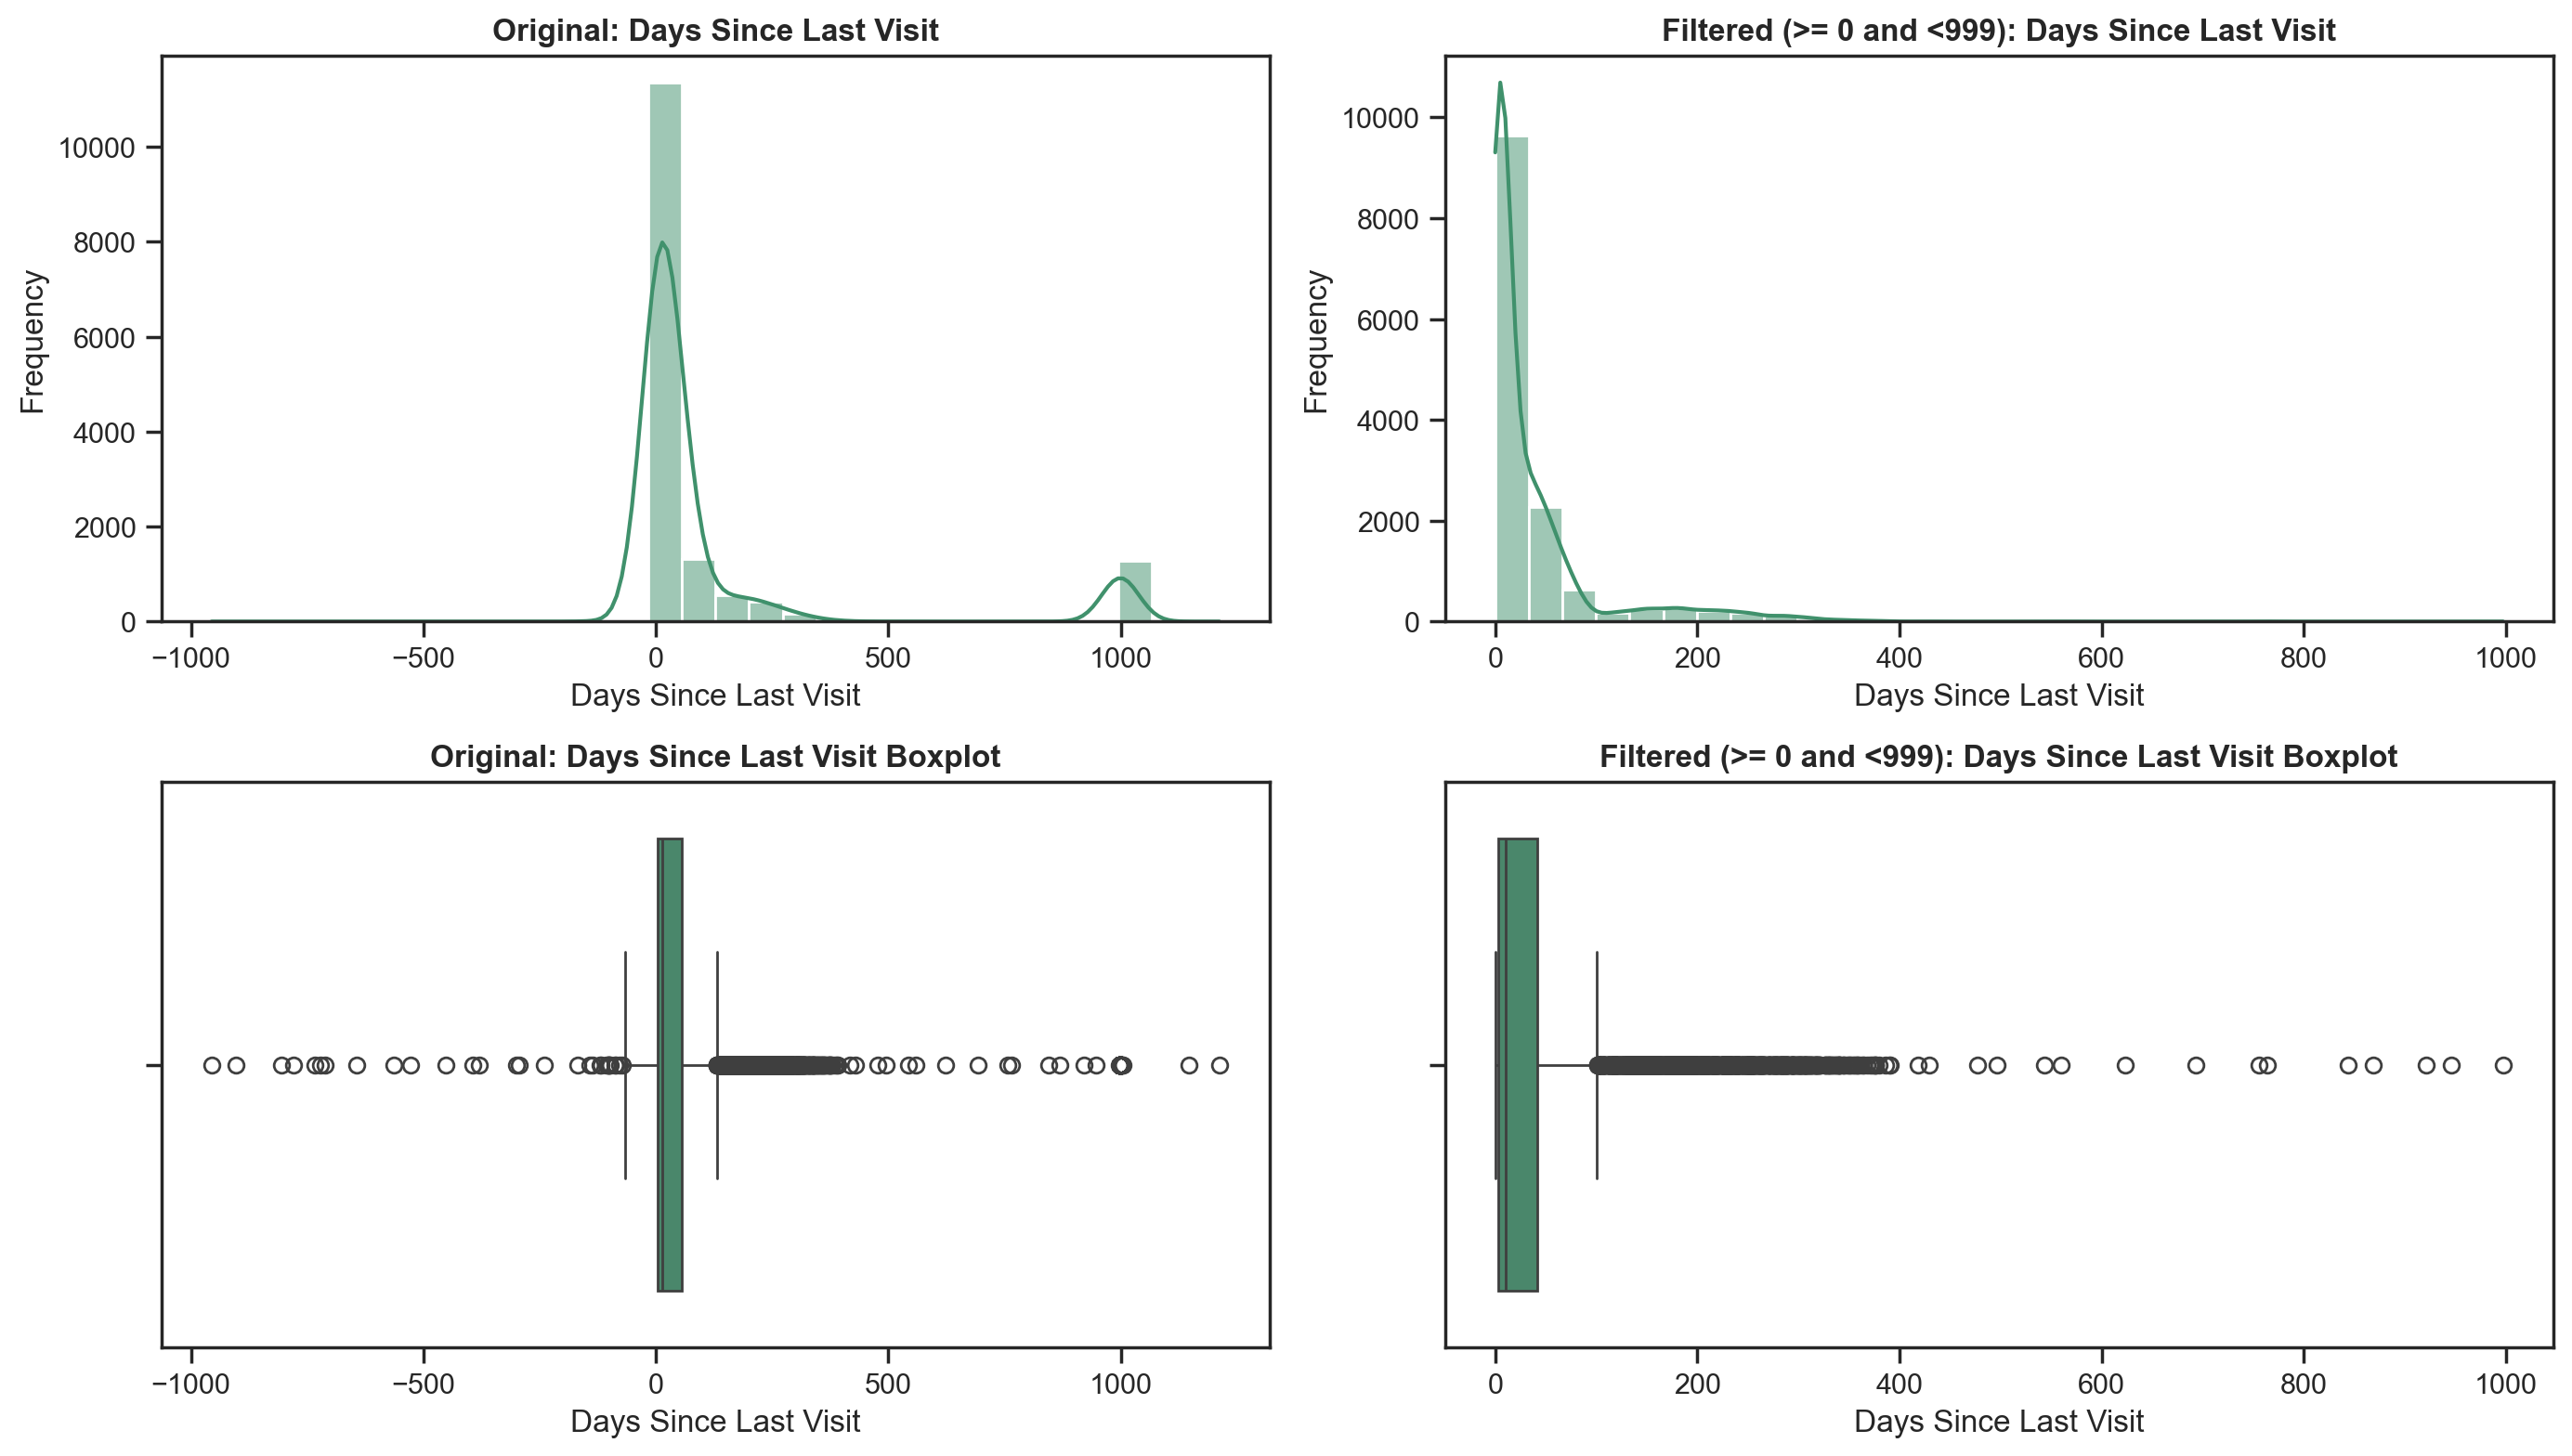

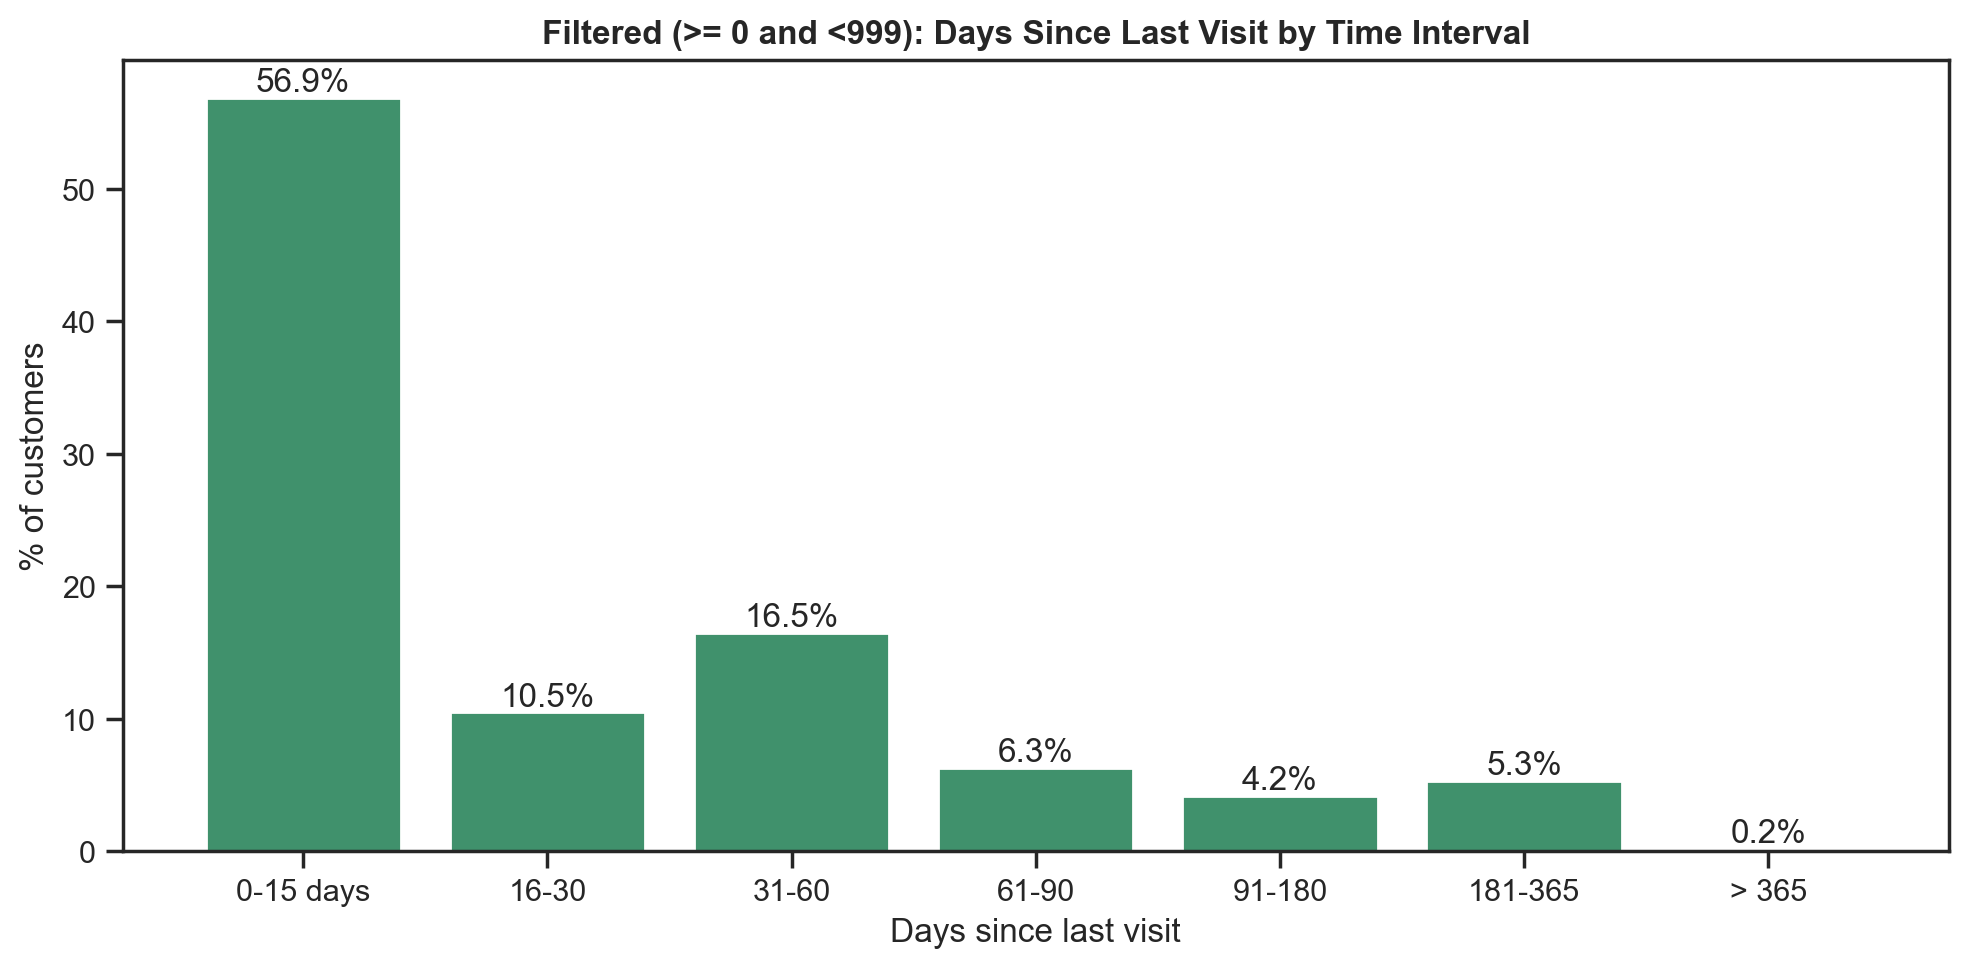

In [31]:
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

df_recency_clean = df_nodups[(df_nodups["days_since_last_visit"] >= 0) & (df_nodups["days_since_last_visit"] < 999)]

sns.histplot(df_nodups["days_since_last_visit"].dropna(), bins=30, color=main_color, kde=True, ax=axes[0, 0])
sns.histplot(df_recency_clean["days_since_last_visit"].dropna(), bins=30, color=main_color, kde=True, ax=axes[0, 1])

sns.boxplot(x=df_nodups["days_since_last_visit"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_recency_clean["days_since_last_visit"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Days Since Last Visit', fontweight="bold")
axes[0, 0].set_xlabel('Days Since Last Visit')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Filtered (>= 0 and <999): Days Since Last Visit', fontweight="bold")
axes[0, 1].set_xlabel('Days Since Last Visit')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Days Since Last Visit Boxplot', fontweight="bold")
axes[1, 0].set_xlabel('Days Since Last Visit')

axes[1, 1].set_title('Filtered (>= 0 and <999): Days Since Last Visit Boxplot', fontweight="bold")
axes[1, 1].set_xlabel('Days Since Last Visit')

plt.tight_layout()
plt.show()

# Intermediate plot: time intervals
bins = [-1, 15, 30, 60, 90, 180, 365, np.inf]
labels = ["0-15 days", "16-30", "31-60", "61-90", "91-180", "181-365", "> 365"]

visit_bins = pd.cut(df_recency_clean["days_since_last_visit"], bins=bins, labels=labels)
visit_pct = (visit_bins.value_counts(normalize=True, sort=False) * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(visit_pct.index, visit_pct.values, color=main_color)

for i, v in enumerate(visit_pct.values):
    ax.text(i, v + 0.5, f"{v}%", ha="center")

ax.set_title("Filtered (>= 0 and <999): Days Since Last Visit by Time Interval", fontweight="bold")
ax.set_xlabel("Days since last visit")
ax.set_ylabel("% of customers")

plt.tight_layout()
plt.show()

In [32]:
snapshot = pd.Timestamp("2024-01-01")

print("Latest membership_start:", df_nodups["membership_start"].max())

# % of customers who joined in the last 15 days
recent_start = df_nodups["membership_start"] >= snapshot - pd.Timedelta(days=15)
print(f"Joined in the last 15 days: {recent_start.mean() * 100:.1f}%")

Latest membership_start: 2023-12-30 00:00:00
Joined in the last 15 days: 2.3%


Since the distribution is strongly right-skewed, we also grouped the values into time intervals. We checked what `days_since_last_visit` measures: for active customers it is the number of days between their last visit and the snapshot date, and for customers who already left it is the number of days between their last visit and the end of their membership. So it is not "days until today" for everyone.

Among customers with valid information (excluding negative values and 999), most had visited the space within the last month before their reference date: about 57% within 15 days and about 67% within 30 days, and only about 10% had stopped visiting more than 3 months before. However, since plans are defined per week, even 15 days without a visit already means a gap of two weeks or more, so this does not necessarily mean regular use. This suggests that most customers had not completely stopped visiting before leaving (or before the snapshot date).

*Note: here, "active" only means that customers visited the space shortly before their reference date, and are not completely inactive. This variable does not tell us how often they go per week.*

<b><font size="4" color="#FAA85E">6.1.5. `total_visits`</font></b><br>

In [33]:
col = "total_visits"   

s = df_nodups[col].dropna()

pd.DataFrame({
    col: {
        "min": s.min(),
        "% zeros": (s == 0).mean() * 100,
        "median": s.median(),
        "p90": s.quantile(0.90),
        "p99": s.quantile(0.99),
        "max": s.max()
    }
}).T.round(1)

,min,% zeros,median,p90,p99,max
total_visits,-112.0,0.7,34.0,373.0,693.3,6530.0


For this variable, we filtered out the values that are < 0 (impossible). We also limited the plots to values up to 700 (about the 99th percentile), only for better visualization:

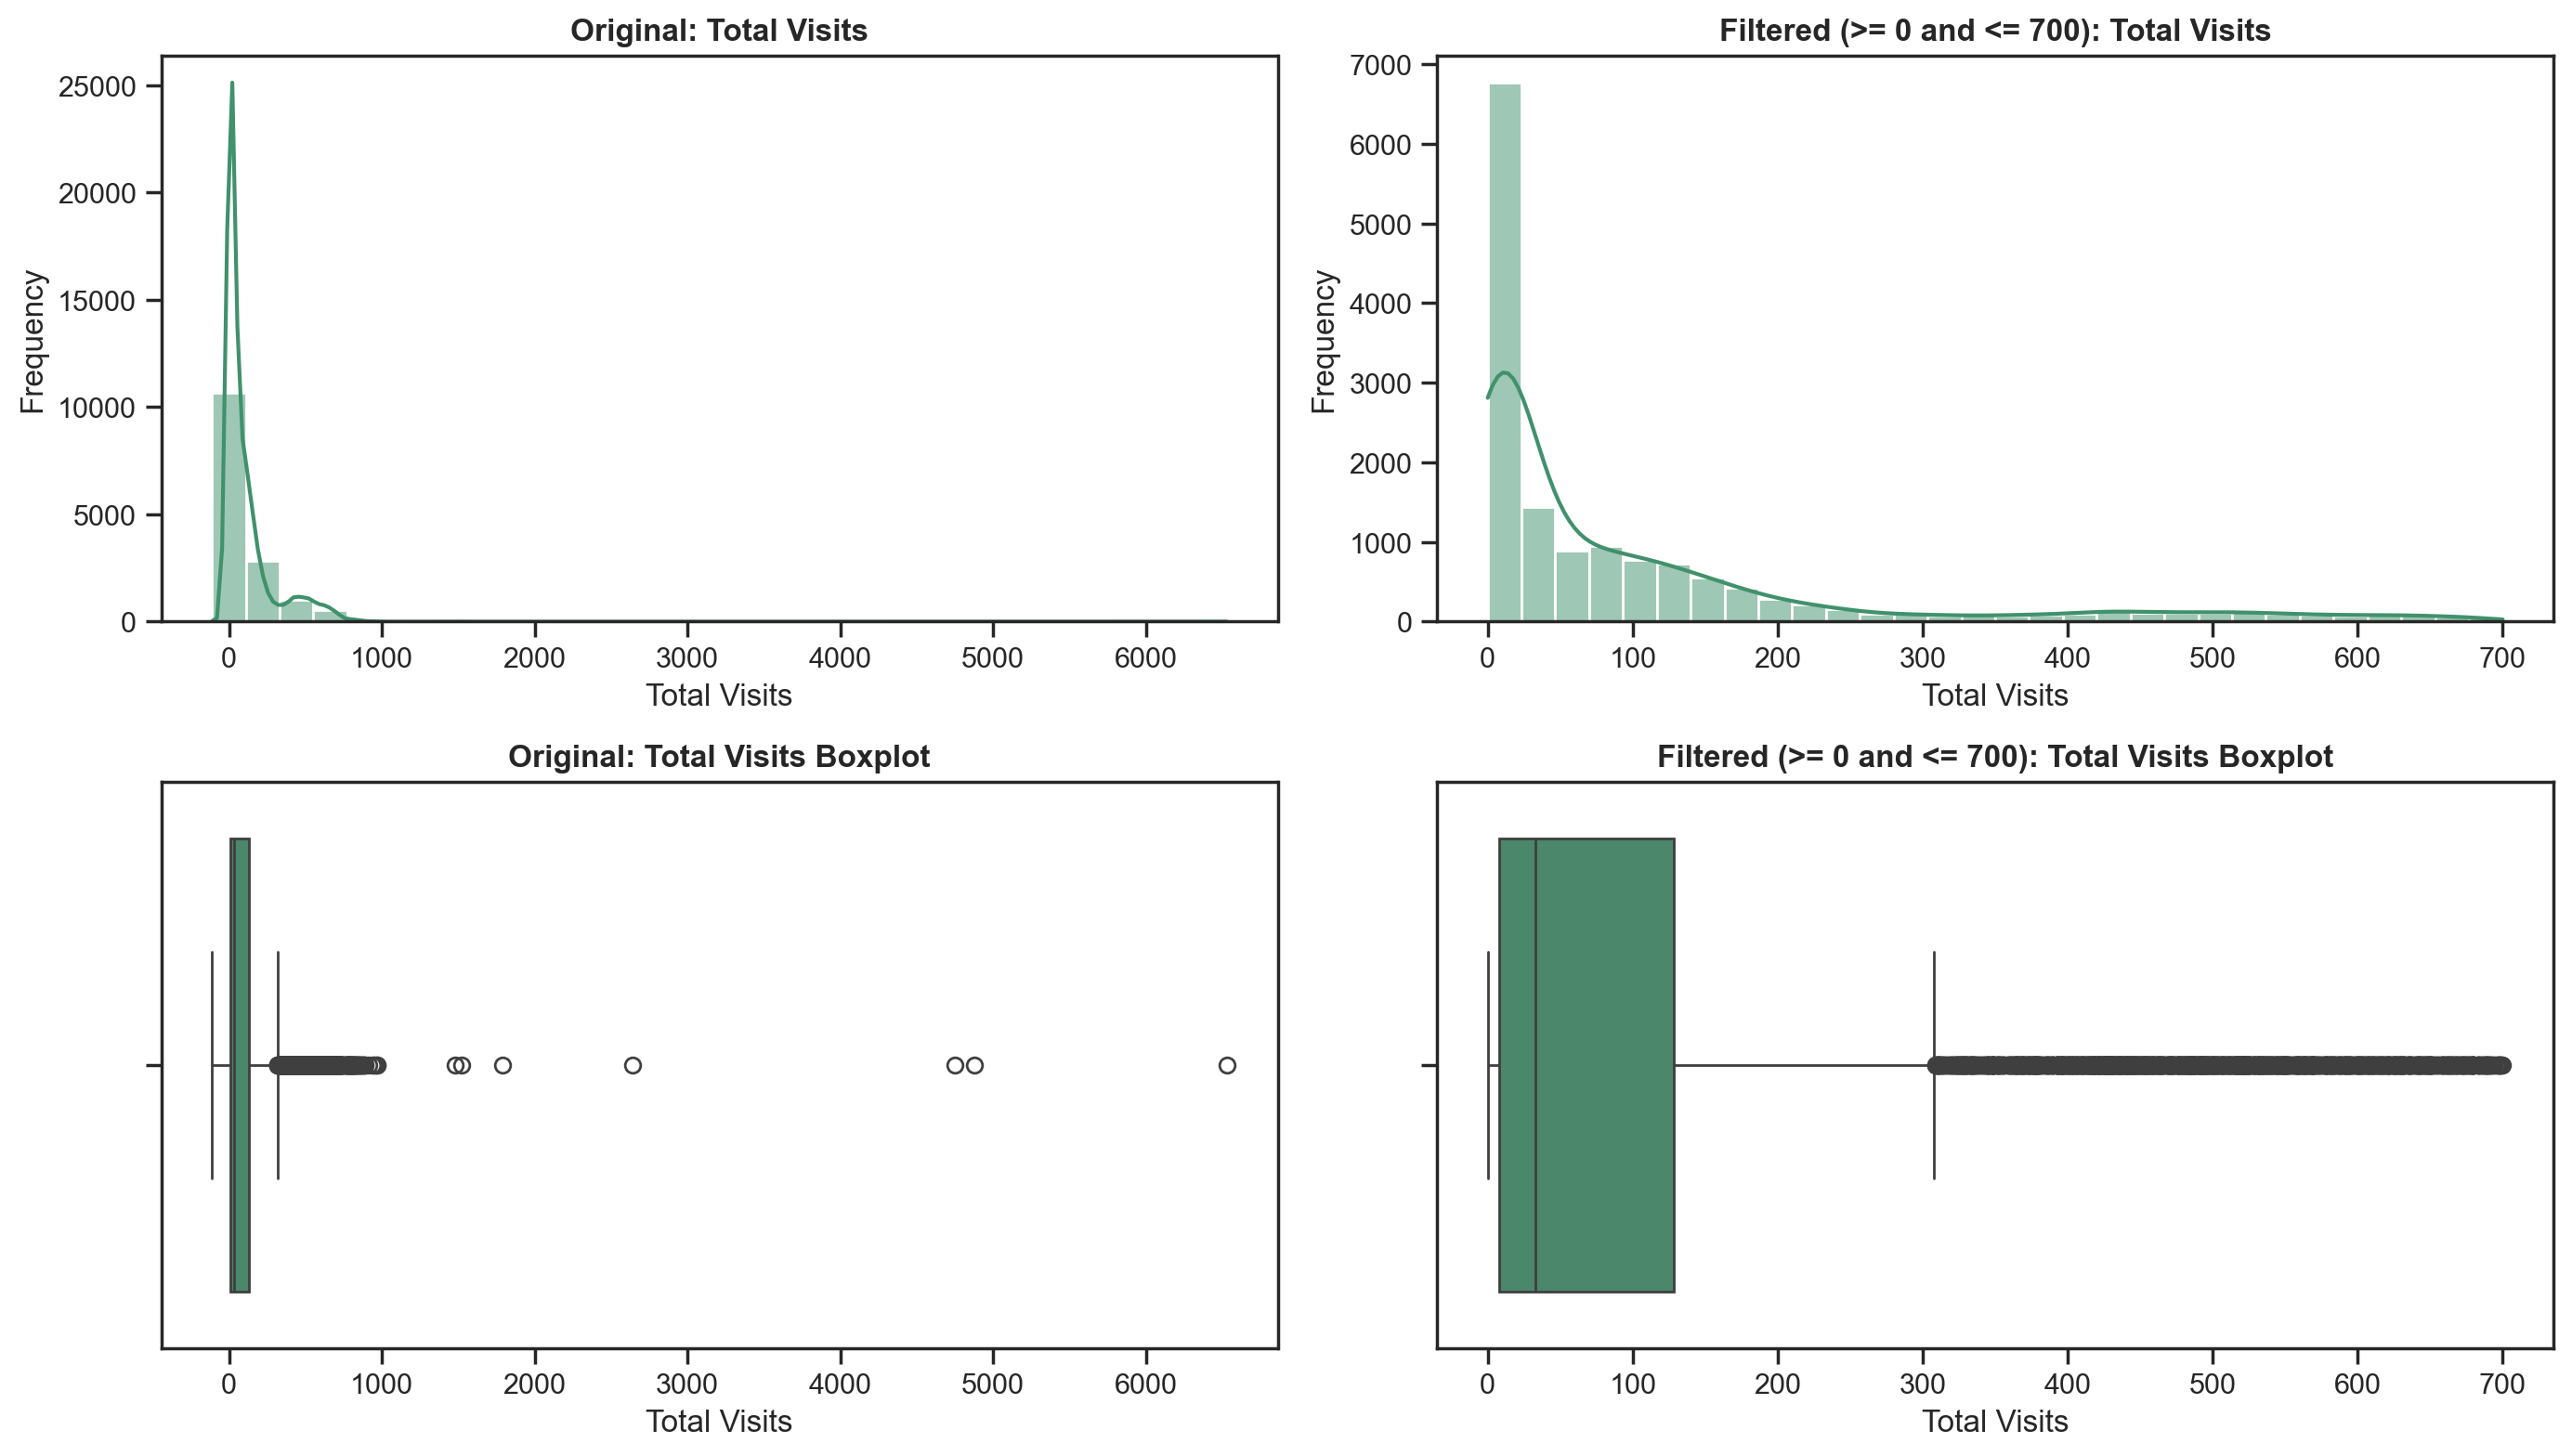

In [34]:
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

df_total_clean = df_nodups[(df_nodups["total_visits"] >= 0) & (df_nodups["total_visits"] <= 700)]

sns.histplot(df_nodups["total_visits"].dropna(), bins=30, color=main_color, kde=True, ax=axes[0, 0])
sns.histplot(df_total_clean["total_visits"].dropna(), bins=30, color=main_color, kde=True, ax=axes[0, 1])

sns.boxplot(x=df_nodups["total_visits"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_total_clean["total_visits"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Total Visits', fontweight="bold")
axes[0, 0].set_xlabel('Total Visits')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Filtered (>= 0 and <= 700): Total Visits', fontweight="bold")
axes[0, 1].set_xlabel('Total Visits')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Total Visits Boxplot', fontweight="bold")
axes[1, 0].set_xlabel('Total Visits')

axes[1, 1].set_title('Filtered (>= 0 and <= 700): Total Visits Boxplot', fontweight="bold")
axes[1, 1].set_xlabel('Total Visits')

plt.tight_layout()
plt.show()

The distribution of `total_visits` is also strongly right-skewed: most customers have a low number of visits (median 34), while a smaller group has a very high number (up to several hundred, and a few extreme cases above 700). So there is a large disparity between customers: some visit the space very often, others very rarely. Since this is a cumulative total, it also depends on how long each customer has been a member, and we do not know yet the distribution of the lowest values.

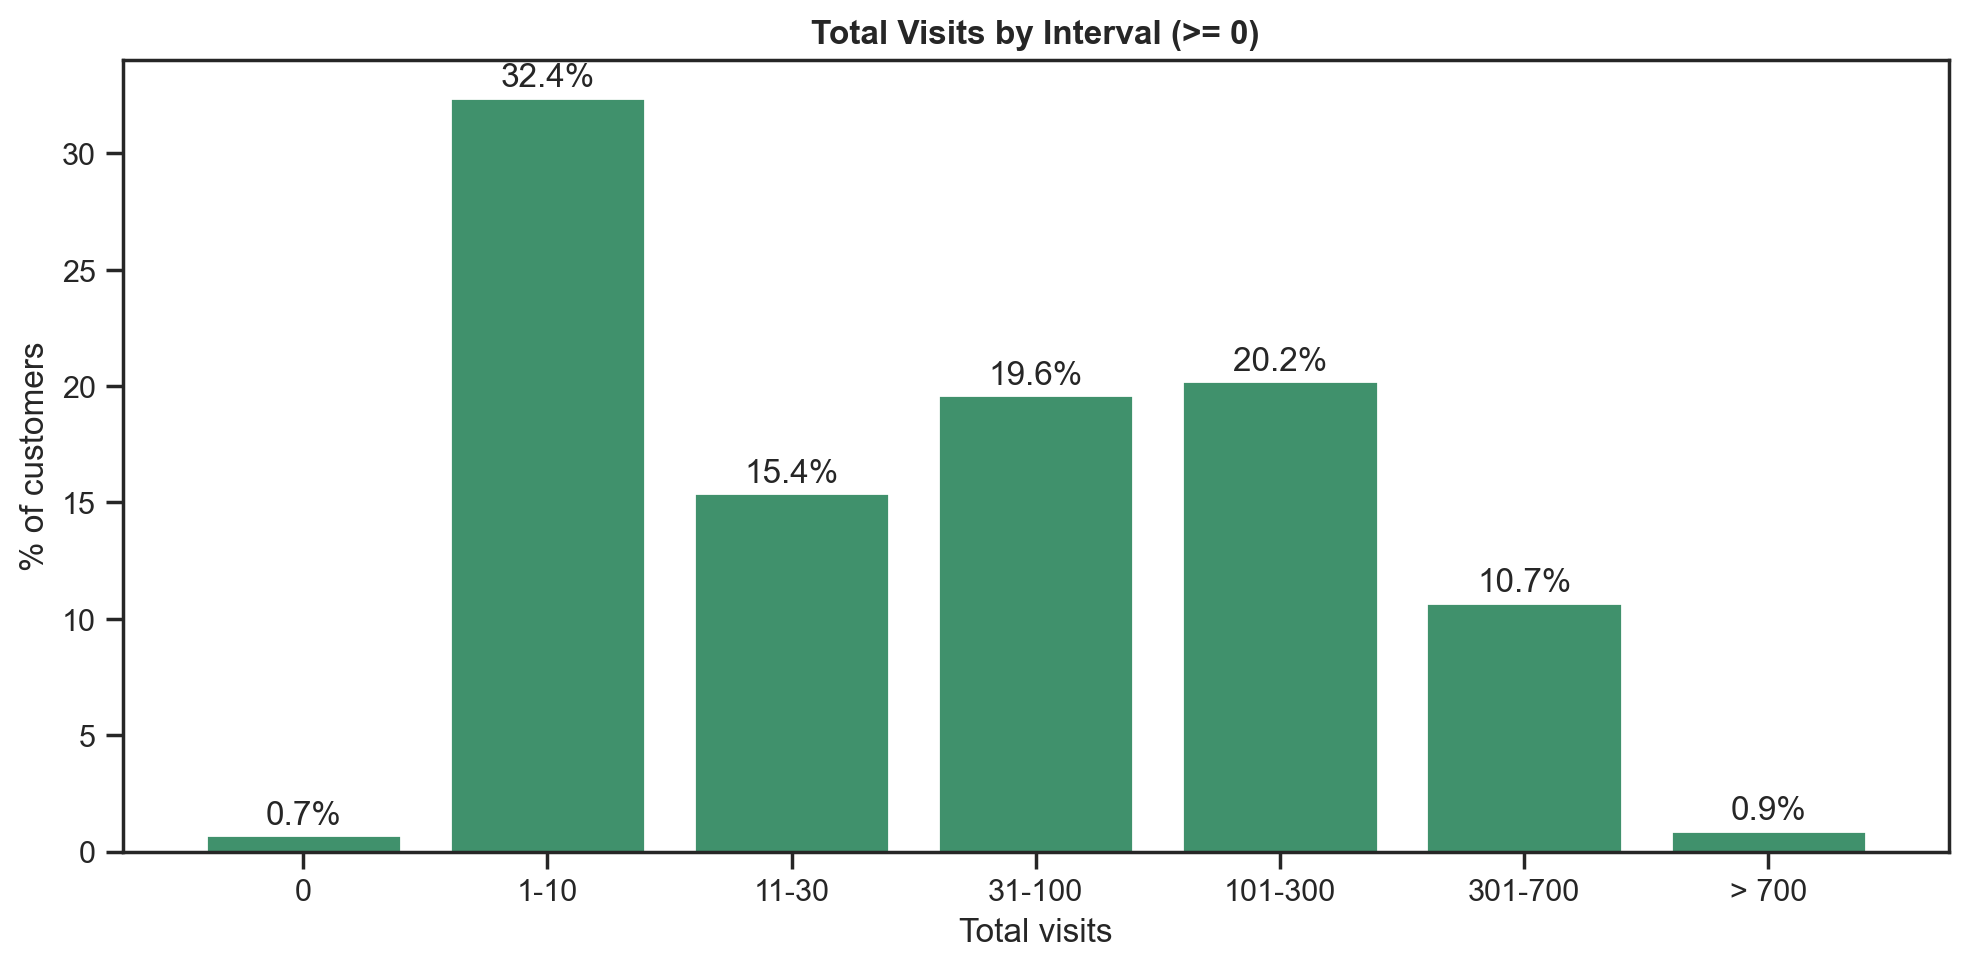

In [35]:
s = df_nodups["total_visits"]
s_valid = s[s >= 0]

bins = [-1, 0, 10, 30, 100, 300, 700, np.inf]
labels = ["0", "1-10", "11-30", "31-100", "101-300", "301-700", "> 700"]

visits_bins = pd.cut(s_valid, bins=bins, labels=labels)
visits_pct = (visits_bins.value_counts(normalize=True, sort=False) * 100).round(1)

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(visits_pct.index, visits_pct.values, color=main_color)

for i, v in enumerate(visits_pct.values):
    ax.text(i, v + 0.5, f"{v}%", ha="center")

ax.set_title("Total Visits by Interval (>= 0)", fontweight="bold")
ax.set_xlabel("Total visits")
ax.set_ylabel("% of customers")

plt.tight_layout()
plt.show()

Grouping `total_visits` into intervals, as we did before, gives a more detailed picture: customers are spread across the intervals, with no single dominant group. The largest group has only 1 to 10 visits (about 32%), about half of the customers have 30 visits or fewer, and about 32% have more than 100. Only 0.7% have no visits at all.

This slightly weakens the previous conclusion: many customers are "active" because they visited recently, but their total number of visits is low, so their activity may be occasional. It may also be explained by recent memberships, since this variable is cumulative.

A natural next step is to compare `total_visits` with the membership start date to look for behaviour patterns. We will do this in the bivariate analysis.

<b><font size="4" color="#FAA85E">6.1.6. `avg_weekly_visits`</font></b><br>

A way to get closer to an answer without necessarily using bivariate analysis is to analyse this variable properly. It measures how often customers go to the space per week, which `total_visits` and `days_since_last_visit` do not tell us.

In [36]:
col = "avg_weekly_visits"

s = df_nodups[col].dropna()

pd.DataFrame({
    col: {
        "min": s.min(),
        "% zeros": (s == 0).mean() * 100,
        "median": s.median(),
        "p90": s.quantile(0.90),
        "p99": s.quantile(0.99),
        "max": s.max()
    }
}).T.round(2)

,min,% zeros,median,p90,p99,max
avg_weekly_visits,0.0,0.09,1.42,3.83,5.32,47.4


For now, the median is 1.42 visits per week and $p_{90}$ = 3.83, so most customers go to the space only a few times per week. From the analysis of `plan_days_per_week`, we know that the smallest plan allows two days per week. Since the median is below two, this suggests that at least half of the customers use the space less than their plan allows. We will check this better by comparing each customer with their own plan.

The maximum 47.4 is impossible, since it means more than one visit per day. It will be treated as an invalid value, as well as any value greater than seven.

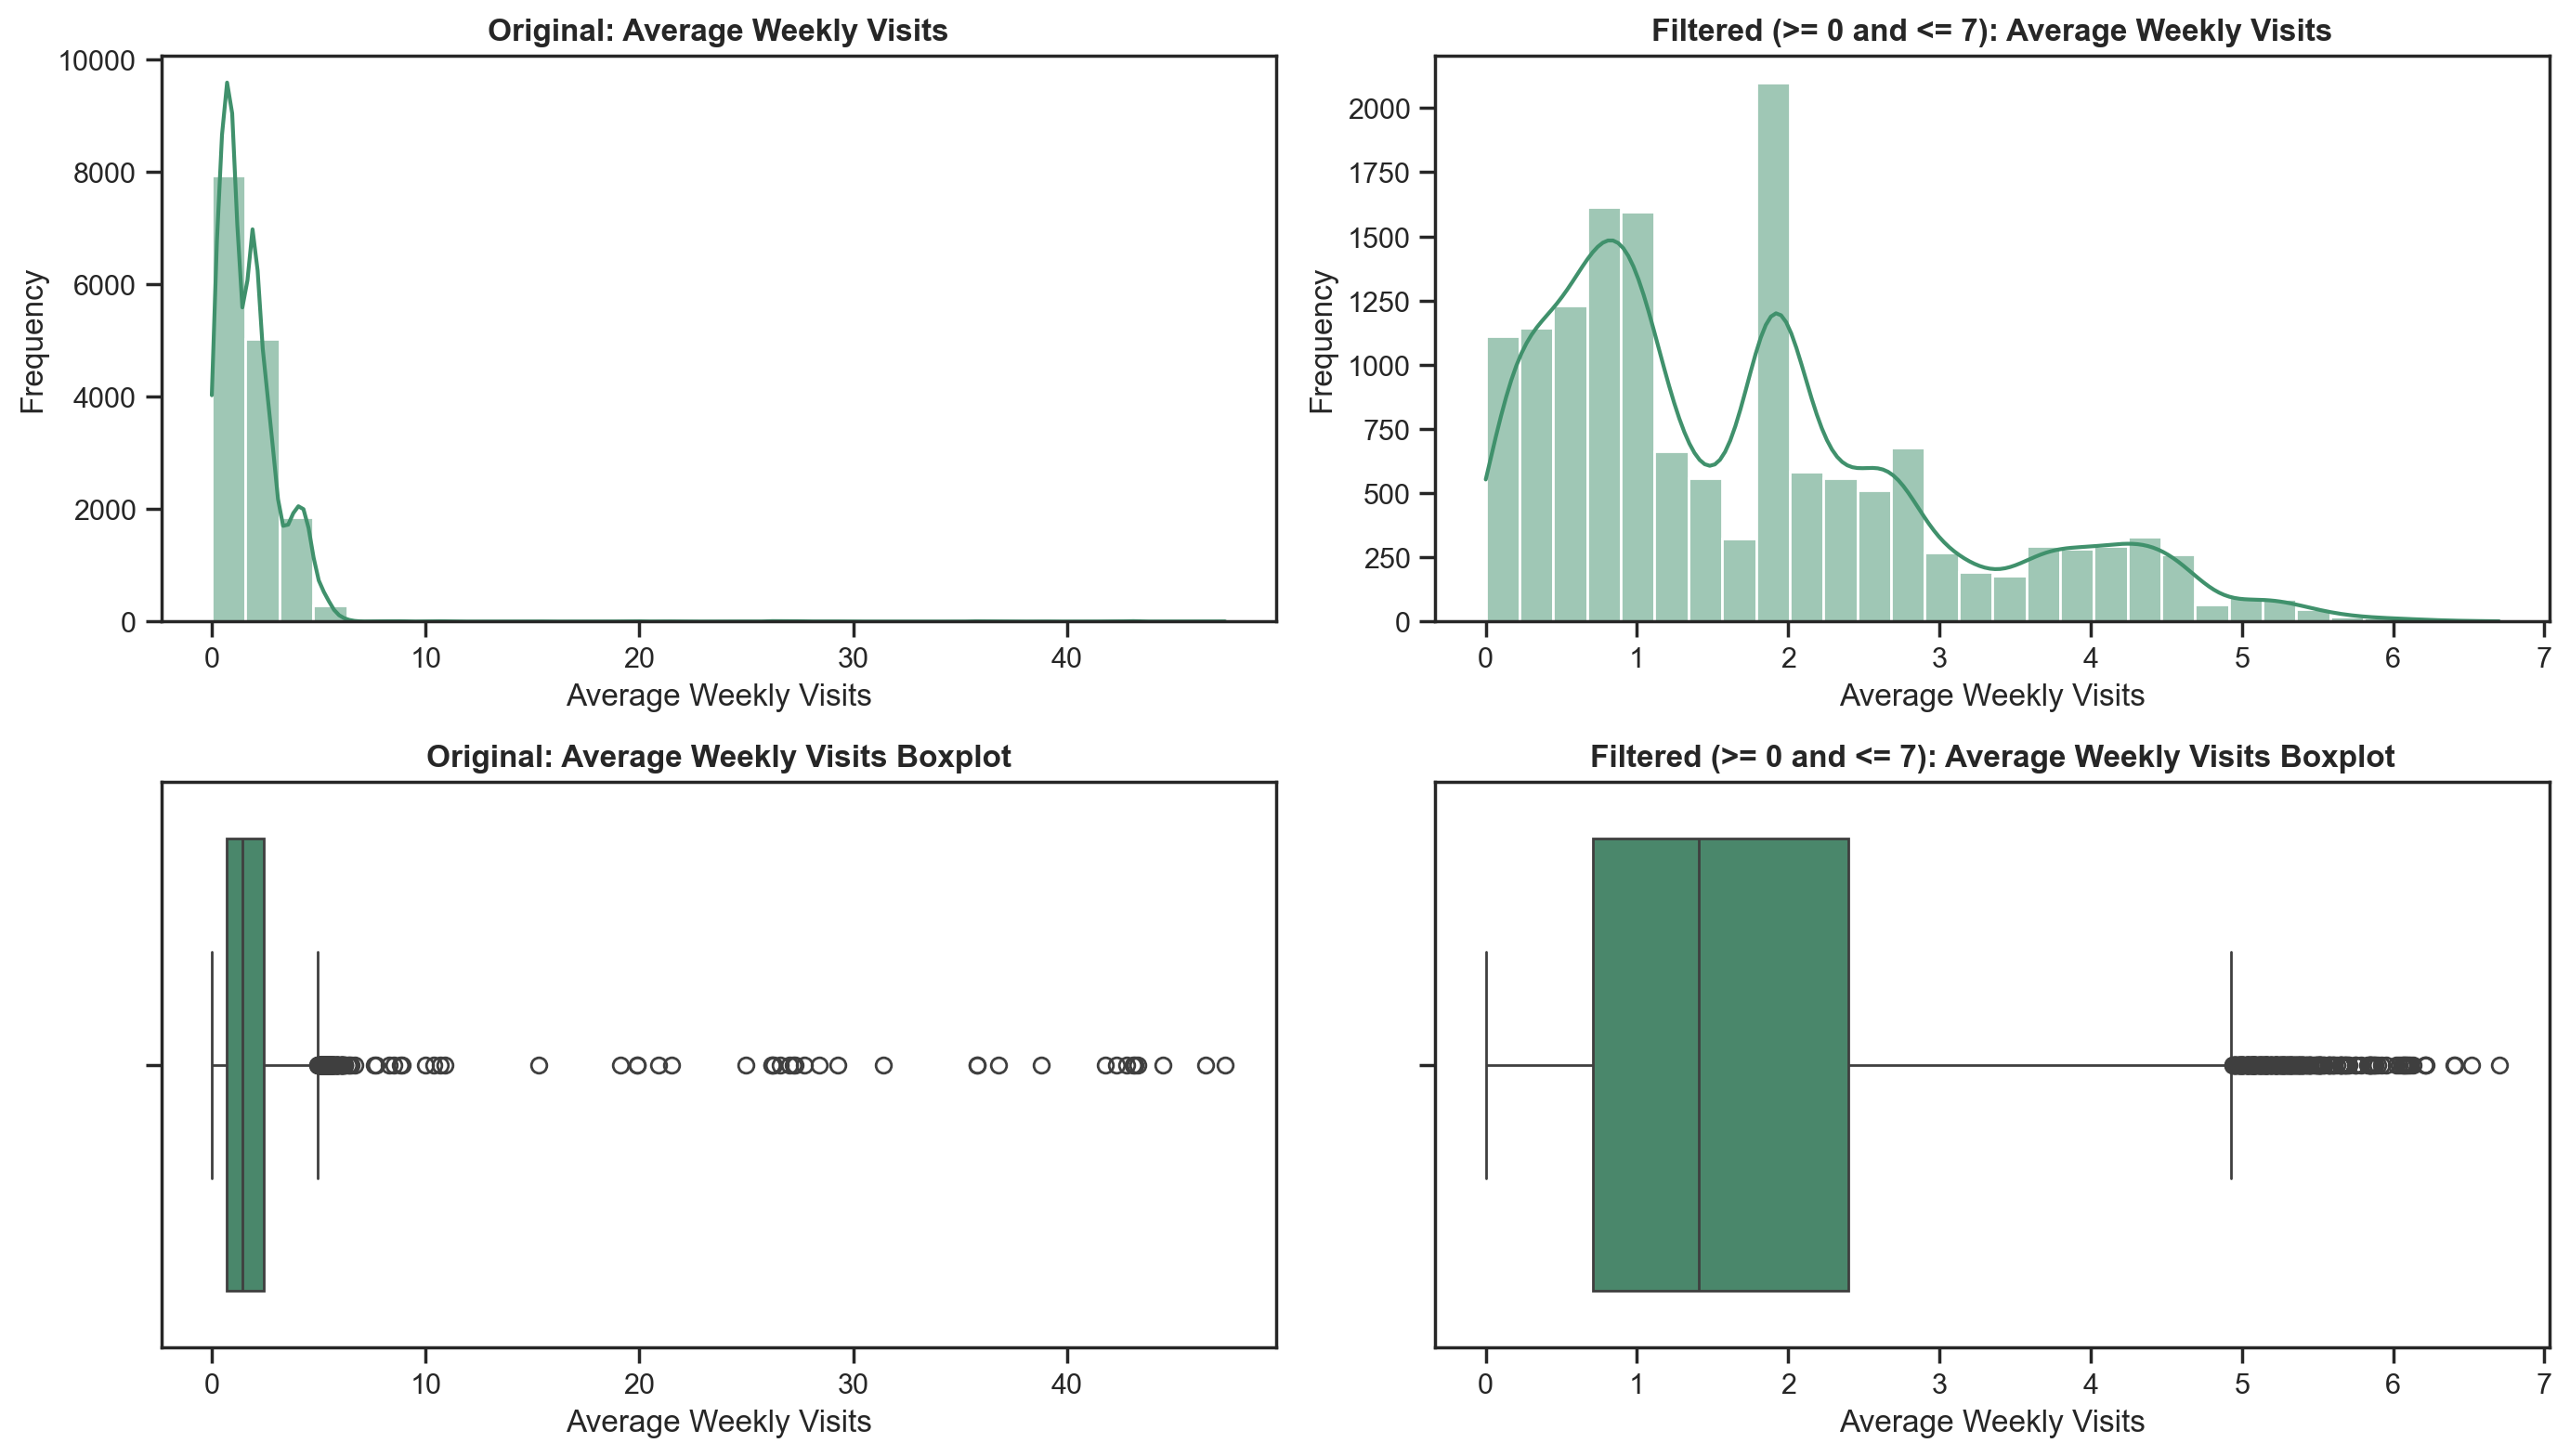

In [37]:
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

df_average_clean = df_nodups[(df_nodups["avg_weekly_visits"] >= 0) & (df_nodups["avg_weekly_visits"] <= 7)]

sns.histplot(df_nodups["avg_weekly_visits"].dropna(), bins=30, color=main_color, kde=True, ax=axes[0, 0])
sns.histplot(df_average_clean["avg_weekly_visits"].dropna(), bins=30, color=main_color, kde=True, ax=axes[0, 1])

sns.boxplot(x=df_nodups["avg_weekly_visits"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_average_clean["avg_weekly_visits"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Average Weekly Visits', fontweight="bold")
axes[0, 0].set_xlabel('Average Weekly Visits')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Filtered (>= 0 and <= 7): Average Weekly Visits', fontweight="bold")
axes[0, 1].set_xlabel('Average Weekly Visits')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Average Weekly Visits Boxplot', fontweight="bold")
axes[1, 0].set_xlabel('Average Weekly Visits')

axes[1, 1].set_title('Filtered (>= 0 and <= 7): Average Weekly Visits Boxplot', fontweight="bold")
axes[1, 1].set_xlabel('Average Weekly Visits')

plt.tight_layout()
plt.show()

After filtering properly, the distribution of `avg_weekly_visits` is no longer a single peak: there are several peaks, around 1, 2 and 4 visits per week, with a very sharp one at 2. Most customers are between 0.7 and 2.4 visits per week (the box of the boxplot), and only a few go more than 5 times per week. 

The values above 5 appear as outliers in the boxplot, but they are possible (up to 7), so we keep them. These peaks may be related to the different plans (2, 3, 5 and 7 days per week), which we explore in the bivariate analysis.

<b><font size="4" color="#FAA85E">6.1.7. `entitled_visits_last_period` and `actual_visits_last_period`</font></b><br> 

These two variables describe the same period: `entitled_visits_last_period` is how many visits the plan allows (theoretically, probably) and `actual_visits_last_period` is how many visits the customer really made. We analyse them together because comparing the two shows how much of the plan each customer uses. They are among the most important variables to understand customer activity, so they may finally answer our initial doubt about whether customers use less than their plan allows.

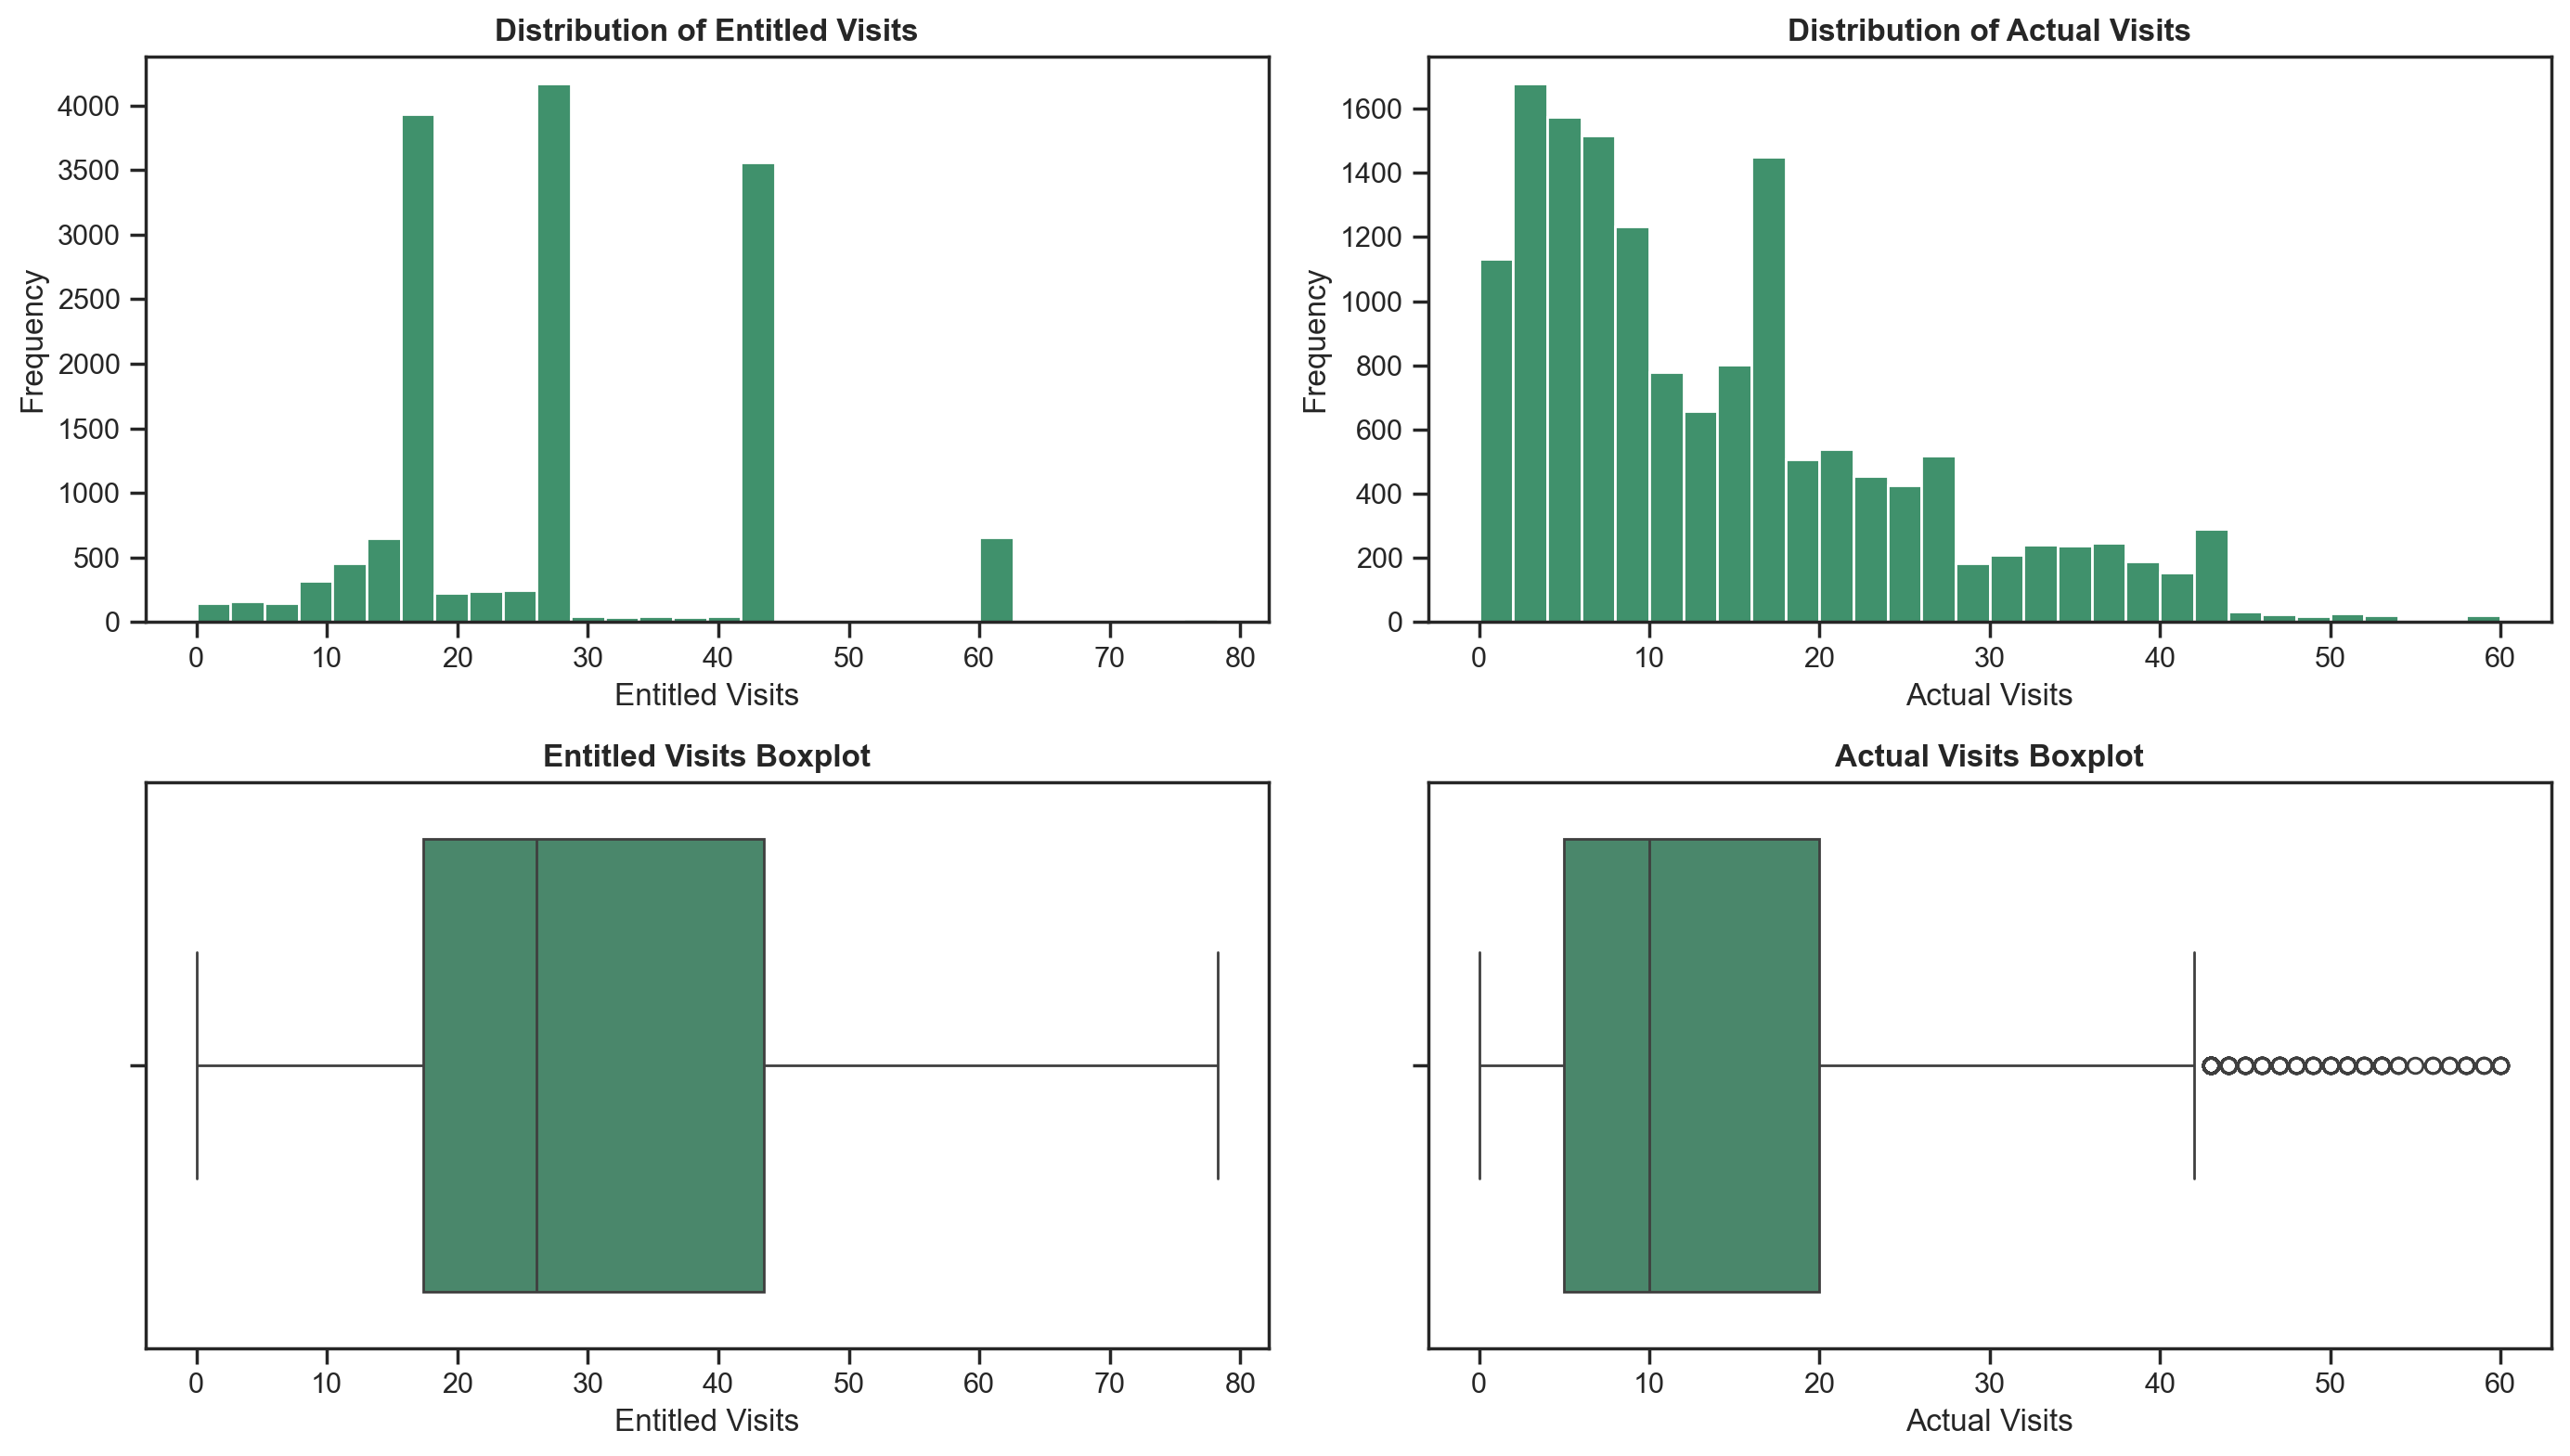

In [38]:
subplot_figsize = (14, 8) 

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

axes[0, 0].hist(df_nodups["entitled_visits_last_period"].dropna(), bins=30, color=main_color)
axes[0, 1].hist(df_nodups["actual_visits_last_period"].dropna(), bins=30, color=main_color)

sns.boxplot(x=df_nodups["entitled_visits_last_period"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_nodups["actual_visits_last_period"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Distribution of Entitled Visits', fontweight="bold") 
axes[0, 0].set_xlabel('Entitled Visits')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Distribution of Actual Visits', fontweight="bold") 
axes[0, 1].set_xlabel('Actual Visits')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Entitled Visits Boxplot', fontweight="bold") 
axes[1, 0].set_xlabel('Entitled Visits')

axes[1, 1].set_title('Actual Visits Boxplot', fontweight="bold") 
axes[1, 1].set_xlabel('Actual Visits')

plt.tight_layout()
plt.show()

The distribution of **entitled visits** is concentrated around a few specific values (about 17, 26, 43 and 60), which is expected if it is a theoretical value defined by the company according to the plan. In contrast, **actual visits** are right-skewed: most customers have few visits, and the boxplot shows outliers above about 42 visits.

The median of actual visits (about 10) is well below the median of entitled visits (about 26), which *suggests* that customers effectively use only part of their entitlement. This is analysed in more detail later, probably through a usage rate variable.

<b><font size="4" color="#FAA85E">6.1.8. `meeting_room_hours` and `event_space_hours`</font></b><br>  

Besides the plan itself, customers can also use extra services of the space. It is important to understand whether these services (`meeting_room_hours` and `event_space_hours`) are used or not, and how often, since they may show a different type of customer activity.

In [39]:
cols = ["meeting_room_hours", "event_space_hours"]

rows = {}
for c in cols:
    s = df_nodups[c].dropna()
    pos = s[s > 0]
    rows[c] = {"% zeros": (s == 0).mean() * 100, "n negative": (s < 0).sum(), "n positive": len(pos),
               "median (positive)": pos.median(), "p90": pos.quantile(0.90),
               "p99": pos.quantile(0.99), "max": pos.max()}

pd.DataFrame(rows).T.round(1)

,% zeros,n negative,n positive,median (positive),p90,p99,max
meeting_room_hours,65.2,16.0,4822.0,32.7,182.6,508.2,41220.0
event_space_hours,88.5,8.0,1741.0,23.3,115.4,318.9,602.8


For both variables, we filtered out the few negative values (16 and 8, respectively), since they are impossible.

Most customers do not use these services: 65.2% of the records have zero `meeting_room_hours` and 88.5% have zero `event_space_hours`. Because of this, the plots below show only the positive values, and all the statistics refer to customers who actually use the service. We also use a logarithmic scale, since a few extreme values stretch the axis and hide the rest of the data.

The maximum of `meeting_room_hours` (41220) is also impossible: it would be almost 5 years of continuous use, and it is far above the 99th percentile (508.2). It is probably a data entry error, so we treat it as an invalid value.

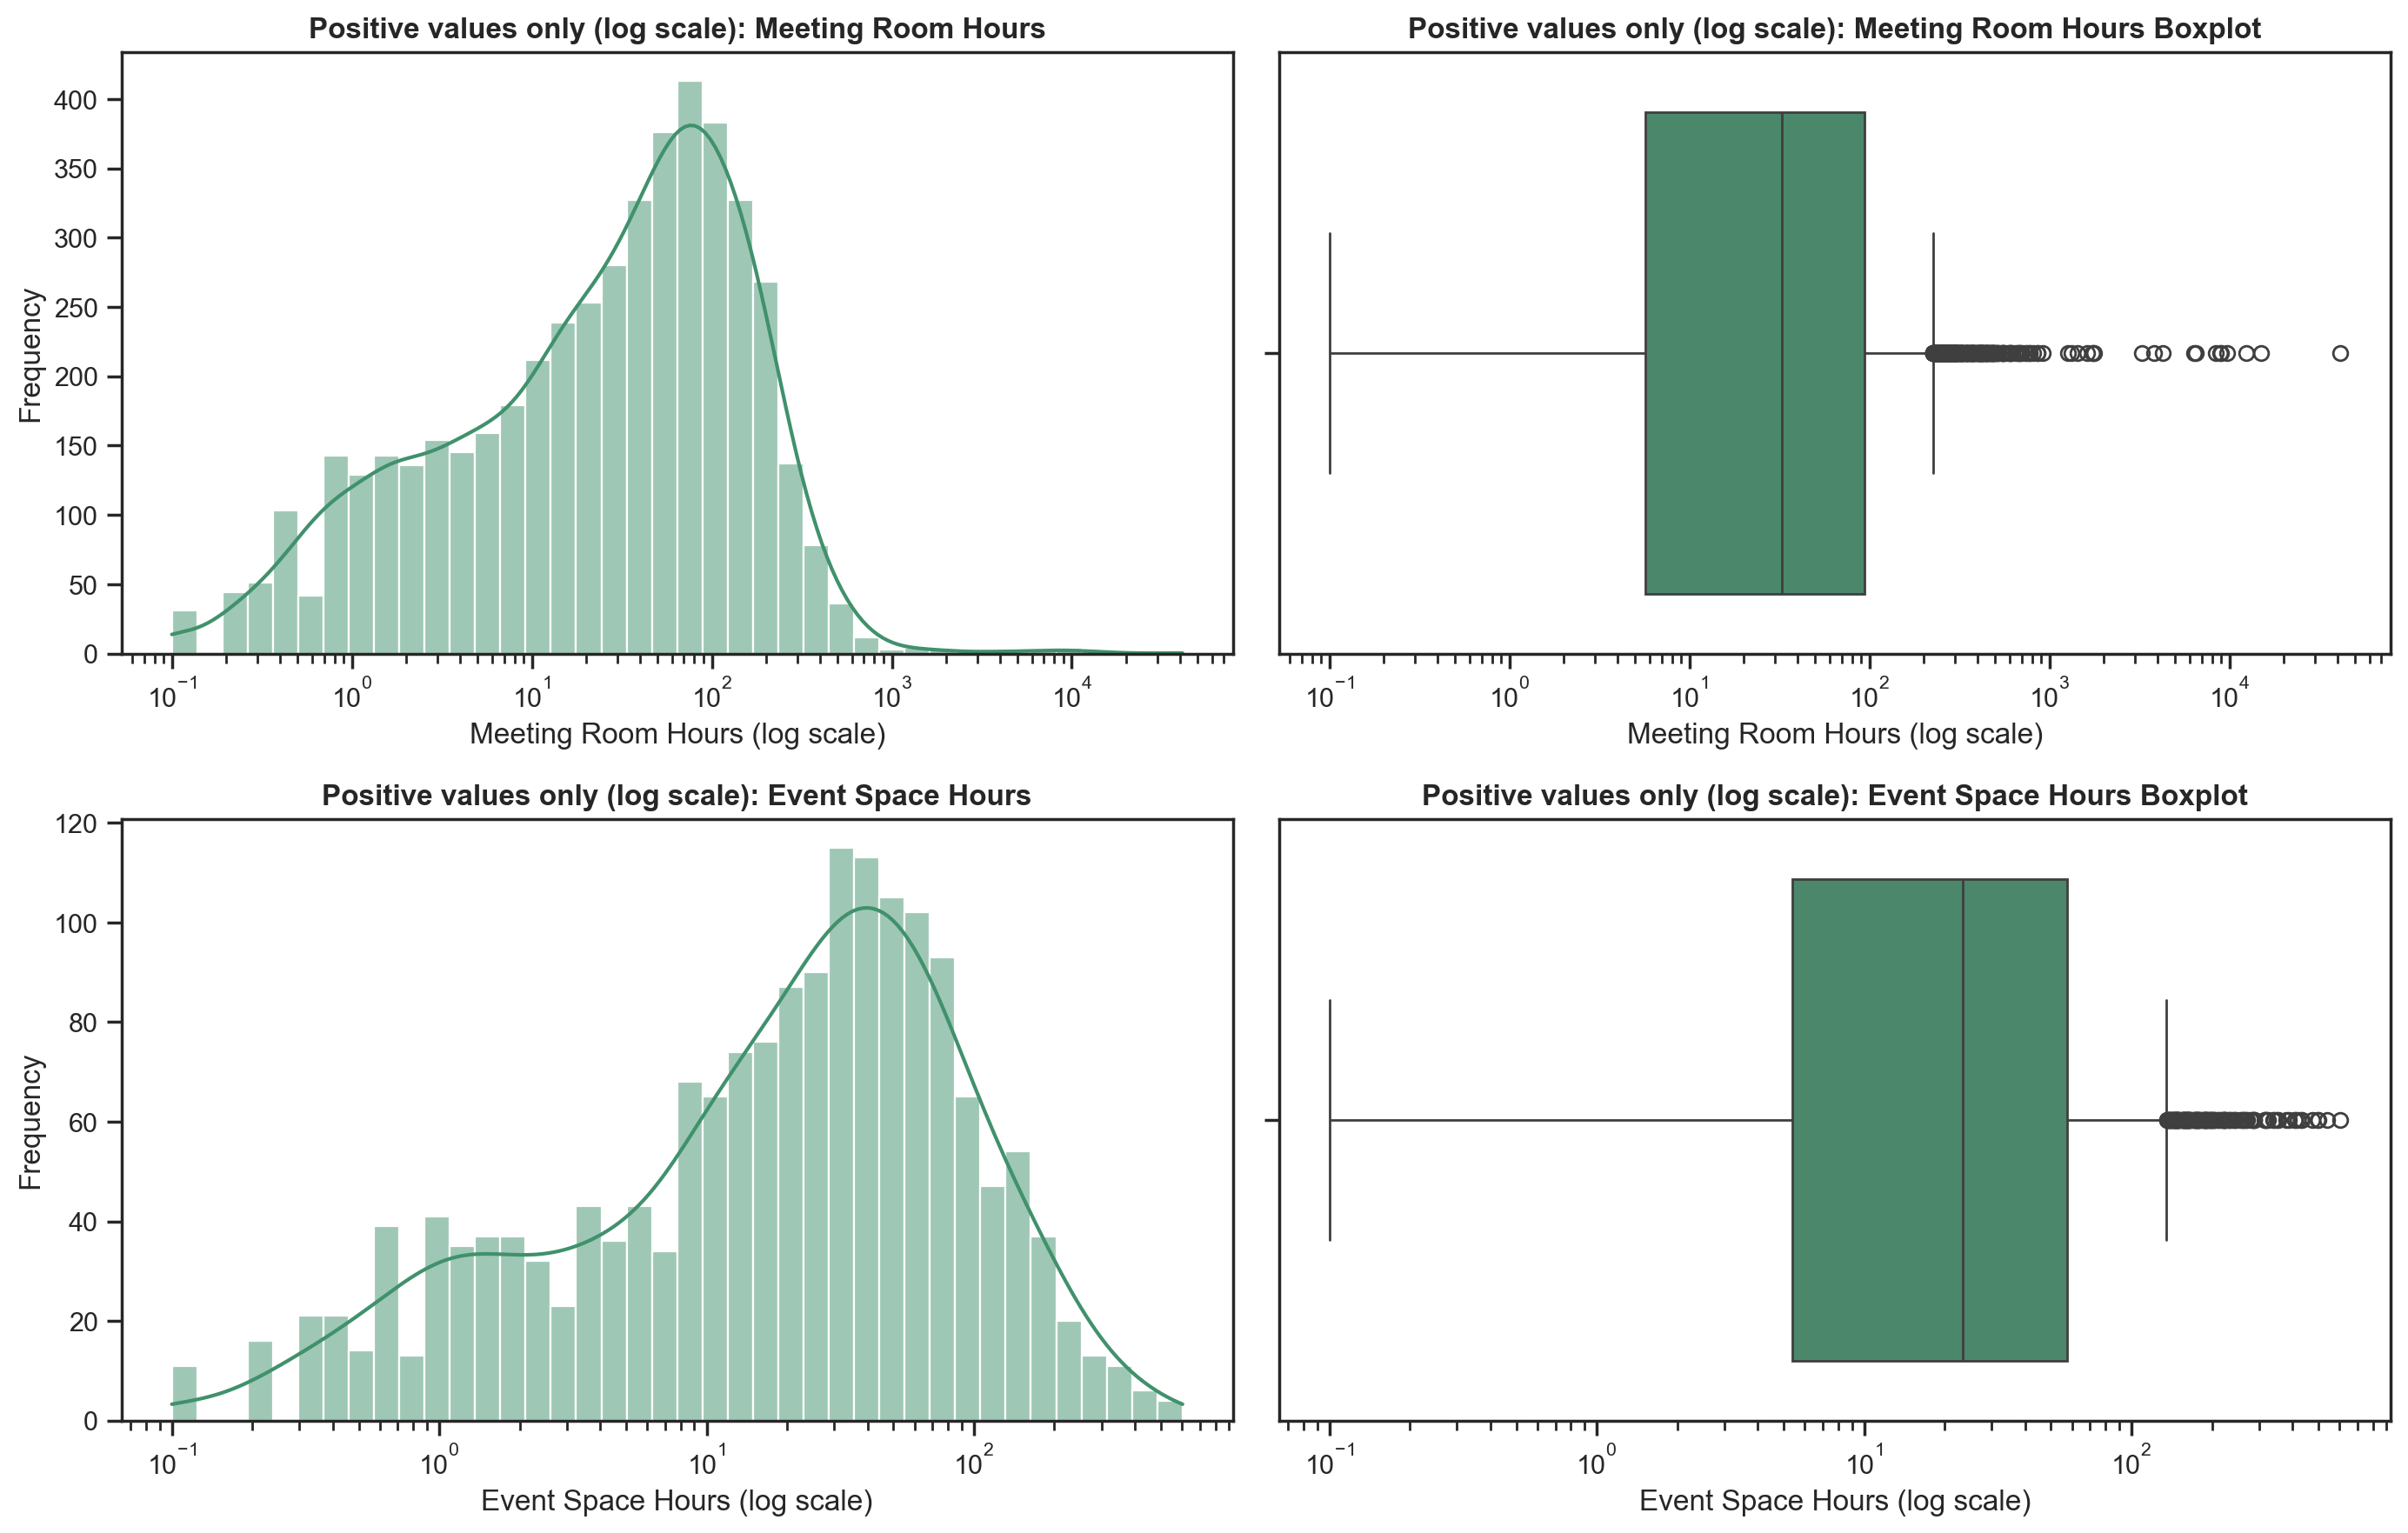

In [40]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))

for i, (c, name) in enumerate([("meeting_room_hours", "Meeting Room Hours"),
                               ("event_space_hours", "Event Space Hours")]):
    pos = df_nodups.loc[df_nodups[c] > 0, c]

    sns.histplot(pos, bins=40, log_scale=True, color=main_color, kde=True, ax=axes[i, 0])
    axes[i, 0].set_title(f'Positive values only (log scale): {name}', fontweight="bold")
    axes[i, 0].set_xlabel(name + ' (log scale)')
    axes[i, 0].set_ylabel('Frequency')

    sns.boxplot(x=pos, color=main_color, ax=axes[i, 1])
    axes[i, 1].set_xscale("log")
    axes[i, 1].set_title(f'Positive values only (log scale): {name} Boxplot', fontweight="bold")
    axes[i, 1].set_xlabel(name + ' (log scale)')

plt.tight_layout()
plt.show()

For `meeting_room_hours`, the positive values are concentrated, on the log scale, between about 10⁰ and 10³ hours, with a peak at around 80 hours and a median of about 33 hours. For `event_space_hours`, the pattern is similar but shifted to lower values, with a peak at around 40 hours and a median of about 23 hours. The frequencies are lower because far fewer customers use the event space (about 1700, against about 4800 for meeting rooms).

Both variables have many points flagged as outliers by the boxplot rule. The whiskers are computed on the original values (the log scale is only used to display them), so these points should be read as customers with very intensive use, for example members who rely on the space mainly for meetings or events, and not necessarily as errors.

In [41]:
meeting = df_nodups["meeting_room_hours"]
event = df_nodups["event_space_hours"]

unknown = meeting.isna() | event.isna() | (meeting < 0) | (event < 0)
m = meeting > 0
e = event > 0

service_use = np.select(
    [unknown, ~m & ~e, m & ~e, ~m & e, m & e], 
    ["Unknown", "None", "Meeting rooms only", "Event space only", "Both"],
    default="Unknown"
)

series = pd.Series(service_use)
print("All customers:")
print((series.value_counts(normalize=True) * 100).round(1))

print("\nOnly customers with valid data:")
print((series[series != "Unknown"].value_counts(normalize=True) * 100).round(1))

All customers:
None                  56.4
Meeting rooms only    24.5
Unknown                8.5
Both                   7.3
Event space only       3.3
Name: proportion, dtype: float64

Only customers with valid data:
None                  61.6
Meeting rooms only    26.8
Both                   7.9
Event space only       3.7
Name: proportion, dtype: float64


Considering only the customers with valid data, most have no recorded use of these services (61.6%). About 35% use meeting rooms (26.8% only meeting rooms), about 12% use the event space (3.7% only event space), and 7.9% use both. Customers who use many meeting room hours do not seem to be the same ones who use many event space hours, so the two services look like different types of use. Those who use these services seem to use them intensively (medians of about 33 and 23 hours), which we explore in the bivariate analysis.

<b><font size="4" color="#FAA85E">6.1.9. `guest_passes_issued`</font></b><br>  

`guest_passes_issued` is the number of guest passes issued by each member. It could be related to the use of services such as meeting rooms or event space, but we do not assume any link for now: the goal here is to understand the distribution of this variable.

In [42]:
raw = df_nodups["guest_passes_issued"]
s = raw.dropna()
pos = s[s > 0]

pd.DataFrame({"n missing": [raw.isna().sum()],
              "% missing": [raw.isna().mean() * 100],
              "% zeros": [(s == 0).mean() * 100],
              "n negative": [(s < 0).sum()],
              "n positive": [len(pos)],
              "median (positive)": [pos.median()],
              "p90": [pos.quantile(0.90)],
              "p99": [pos.quantile(0.99)],
              "max": [pos.max()]},
             index=["guest_passes_issued"]).round(1)

,n missing,% missing,% zeros,n negative,n positive,median (positive),p90,p99,max
guest_passes_issued,1248,8.2,82.4,7,2438,20.0,89.3,219.0,589.0


So, `guest_passes_issued` has the same structure as the previous service variables: it is zero-inflated, with 82.4% of the non-missing records equal to zero, which means that most customers do not issue guest passes. This variable has 1248 missing values (8.2%) and 7 negative values, which are invalid and therefore were excluded from the plot. Only 2438 customers have a positive value, so the plot below shows only these customers, again on a logarithmic scale.

Among them, the distribution is strongly right-skewed: the median is 20 passes, 90% of the customers issued fewer than about 89 and only 1% more than about 219. The maximum (589) is only about 2.7 times the 99th percentile, in contrast with `meeting_room_hours`, so the extreme values here do not look implausible and may correspond to customers who regularly host guests. As the variable is a count, the histogram may show gaps at low values, which is expected.

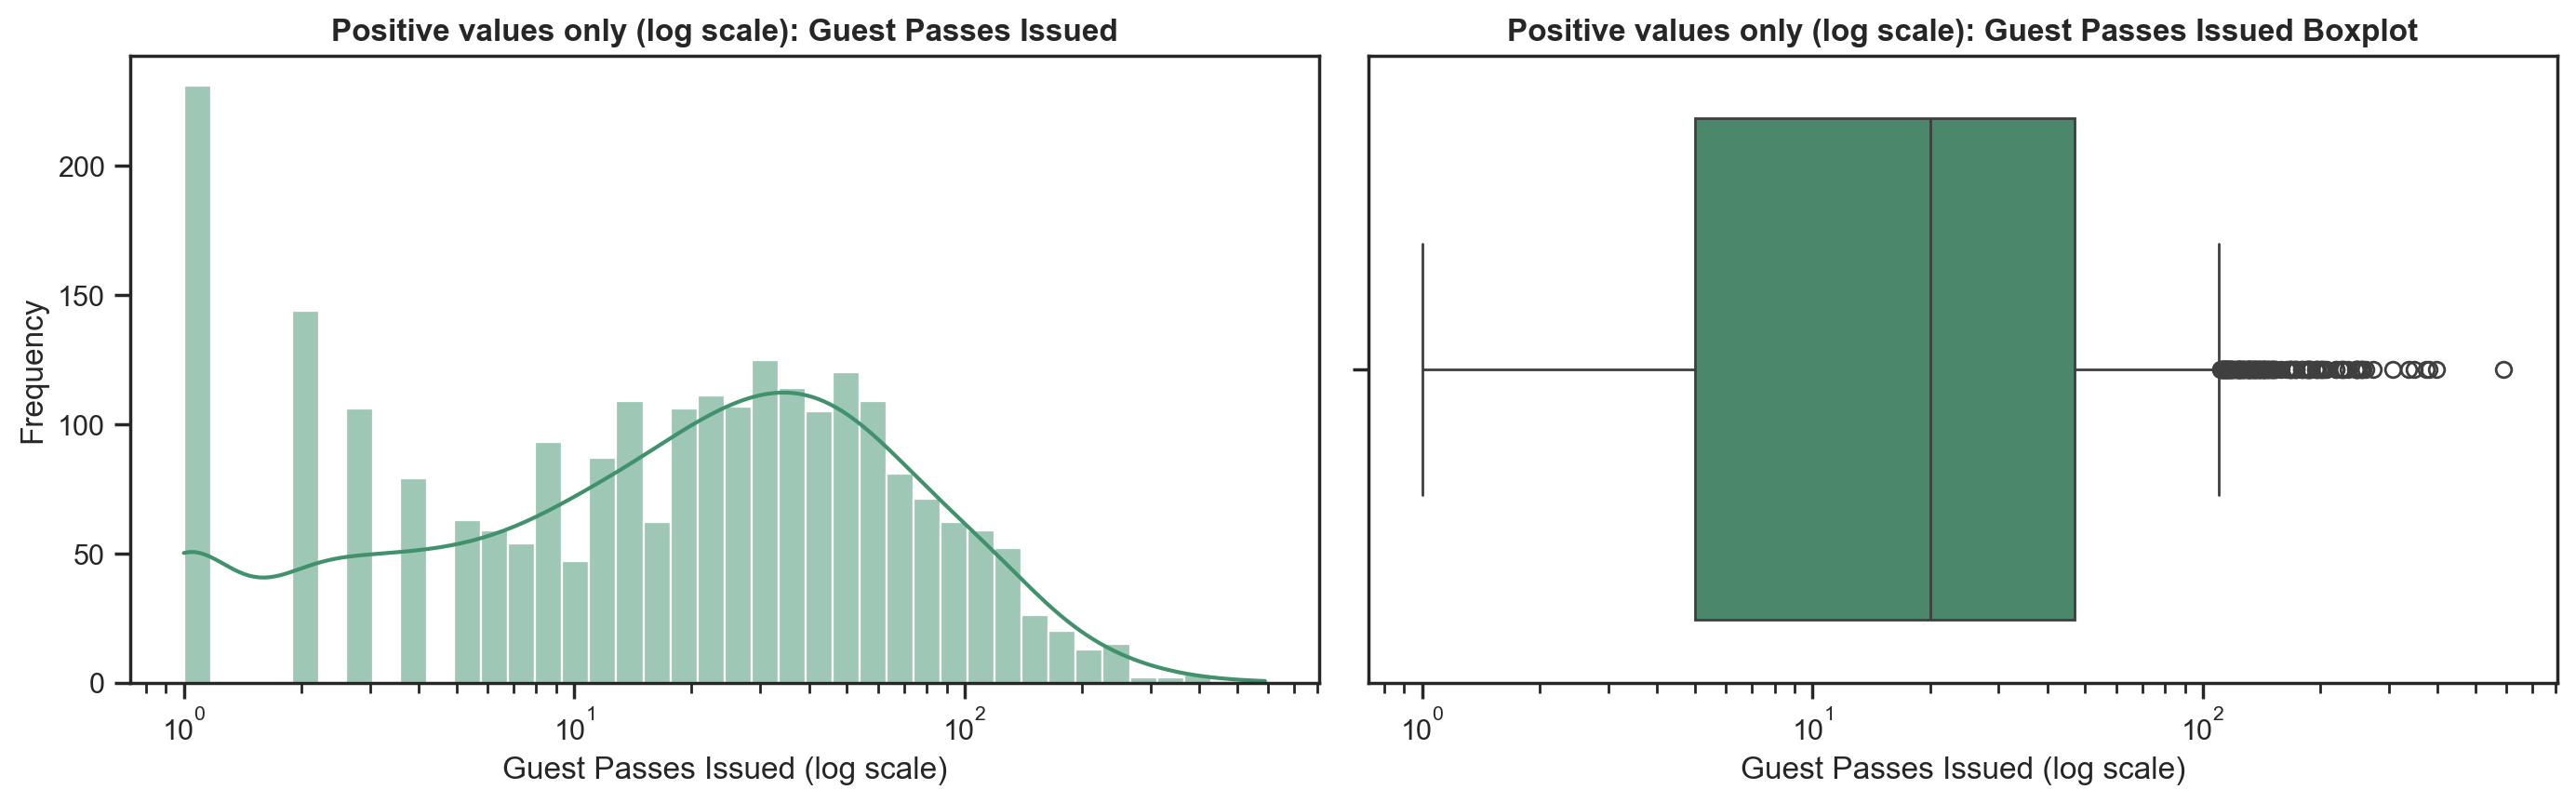

In [43]:
pos = df_nodups.loc[df_nodups["guest_passes_issued"] > 0, "guest_passes_issued"]

fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))

sns.histplot(pos, bins=40, log_scale=True, color=main_color, kde=True, ax=axes[0])
axes[0].set_title('Positive values only (log scale): Guest Passes Issued', fontweight="bold")
axes[0].set_xlabel('Guest Passes Issued (log scale)')
axes[0].set_ylabel('Frequency')

sns.boxplot(x=pos, color=main_color, ax=axes[1])
axes[1].set_xscale("log")
axes[1].set_title('Positive values only (log scale): Guest Passes Issued Boxplot', fontweight="bold")
axes[1].set_xlabel('Guest Passes Issued (log scale)')

plt.tight_layout()
plt.show()

Among customers who issue guest passes, the most common numbers are 1, followed by 2, 3 and 4, but many customers issue more: the median is 20 passes, and half of them issue between about 5 and 48. The separate bars at low values appear because passes are counted in whole numbers (on a log scale, the integers 1, 2, 3 and 4 are far apart).

Overall, the number of passes varies a lot from customer to customer, and the histogram peaks at around 35 passes. The boxplot also shows some customers who issue far more than the rest (above about 110 passes, up to 589). These may be customers who regularly host guests, and not necessarily errors.

Note: we have no information on whether guest passes are paid (for example, a payment per guest or packs of passes). This could be explored with the company, or suggested to it, if it turns out to be relevant later in the analysis.

<b><font size="4" color="#FAA85E">6.1.10. `n_renewals`</font></b><br>  

`n_renewals` is probably the clearest signal of how useful and relevant the plan is for customers: someone who renews is choosing to stay. For this reason, it is the variable that should guide us the most when we start to outline options for the company, and we will keep coming back to it in the rest of the analysis. One thing to keep in mind is that the number of renewals also depends on how long each customer has been a member.

In [44]:
raw = df_nodups["n_renewals"]
s = raw.dropna()
pos = s[s > 0]

pd.DataFrame({"n missing": [raw.isna().sum()],
              "% missing": [raw.isna().mean() * 100],
              "% zeros": [(s == 0).mean() * 100],
              "n negative": [(s < 0).sum()],
              "n positive": [len(pos)],
              "median (positive)": [pos.median()],
              "p90": [pos.quantile(0.90)],
              "p99": [pos.quantile(0.99)],
              "max": [pos.max()]},
             index=["n_renewals"]).round(1)

,n missing,% missing,% zeros,n negative,n positive,median (positive),p90,p99,max
n_renewals,0,0.0,50.1,65,7500,2.0,4.0,6.0,6


In [45]:
d = df_nodups[df_nodups["n_renewals"] >= 0].copy()
d["still_active"] = d["membership_end"] == pd.Timestamp("1970-01-01")
d["zero_renewals"] = d["n_renewals"] == 0

(pd.crosstab(d["still_active"], d["zero_renewals"], normalize="index") * 100).round(1)

zero_renewals,False,True
still_active,,
False,42.8,57.2
True,69.5,30.5


Zero renewals are more frequent among customers who already left (57.2%) than among active customers (30.5%), so the large share of zeros is not explained only by recent customers. In other words, more than half of the customers who left did so without ever renewing. Among active customers, zero renewals may correspond to customers who are still in their first period, but we have not checked this. This supports the idea that retention is one of the main topics to explore for the company.

*Note: we assumed that the date 1970-01-01 in `membership_end` is a code for members whose subscription is still active.*

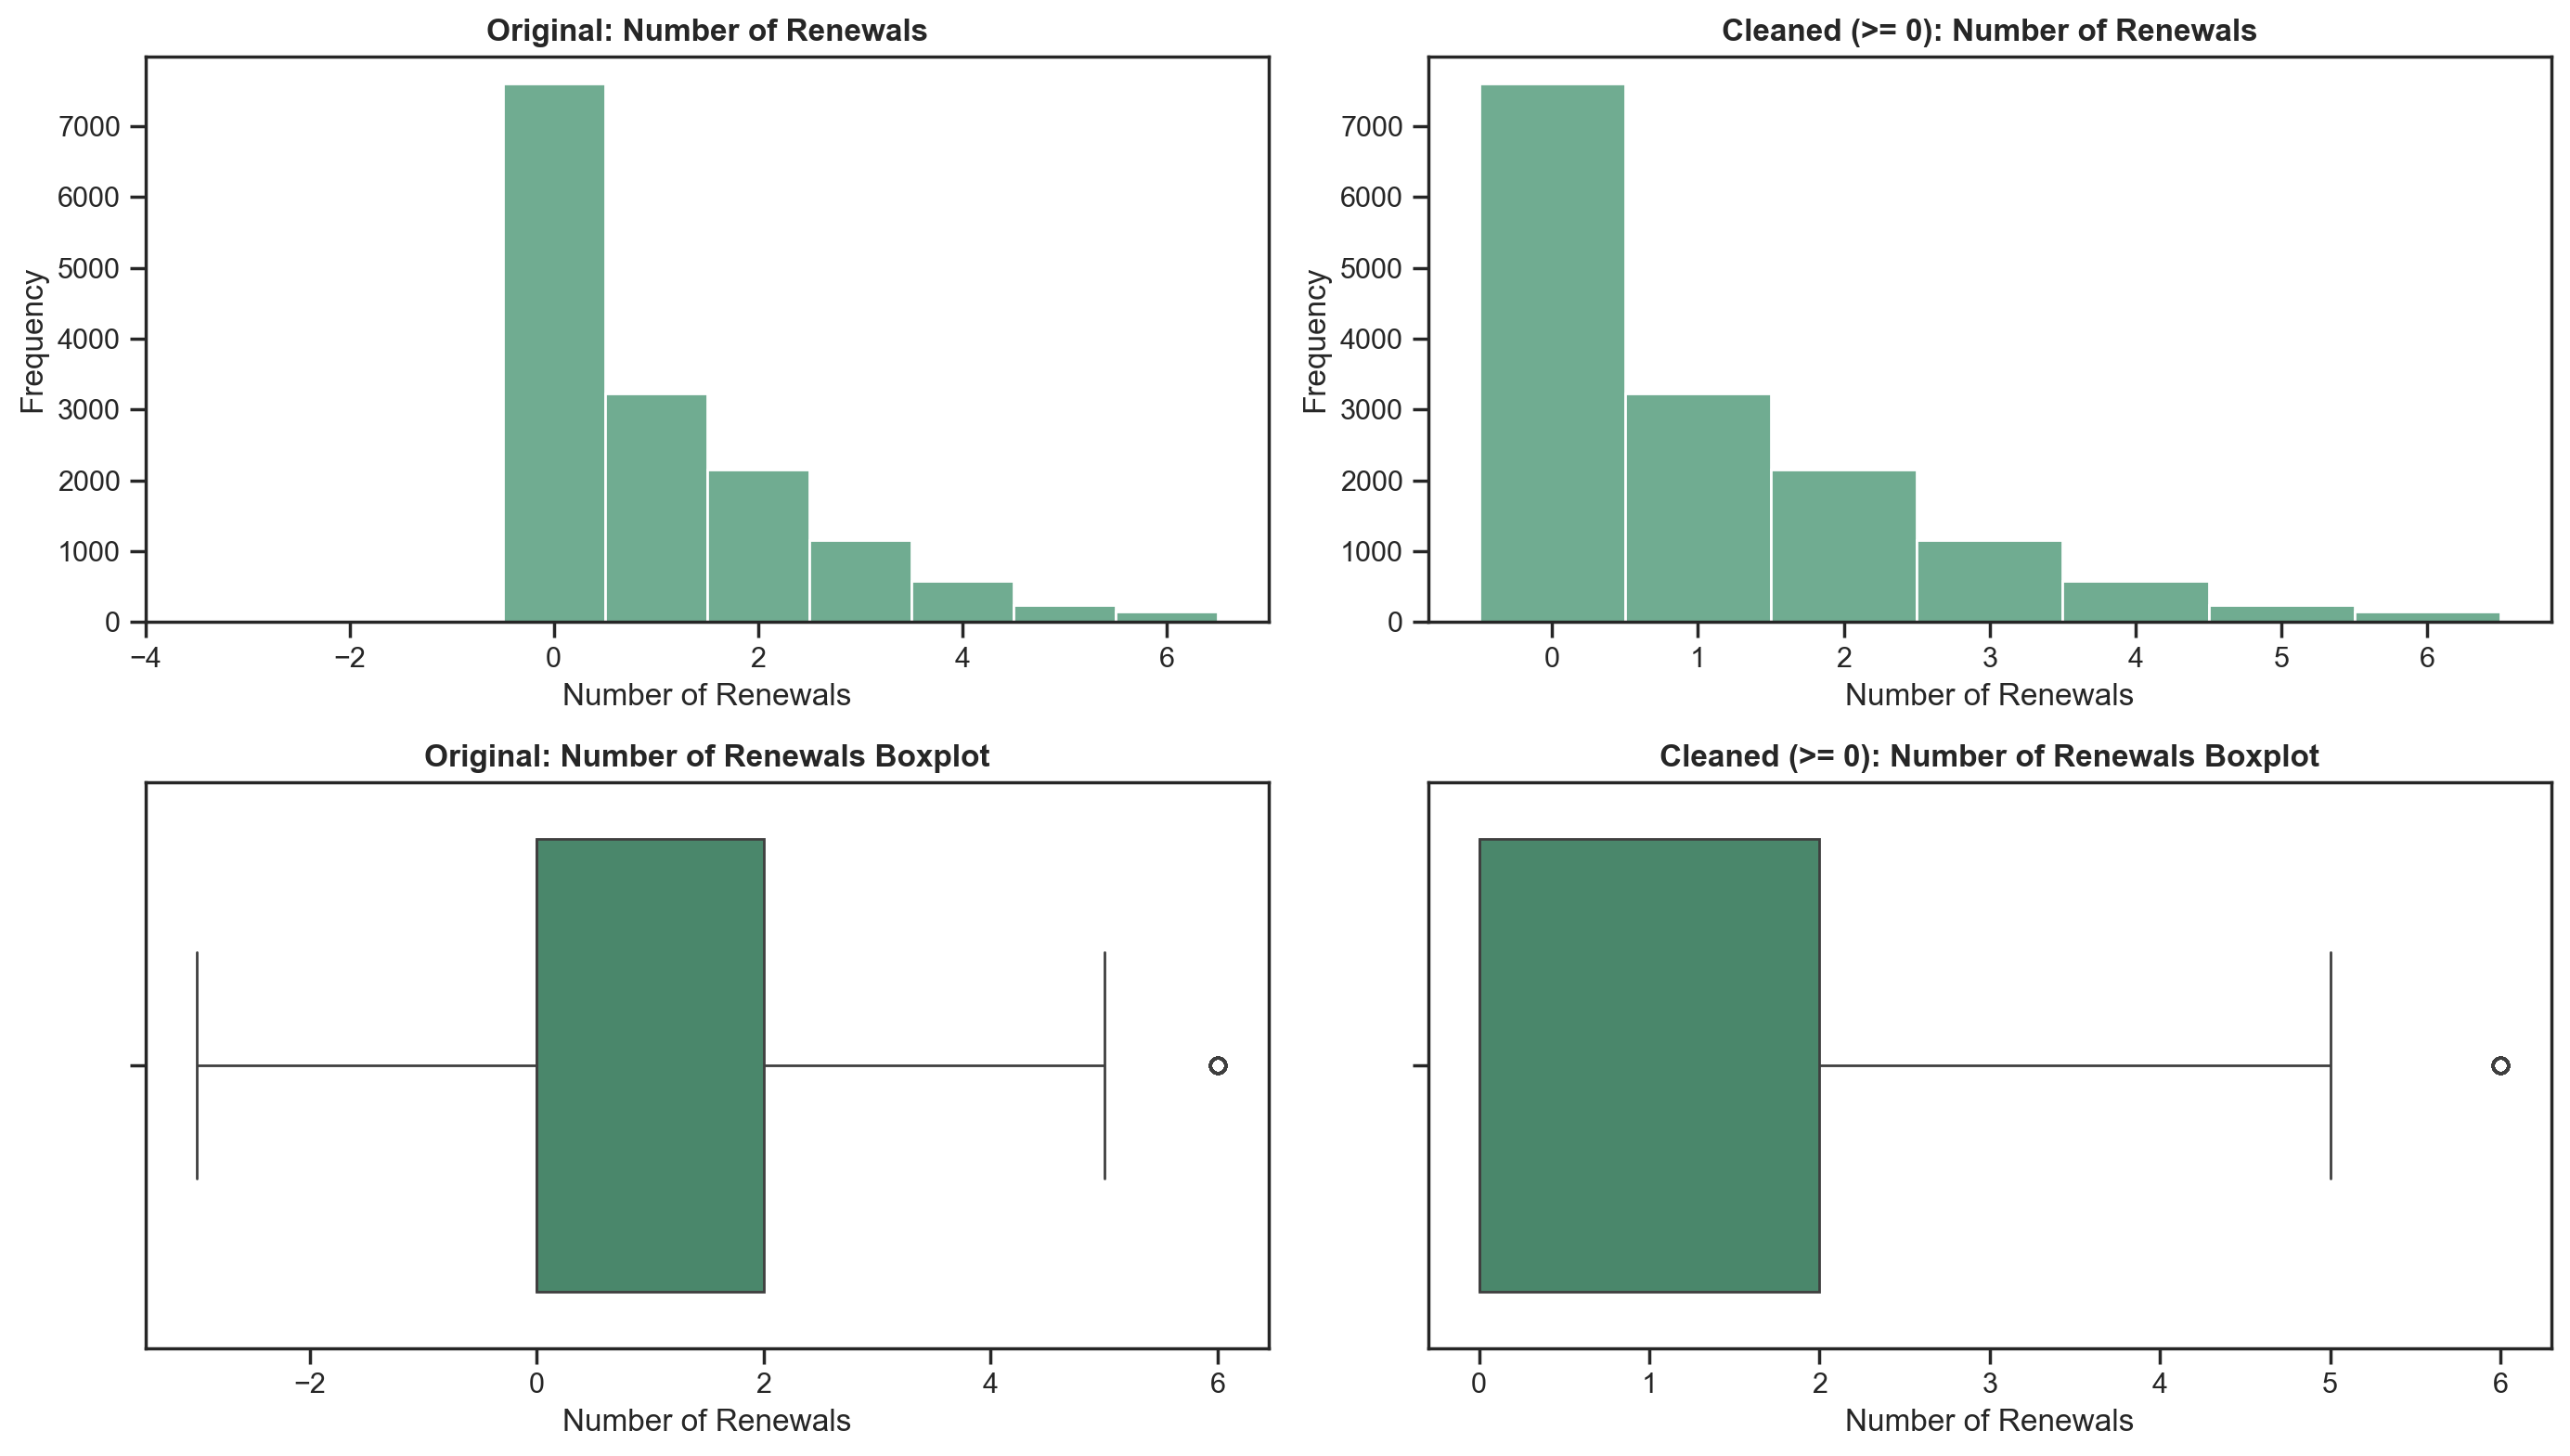

In [46]:
df_renewals_clean = df_nodups[df_nodups["n_renewals"] >= 0]

subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

sns.histplot(df_nodups["n_renewals"].dropna(), discrete=True, color=main_color, ax=axes[0, 0])
sns.histplot(df_renewals_clean["n_renewals"].dropna(), discrete=True, color=main_color, ax=axes[0, 1])

sns.boxplot(x=df_nodups["n_renewals"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_renewals_clean["n_renewals"], color=main_color, ax=axes[1, 1])

axes[0, 0].set_title('Original: Number of Renewals', fontweight="bold")
axes[0, 0].set_xlabel('Number of Renewals')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Cleaned (>= 0): Number of Renewals', fontweight="bold")
axes[0, 1].set_xlabel('Number of Renewals')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: Number of Renewals Boxplot', fontweight="bold")
axes[1, 0].set_xlabel('Number of Renewals')

axes[1, 1].set_title('Cleaned (>= 0): Number of Renewals Boxplot', fontweight="bold")
axes[1, 1].set_xlabel('Number of Renewals')

plt.tight_layout()
plt.show()

Most customers renew only a few times: about half of them never renewed, as we concluded above, and the third quartile is 2 renewals. As the number of renewals increases, the frequency decreases, which is expected, since renewing many times requires staying as a member for a long time (and probably paying more). This also means that the number of renewals depends on how long each customer has been a member. Still, some customers renew more than four times, and the boxplot flags 6 renewals (the maximum) as an outlier, with only about a hundred customers reaching it. This does not look like an error, just a rare behaviour.

<b><font size="4" color="#FAA85E">6.1.11. `lifetime_value`</font></b><br>  

`lifetime_value` is the total revenue attributed to each member over the whole membership, so it is a direct measure of how valuable each customer is for the company. It should be related to `n_renewals` and to how long each customer stays, which we explore later. For now, we focus on understanding its distribution.

In [47]:
raw = df_nodups["lifetime_value"]
s = raw.dropna()
pos = s[s > 0]

pd.DataFrame({"n missing": [raw.isna().sum()],
              "% missing": [raw.isna().mean() * 100],
              "% zeros": [(s == 0).mean() * 100],
              "n negative": [(s < 0).sum()],
              "n positive": [len(pos)],
              "median (positive)": [pos.median()],
              "p90": [pos.quantile(0.90)],
              "p99": [pos.quantile(0.99)],
              "max": [pos.max()]},
             index=["lifetime_value"]).round(1)

,n missing,% missing,% zeros,n negative,n positive,median (positive),p90,p99,max
lifetime_value,1015,6.7,12.1,81,12364,1676.6,12030.7,26238.7,3371260.0


`lifetime_value` has 1015 missing values (6.7%), 81 negative values, which are invalid and will be excluded, and 12.1% of the customers have a value of zero. 

Among the positive values, the distribution is strongly right-skewed: the median is about 1677, but the 90th percentile is about 12031 and the 99th percentile is about 26239. The maximum (3371260) is more than 100 times the 99th percentile, so it is probably an invalid value. Because of this large gap, we use a logarithmic scale to be able to see the distribution of the data.

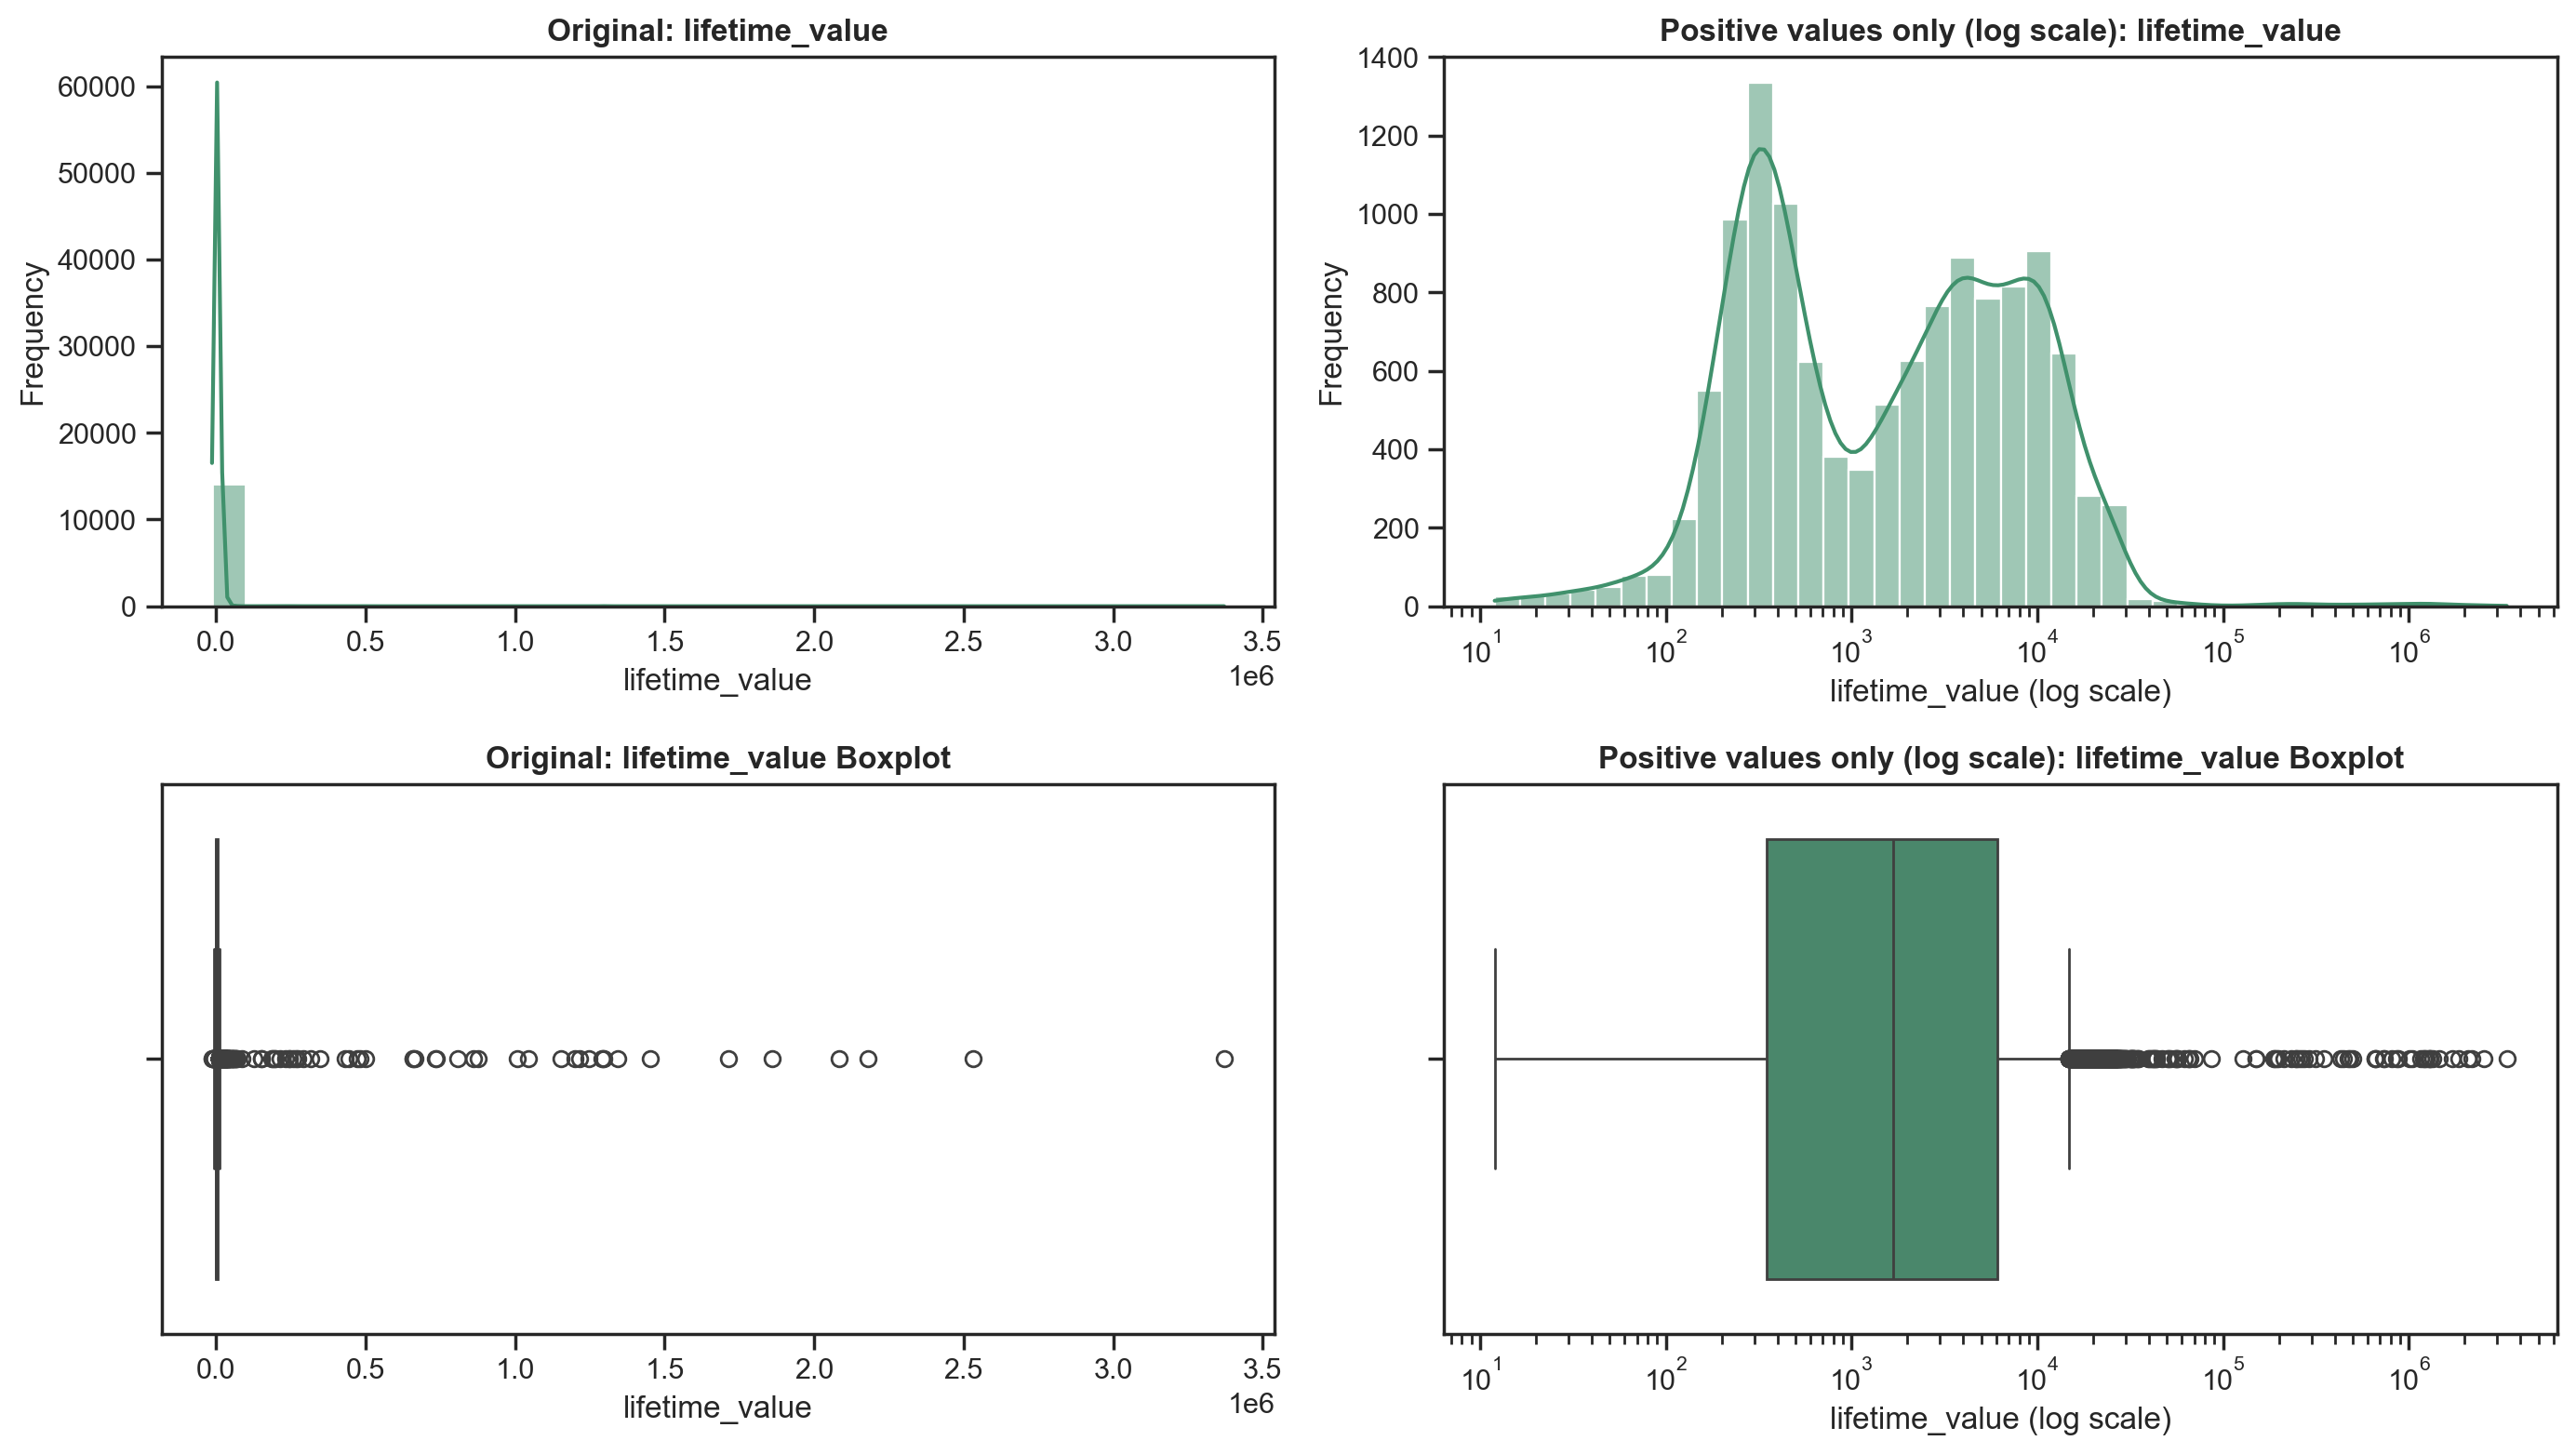

In [48]:
subplot_figsize = (14, 8)

with sns.axes_style("ticks"):
    fig, axes = plt.subplots(
        2, # nrows
        2, # ncols
        figsize=subplot_figsize)

df_ltv_pos = df_nodups[df_nodups["lifetime_value"] > 0]

sns.histplot(df_nodups["lifetime_value"].dropna(), bins=30, color=main_color, kde=True, ax=axes[0, 0])
sns.histplot(df_ltv_pos["lifetime_value"], bins=40, log_scale=True, color=main_color, kde=True, ax=axes[0, 1])

sns.boxplot(x=df_nodups["lifetime_value"], color=main_color, ax=axes[1, 0])
sns.boxplot(x=df_ltv_pos["lifetime_value"], color=main_color, ax=axes[1, 1])
axes[1, 1].set_xscale("log")

axes[0, 0].set_title('Original: lifetime_value', fontweight="bold")
axes[0, 0].set_xlabel('lifetime_value')
axes[0, 0].set_ylabel('Frequency')

axes[0, 1].set_title('Positive values only (log scale): lifetime_value', fontweight="bold")
axes[0, 1].set_xlabel('lifetime_value (log scale)')
axes[0, 1].set_ylabel('Frequency')

axes[1, 0].set_title('Original: lifetime_value Boxplot', fontweight="bold")
axes[1, 0].set_xlabel('lifetime_value')

axes[1, 1].set_title('Positive values only (log scale): lifetime_value Boxplot', fontweight="bold")
axes[1, 1].set_xlabel('lifetime_value (log scale)')

plt.tight_layout()
plt.show()

On a logarithmic scale, the positive values of `lifetime_value` show two distinct peaks, which may suggest that there are two main groups of customers for the company. 

The boxplot shows that half of the customers generate up to about 1677 and that the middle 50% of the customers are between about 350 and 6000, but there are many customers far above this range, up to millions. So there is a huge disparity in the value generated by each customer, which we explore in the following sections.

<b><font size="4" color="#FAA85E">6.1.12. Some conclusions</font></b><br>  

In [49]:
d = df_nodups
n = len(d)

neg_cols = ["days_since_last_visit", "total_visits", "meeting_room_hours", "event_space_hours",
            "guest_passes_issued", "n_renewals", "lifetime_value"]

rows = [
    ("Duplicated rows", "all columns", len(df) - len(d), len(df),
     "Removed",
     "Avoids counting the same customer twice"),
    ("Invalid age (< 18 or > 90)", "age", ((d["age"] < 18) | (d["age"] > 90)).sum(), n,
     "Set to missing",
     "Ages like 1 or 149 would stretch the scale and distort distances"),
    ("Invalid plan days (0 or 9)", "plan_days_per_week",
     (~d["plan_days_per_week"].isin([2, 3, 5, 7]) & d["plan_days_per_week"].notna()).sum(), n,
     "Recover from plan_tier (hot_desk=2, flex=3, dedicated_desk/full_time=5, private_office=7)",
     "Keeps these customers in the analysis"),
    ("Code -1 (probably NaN)", "n_colleagues_on_account", (d["n_colleagues_on_account"] < 0).sum(), n,
     "Treat as missing",
     "-1 would be read as 'fewer colleagues than none'"),
    ("Placeholder 999", "days_since_last_visit", (d["days_since_last_visit"] == 999).sum(), n,
     "Not used as a number (flag it, or recompute from last_badge_swipe)",
     "Would create a fake group of very inactive customers"),
    ("Impossible visit rate (> 7 per week)", "avg_weekly_visits", (d["avg_weekly_visits"] > 7).sum(), n,
     "Set to missing",
     "A few extreme values would dominate the distances"),
    ("Negative values (impossible)", "7 count/hours/value variables", (d[neg_cols] < 0).any(axis=1).sum(), n,
     "Set to missing (or check if it is a swapped sign)",
     "Same as missing values"),
    ("Missing values", "7 columns", d.isna().any(axis=1).sum(), n,
     "To be decided: impute or drop",
     "Most clustering methods need complete rows"),
]

quality = pd.DataFrame(rows, columns=["Problem", "Variable(s)", "n", "Base", "Decision", "Effect on clustering"])
quality["% of rows"] = (quality["n"] / quality["Base"] * 100).round(1)
quality = quality[["Problem", "Variable(s)", "n", "% of rows", "Decision", "Effect on clustering"]]

pd.set_option("display.max_colwidth", None)
quality

,Problem,Variable(s),n,% of rows,Decision,Effect on clustering
0,Duplicated rows,all columns,295,1.9,Removed,Avoids counting the same customer twice
1,Invalid age (< 18 or > 90),age,146,1.0,Set to missing,Ages like 1 or 149 would stretch the scale and distort distances
2,Invalid plan days (0 or 9),plan_days_per_week,96,0.6,"Recover from plan_tier (hot_desk=2, flex=3, dedicated_desk/full_time=5, private_office=7)",Keeps these customers in the analysis
3,Code -1 (probably NaN),n_colleagues_on_account,557,3.7,Treat as missing,-1 would be read as 'fewer colleagues than none'
4,Placeholder 999,days_since_last_visit,1272,8.4,"Not used as a number (flag it, or recompute from last_badge_swipe)",Would create a fake group of very inactive customers
5,Impossible visit rate (> 7 per week),avg_weekly_visits,41,0.3,Set to missing,A few extreme values would dominate the distances
6,Negative values (impossible),7 count/hours/value variables,211,1.4,Set to missing (or check if it is a swapped sign),Same as missing values
7,Missing values,7 columns,11790,77.7,To be decided: impute or drop,Most clustering methods need complete rows


<b><font size="4" color="#FAA85E">Summary of the univariate analysis</font></b><br>

**Data quality.** The table above summarises the main problems found, what we decided to do and why it matters for clustering. Besides these, we also fixed the data types (dates, `lifetime_value` and `uses_print`) and standardised the categories (for example, `gender` went from 12 to 3 values and `plan_tier` from 19 to 5). Some variables are also strongly right-skewed and zero-inflated (for example, `event_space_hours` has 88.5% of zeros), so they will probably need a log transformation and scaling before clustering.

**Who are our customers so far?**

- **Age:** half of the customers are between about 29 and 40 years old (median 34).
- **Account type:** most do not have colleagues on the account (about 69%), and about 28% are team accounts.
- **Plans:** most choose plans with few days per week (2 or 3 days, about two thirds of the customers). The 5-day group is also large because two plan types share it, and the 7-day plan is rare.
- **Use of the plan:** customers seem to use their plans only partly. The median is 1.42 visits per week, below the smallest plan (2 days), and the median of actual visits in the last period (about 10) is well below the entitled visits (about 26).
- **Extra services:** most do not use them. Among customers with valid data, 61.6% use neither meeting rooms nor the event space, and 82.4% of the non-missing records have not issued any guest passes. We have not found a clear link between these services so far.
- **Renewals:** about half of the customers never renewed, which is more frequent among those who already left (57%) than among active ones (31%), so retention looks like a main topic for the company.
- **Value:** `lifetime_value` shows two peaks on a log scale, which may suggest two types of customers in terms of value.

Overall, behaviour varies a lot between customers: many use the space little, while a smaller group uses it very intensively, which is a good starting point for segmentation. Next, we go into more detail with the bivariate analysis of the variables we have just described, and after that we move to the categorical and binary variables.

<b><font size="5" color="#FAA85E">6.2. Correlation Matrix</font></b><br>  

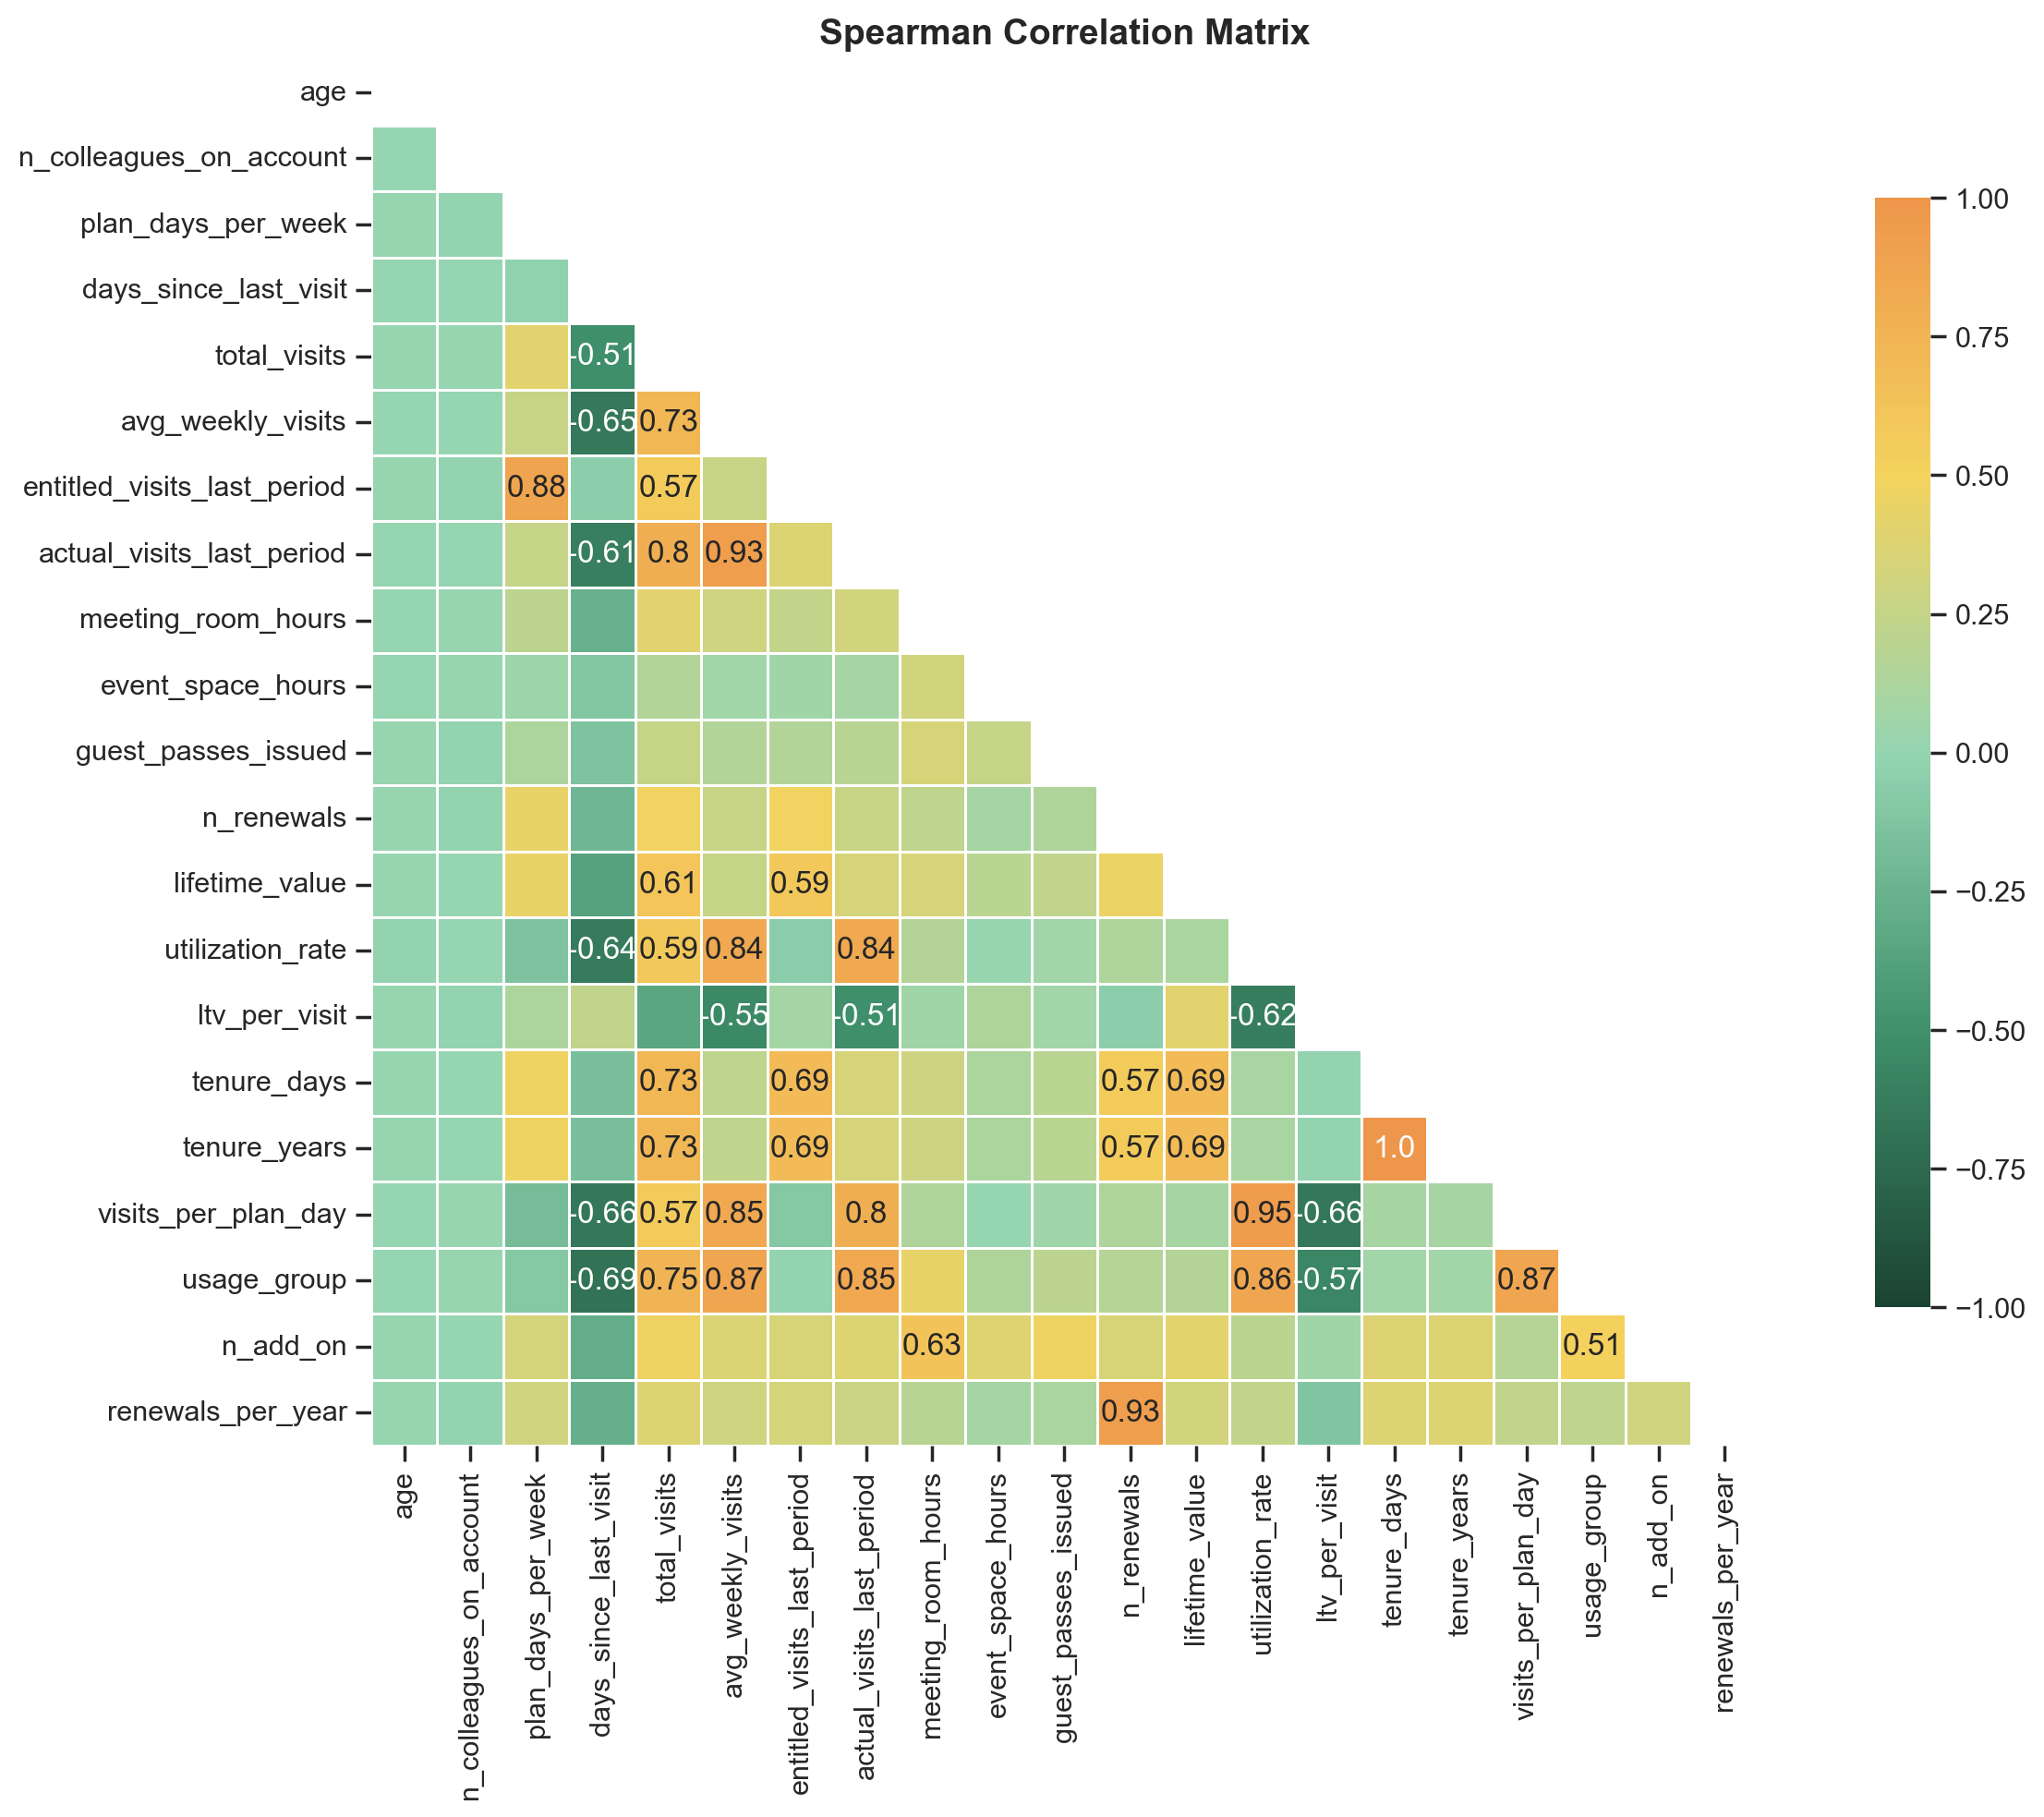

In [50]:
corr = df_nodups[metric_features].corr(method="spearman")
cmap = LinearSegmentedColormap.from_list(
    "smooth_div",
    colors,
    N=256,
)

corr = df_nodups[metric_features].corr(method="spearman").round(2)

mask_annot = np.absolute(corr.values) >= 0.5 
annot = np.where(mask_annot, corr.values, np.full(corr.shape,"")) 

mask_upper = np.triu(np.ones_like(corr, dtype=bool))

fig = plt.figure(figsize=(14, 10))

sns.heatmap(
    data=corr, 
    annot=annot, 
    fmt='s', 
    mask=mask_upper,         
    vmin=-1, vmax=1, 
    center=0, 
    square=True, 
    linewidths=.5, 
    cmap=cmap,              
    cbar_kws={"shrink": .8}   
)

plt.title("Spearman Correlation Matrix", fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

In [51]:
df_nodups["lifetime_value"].corr(df_nodups["actual_visits_last_period"], method="spearman").round(2)

np.float64(0.34)

Most of the strong Spearman correlations are expected given the meaning of the variables (the matrix only shows the values with an absolute value of at least 0.5):

- **Variables that carry almost the same information** have the highest correlations: `actual_visits_last_period` and `avg_weekly_visits` (0.93), `entitled_visits_last_period` and `plan_days_per_week` (0.88), `actual_visits_last_period` and `total_visits` (0.80). This redundancy matters for clustering, since using such variables together would give the same information extra weight.
- **Negative correlations** are also expected: customers with a high `days_since_last_visit` tend to have lower `avg_weekly_visits`, `actual_visits_last_period` and `total_visits`.
- **Extra services** (`meeting_room_hours`, `event_space_hours` and `guest_passes_issued`) show no strong correlation with each other, which is consistent with what we saw before.

The only less trivial result involves `lifetime_value`:

- It is similarly correlated with `entitled_visits_last_period` (0.59) and `total_visits` (0.61), but only weakly with `actual_visits_last_period` (0.34).
- This suggests that the revenue of a customer depends more on the plan they pay for and on how long they stay (`total_visits` is also related to `membership_start`) than on how much they used the space in the last period. It is consistent with a fixed fee for the plan, instead of a payment per visit, but we do not have information about how the plans are billed.



<b><font size="5" color="#FAA85E">6.3. Bivariate Analysis</font></b><br>  

<b><font size="4" color="#FAA85E">6.3.1. Contractual Features</font></b><br>  

<b><font size="3" color="#FAA85E">6.3.1.1. `entitled_visits_last_period` and `plan_days_per_week`</font></b><br>  

As expected, the correlation of 0.88 shows that customers who subscribe to more days per week are, in theory, entitled to more visits:

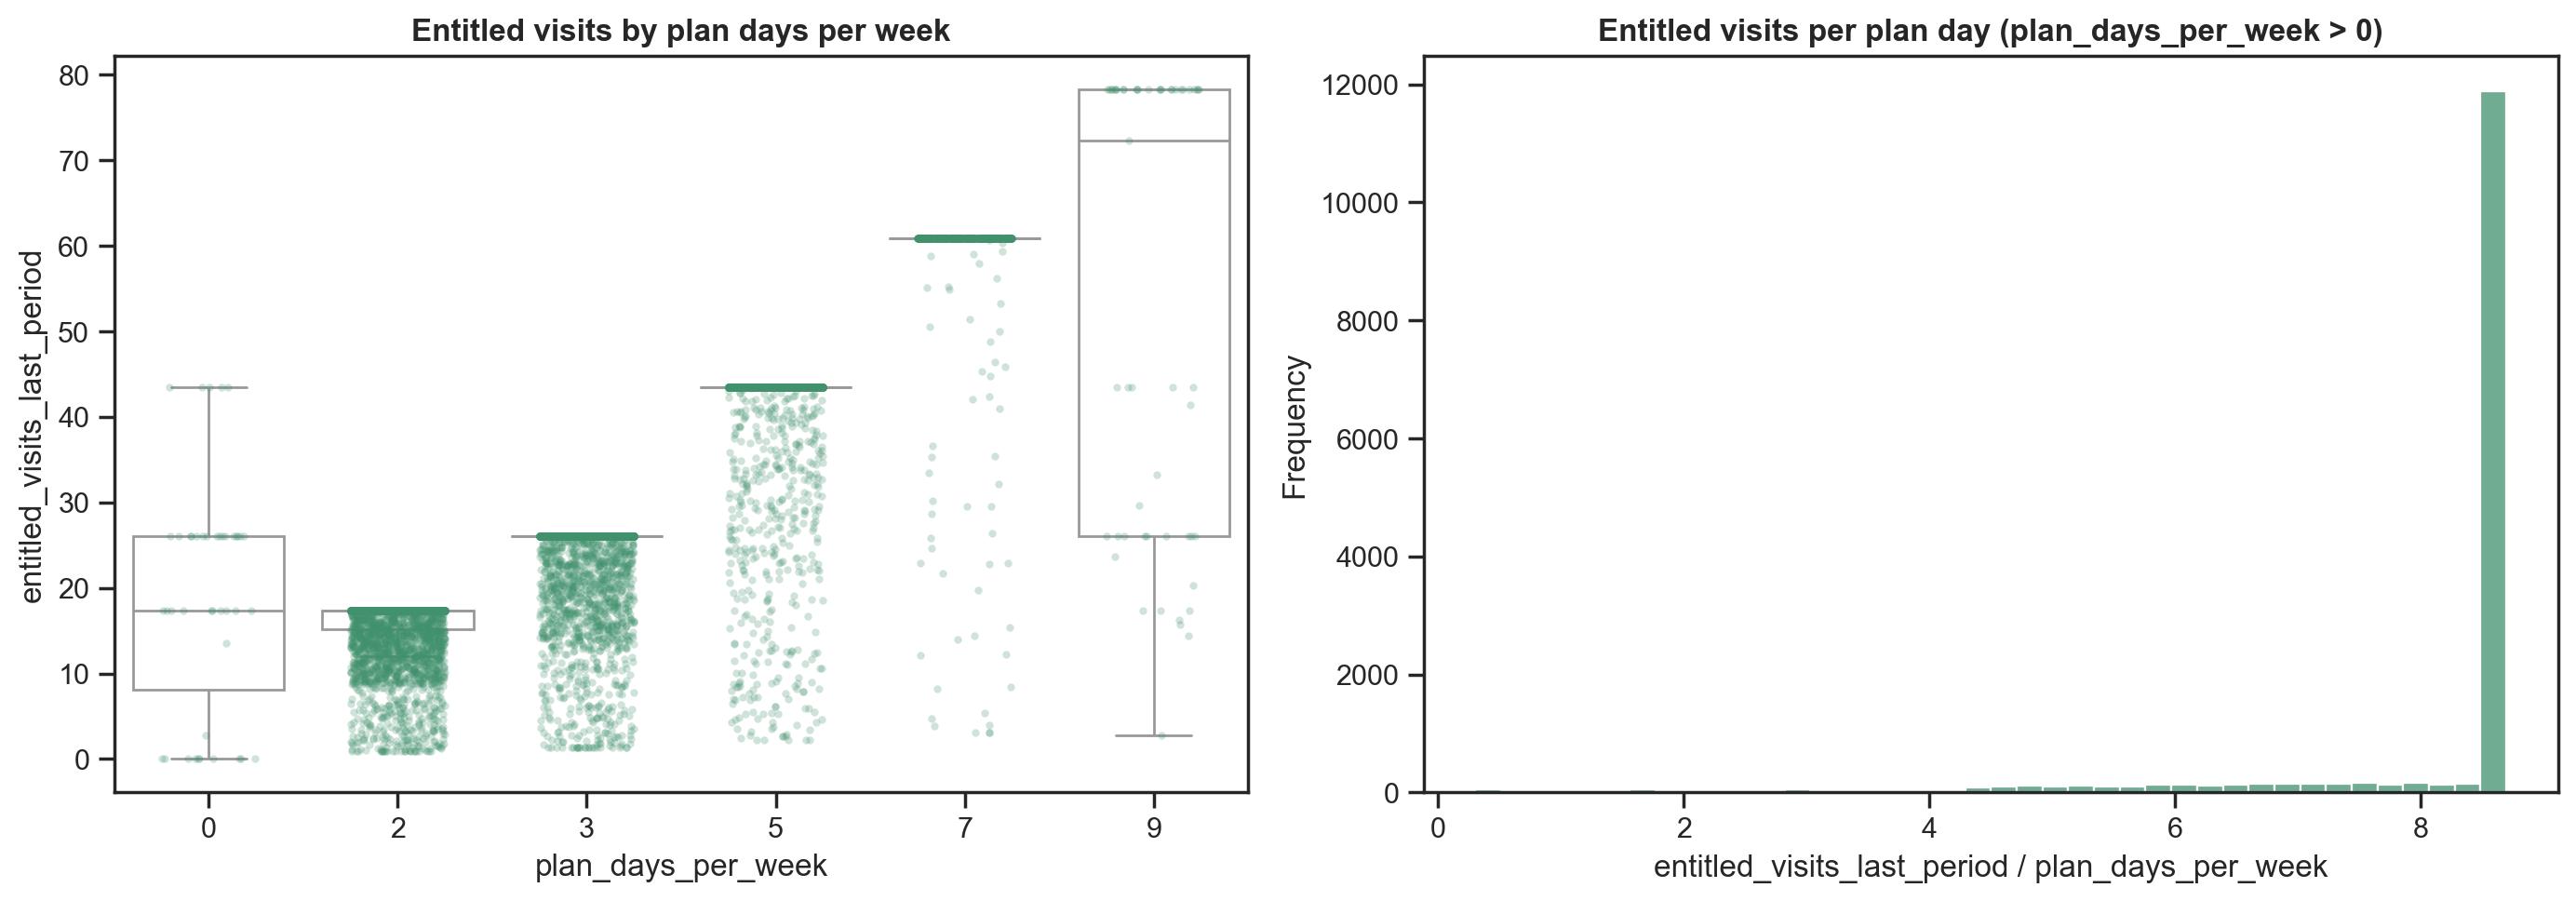

In [52]:
d = df_nodups.dropna(subset=["entitled_visits_last_period", "plan_days_per_week"]).copy()
d_pos = d[d["plan_days_per_week"] > 0].copy()
d_pos["entitled_per_plan_day"] = d_pos["entitled_visits_last_period"] / d_pos["plan_days_per_week"]

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=d, x="plan_days_per_week", y="entitled_visits_last_period",
            color="white", showfliers=False, ax=axes[0])
sns.stripplot(data=d, x="plan_days_per_week", y="entitled_visits_last_period",
              color=main_color, alpha=0.25, size=3, jitter=0.25, ax=axes[0])
axes[0].set_title('Entitled visits by plan days per week', fontweight="bold")
axes[0].set_xlabel('plan_days_per_week')
axes[0].set_ylabel('entitled_visits_last_period')

sns.histplot(d_pos["entitled_per_plan_day"], bins=40, color=main_color, ax=axes[1])
axes[1].set_title('Entitled visits per plan day (plan_days_per_week > 0)', fontweight="bold")
axes[1].set_xlabel('entitled_visits_last_period / plan_days_per_week')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

The left plot shows that each plan has a clear maximum number of entitled visits for the period, which grows with the plan days per week: about 17 visits for the 2-day plan, 26 for the 3-day plan, 43 for the 5-day plan and 61 for the 7-day plan (the plan days times 8.7 weeks).

The plots also show suspicious records. Plans with 9 days per week are impossible (a week has 7 days), and the entitled visits of some of these customers reach 78, which is exactly 9 × 8.7, so the invalid value was used in the calculation. Customers with 0 days have entitled visits of about 17, 26 or 43, which match the plans of 2, 3 and 5 days, so 0 is probably a data entry error. In both cases there are very few customers.

<b><font size="3" color="#FAA85E">6.3.1.2. `actual_visits_last_period` and `entitled_visits_last_period`</font></b><br>   

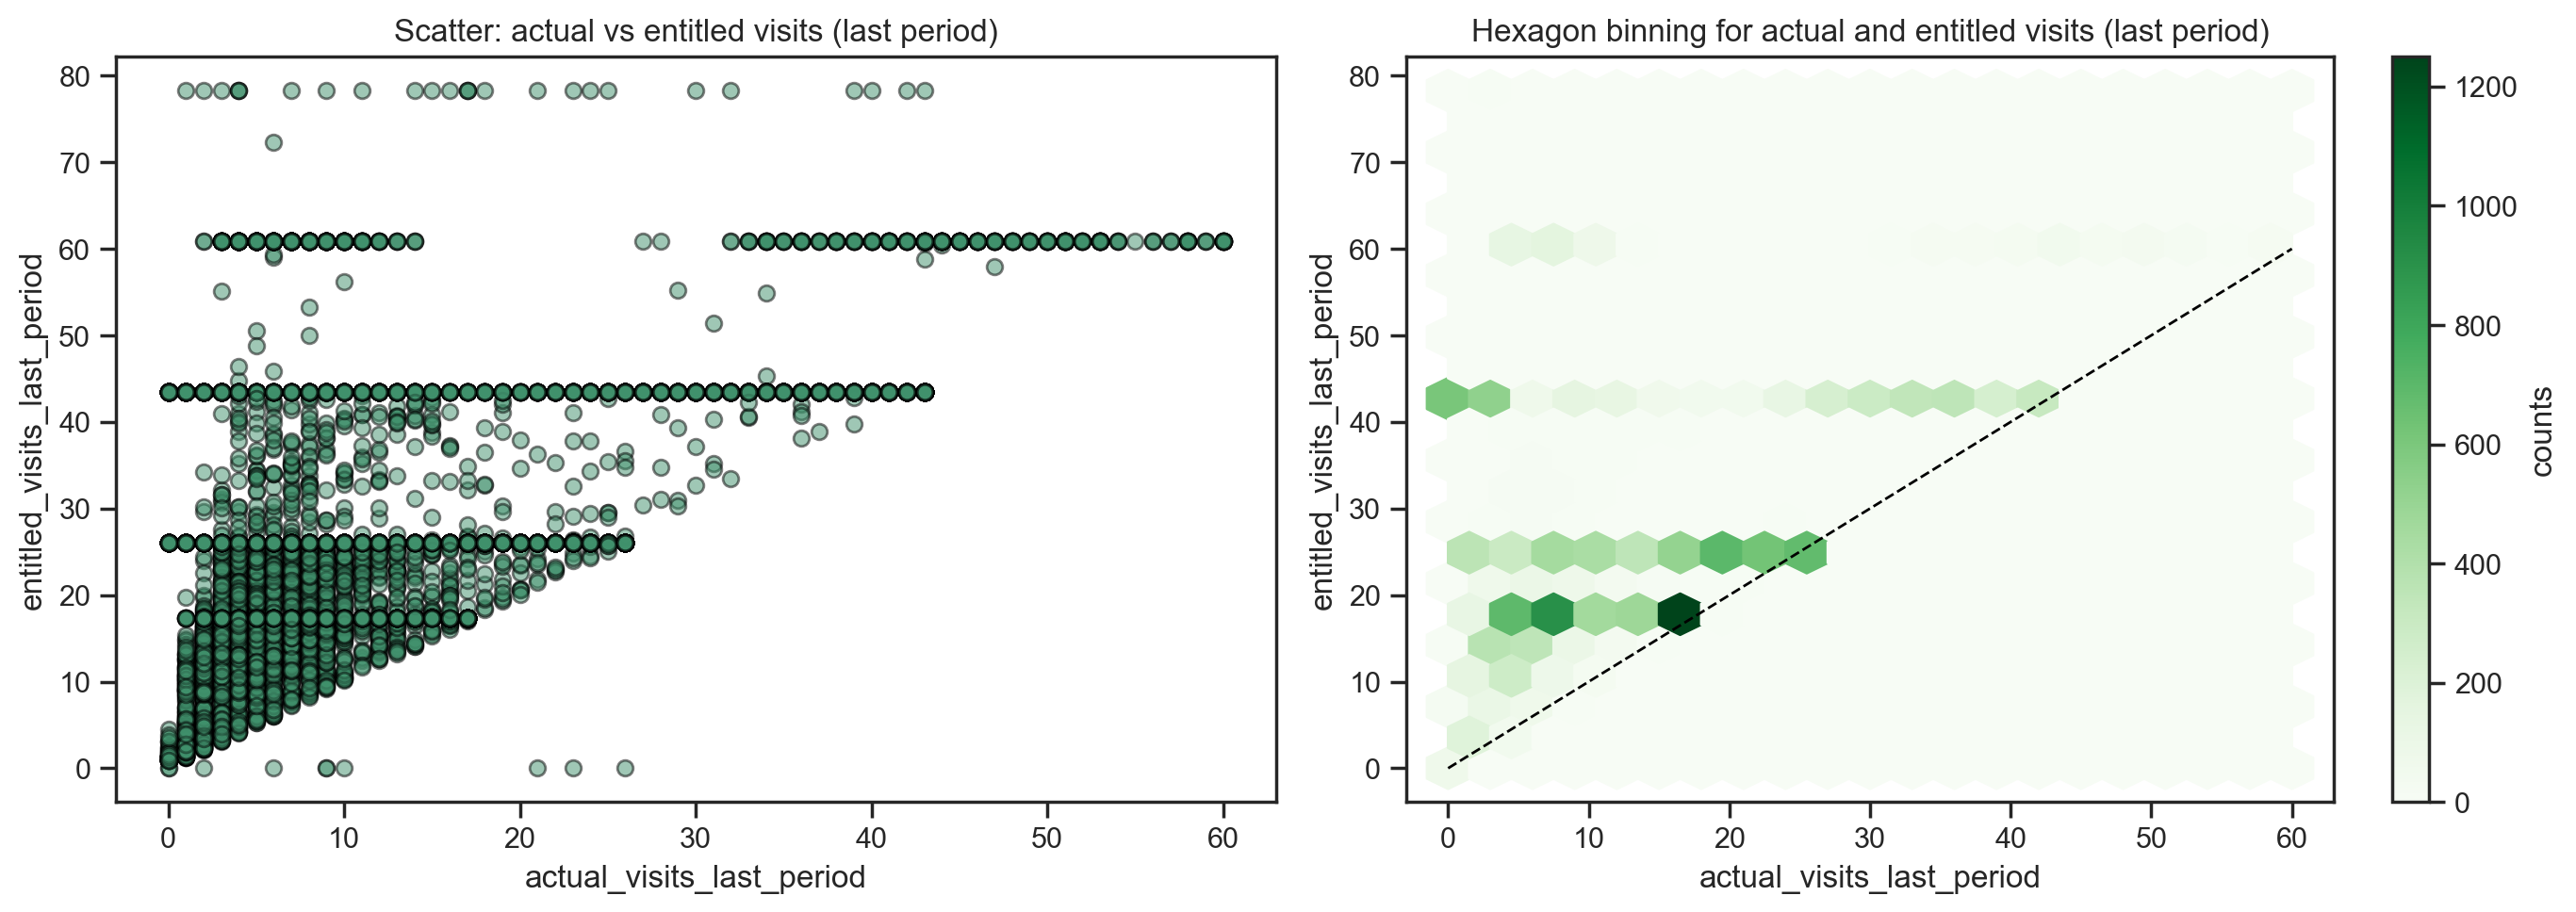

In [53]:
sns.set_style('ticks')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1) Scatter
ax1.scatter(df_nodups["actual_visits_last_period"], df_nodups["entitled_visits_last_period"],
            edgecolors="black",
            alpha=.5,
            color=main_color
           )
ax1.set_title("Scatter: actual vs entitled visits (last period)")
ax1.set_xlabel("actual_visits_last_period")
ax1.set_ylabel("entitled_visits_last_period")

# 2) Hexbin
hb = ax2.hexbin(df_nodups["actual_visits_last_period"], df_nodups["entitled_visits_last_period"],
                gridsize=20,
                cmap='Greens'
               )
ax2.plot([0, 60], [0, 60], color="black", linestyle="--", linewidth=1)

ax2.set_title("Hexagon binning for actual and entitled visits (last period)")
cb = fig.colorbar(hb, ax=ax2, label='counts')
ax2.set_xlabel("actual_visits_last_period")
ax2.set_ylabel("entitled_visits_last_period")

plt.tight_layout()
plt.show()

The dashed line represents full use of the plan: the customer made exactly as many visits as they are entitled to. Almost no customer is below this line, which means that almost no one exceeds their entitlement. Most customers are above the line, so they use only part of their plan. However, the densest hexagon (about 17 visits made, for an entitlement of about 17) is right on the line, so there is also a relevant group of customers, mostly with the 2-day plan, who use their plan almost fully.

In [54]:
d = df_nodups.dropna(subset=["actual_visits_last_period", "entitled_visits_last_period"])
mask = (d["actual_visits_last_period"] <= 5) & (d["entitled_visits_last_period"].between(40, 45))

print("Customers in the circled area:", mask.sum())
print("Share with days_since_last_visit == 999:", (d.loc[mask, "days_since_last_visit"] == 999).mean().round(3))
d.loc[mask, "lifetime_value"].describe().round(1)

Customers in the circled area: 1168
Share with days_since_last_visit == 999: 0.133


count      1064.0
mean       7761.1
std       26164.0
min      -11948.6
25%        4692.0
50%        7580.5
75%        9655.6
max      734531.0
Name: lifetime_value, dtype: float64

There is also a group of about 1200 customers with the 5-day plan (entitlement of about 43 visits) who made almost no visits in the last period. We checked if these could be the incomplete records with the code 999 in `days_since_last_visit`: only about 13% of them have this code (against about 8% in the whole dataset), and their `lifetime_value` is not low (median of about 7600, against about 1700 for all customers), although this may simply reflect the price of the 5-day plan. So they do not look like incomplete records. 

This group seems relevant for the segmentation, and we characterise it in more detail later (for example, whether they are still active and how they renew).

<b><font size="3" color="#FAA85E">6.3.1.3. `avg_weekly_visits` and `plan_days_per_week`</font></b><br>   

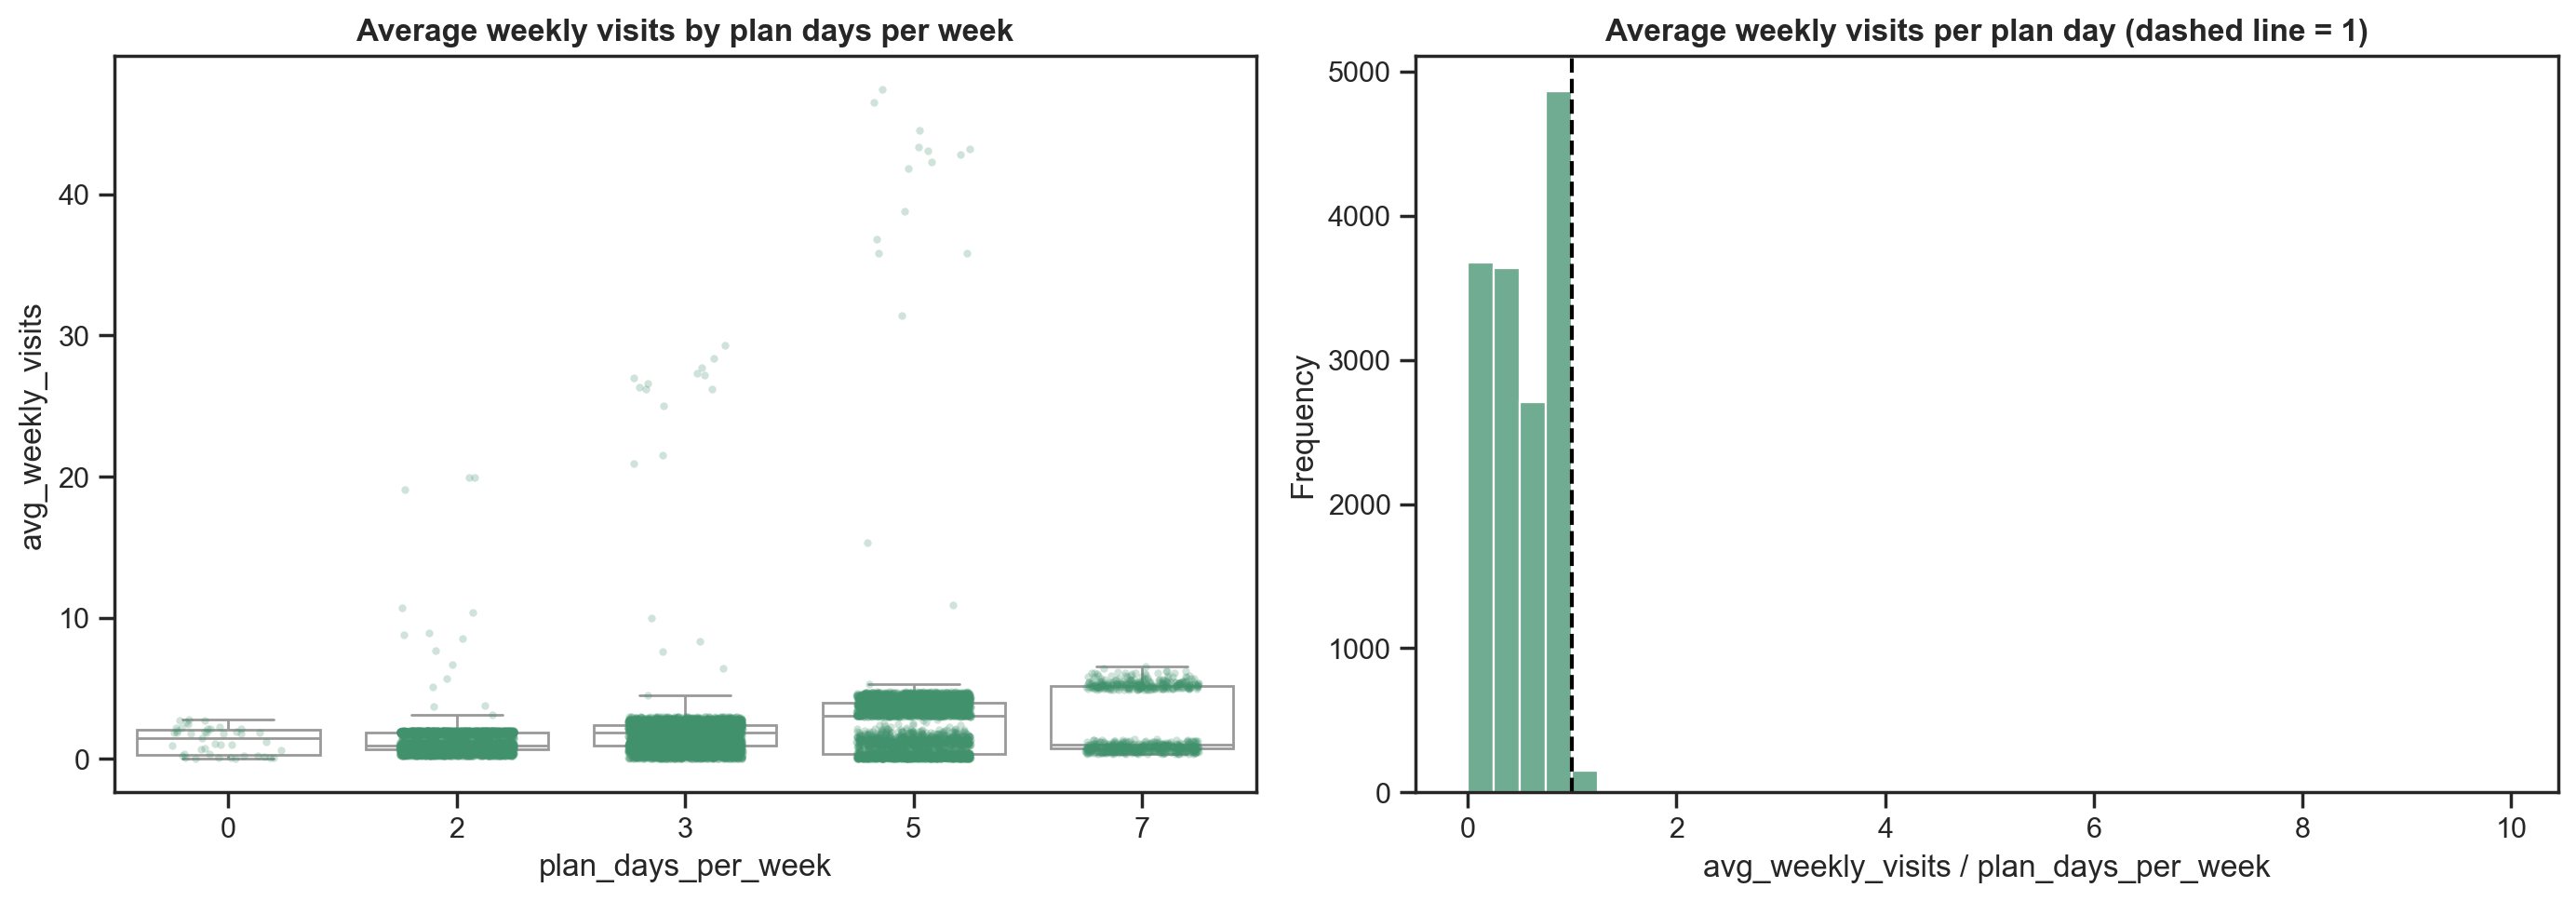

In [55]:
d = df_nodups[df_nodups["plan_days_per_week"] <= 7].dropna(subset=["avg_weekly_visits", "plan_days_per_week"]).copy()
d_pos = d[d["plan_days_per_week"] > 0].copy()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.boxplot(data=d, x="plan_days_per_week", y="avg_weekly_visits", color="white", showfliers=False, ax=axes[0])
sns.stripplot(data=d, x="plan_days_per_week", y="avg_weekly_visits", color=main_color,
              alpha=0.25, size=3, jitter=0.25, ax=axes[0])
axes[0].set_title('Average weekly visits by plan days per week', fontweight="bold")
axes[0].set_xlabel('plan_days_per_week')
axes[0].set_ylabel('avg_weekly_visits')

sns.histplot(d_pos["visits_per_plan_day"], bins=40, color=main_color, ax=axes[1])
axes[1].axvline(1, color="black", linestyle="--")
axes[1].set_title('Average weekly visits per plan day (dashed line = 1)', fontweight="bold")
axes[1].set_xlabel('avg_weekly_visits / plan_days_per_week')
axes[1].set_ylabel('Frequency')

plt.tight_layout()
plt.show()

The left plot shows that customers with more plan days tend to visit slightly more, but the difference is small compared to the difference between plans: the median is only about 1 to 2 visits per week even in the 5-day and 7-day plans. In these two plans the points form two clearly separated groups: one with low use (around 1 visit per week) and another with high use (about 4 to 6 visits per week). This suggests two types of customers with very different behaviour in the plans with more days, which supports our previous conclusion. A few extreme points above 7 visits per week are the invalid values we already identified.

The right plot shows the visits per plan day: almost all customers are below 1, so almost nobody goes more days than their plan allows. There is a group of customers with low use (below 0.5) and a large group that is close to the limit (between 0.75 and 1), so the customers are not spread evenly.

Because of this, the low-use customers in the 5-day and 7-day plans are the most interesting group. Are they "asleep" customers? Do they keep paying just in case they need the space? We evaluate this later.

<b><font size="3" color="#FAA85E">6.3.1.4. `total_visits` and `entitled_visits_last_period`</font></b><br>    

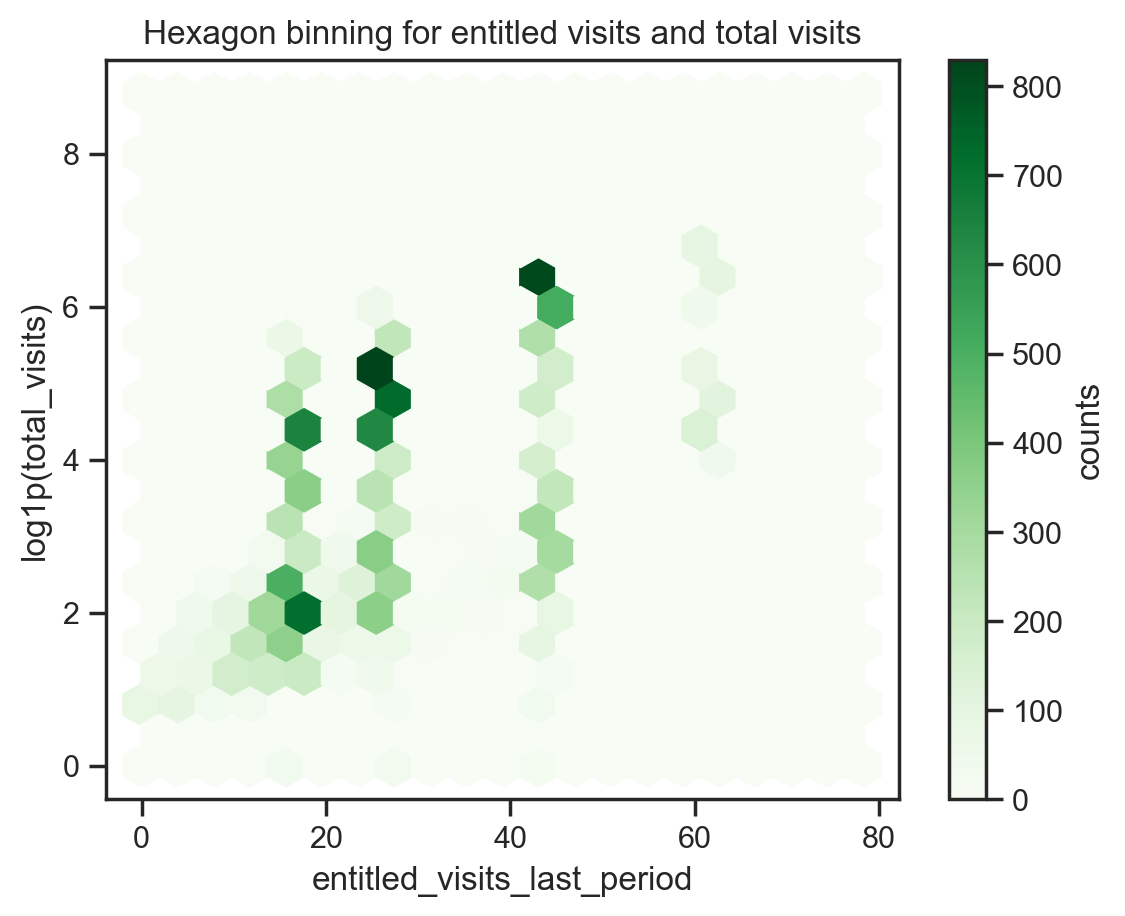

In [56]:
sns.set_style('ticks')

fig, ax = plt.subplots()

subset = df_nodups[["entitled_visits_last_period", "total_visits"]].dropna()
subset = subset[subset["total_visits"] >= 0]

hb = ax.hexbin(subset["entitled_visits_last_period"], np.log1p(subset["total_visits"]), 
                gridsize=20,
               cmap='Greens'
              )

ax.set_title("Hexagon binning for entitled visits and total visits")
cb = fig.colorbar(hb, ax=ax, label='counts')

plt.xlabel("entitled_visits_last_period")
plt.ylabel("log1p(total_visits)")
plt.show()

The plot shows one vertical column for each plan, since the entitled visits take only a few values, as we concluded. Within each plan the total visits vary a lot, which is expected because it is a cumulative value that depends on how long each customer has been a member. Still, the densest areas move upwards as the plan gets larger, from a few visits in the 2-day plan to hundreds in the 5-day plan, which is consistent with the correlation we saw before. The diffuse area at the bottom left corresponds to customers with lower entitled visits and few total visits, which may be recent customers with a partial period, but this needs to be confirmed.

<b><font size="3" color="#FAA85E">6.3.1.5. `utilization_rate` (an enginereed variable) </font></b><br>    

After analysing all these variables, we consider it particularly relevant to understand how customers are behaving, especially for the clustering, since fewer visits may mean more dissatisfaction and a possible cancellation (or non-renewal) of the plan in the future. For this, we create a new variable, the utilization rate, which is the number of actual visits divided by the number of entitled visits in the last period. It puts all customers on the same scale (from 0 to 1), regardless of their plan, which makes them easier to compare.

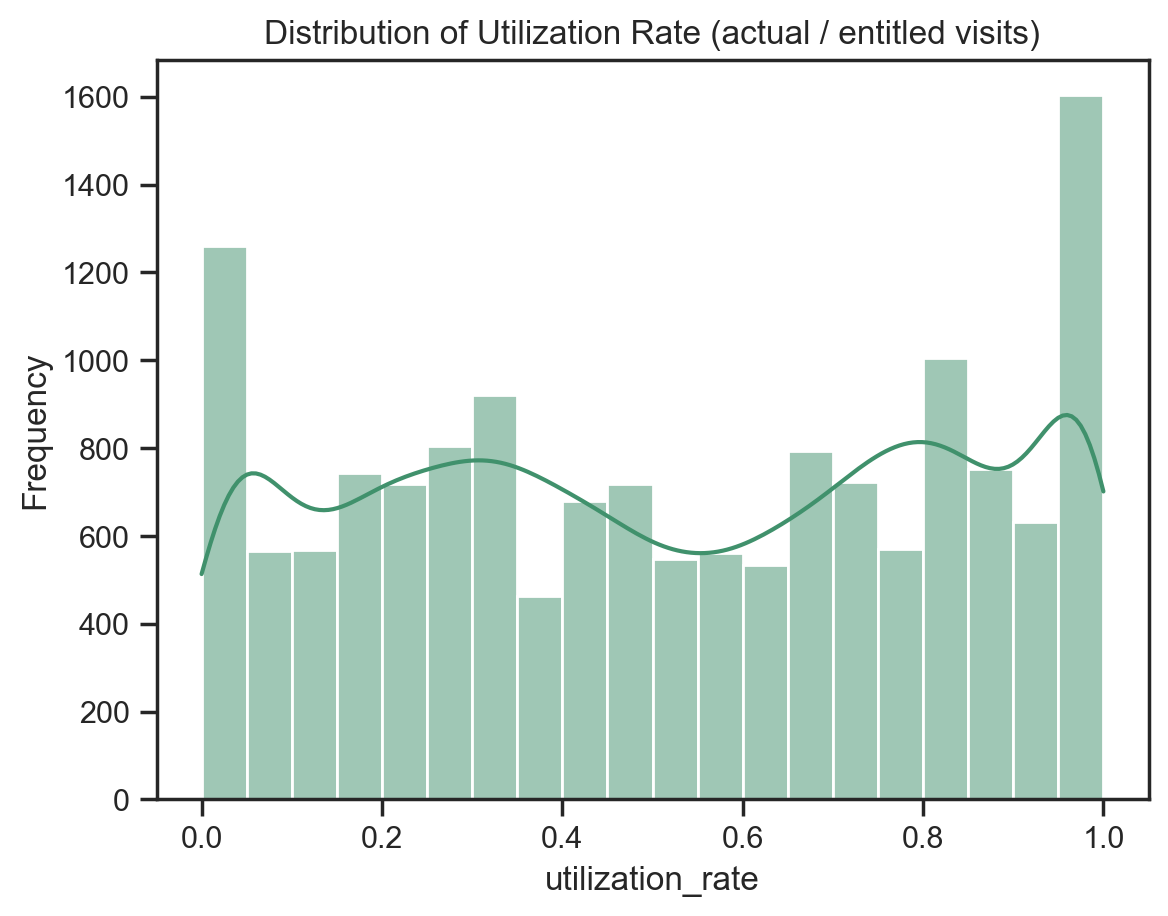

In [57]:
sns.set_style("ticks")

sns.histplot(df_nodups['utilization_rate'].dropna(), bins=20, kde=True, color = main_color)

plt.title('Distribution of Utilization Rate (actual / entitled visits)')
plt.xlabel('utilization_rate')
plt.ylabel('Frequency')
plt.show()

The distribution is spread over the whole range, with two peaks at the ends: a group of customers who used almost nothing of their plan in the last period, and a group who used it almost fully. Most customers are below full use, but not all of them, so customers behave very differently. This makes this variable a good candidate for the clustering, instead of using `actual_visits_last_period` and `entitled_visits_last_period` separately (and the other variables that are closely related to them).

<b><font size="4" color="#FAA85E">6.3.2. Temporal Proximity vs Frequency</font></b><br>  

<b><font size="3" color="#FAA85E">6.3.2.1. `days_since_last_visit` and `avg_weekly_visits`</font></b><br> 

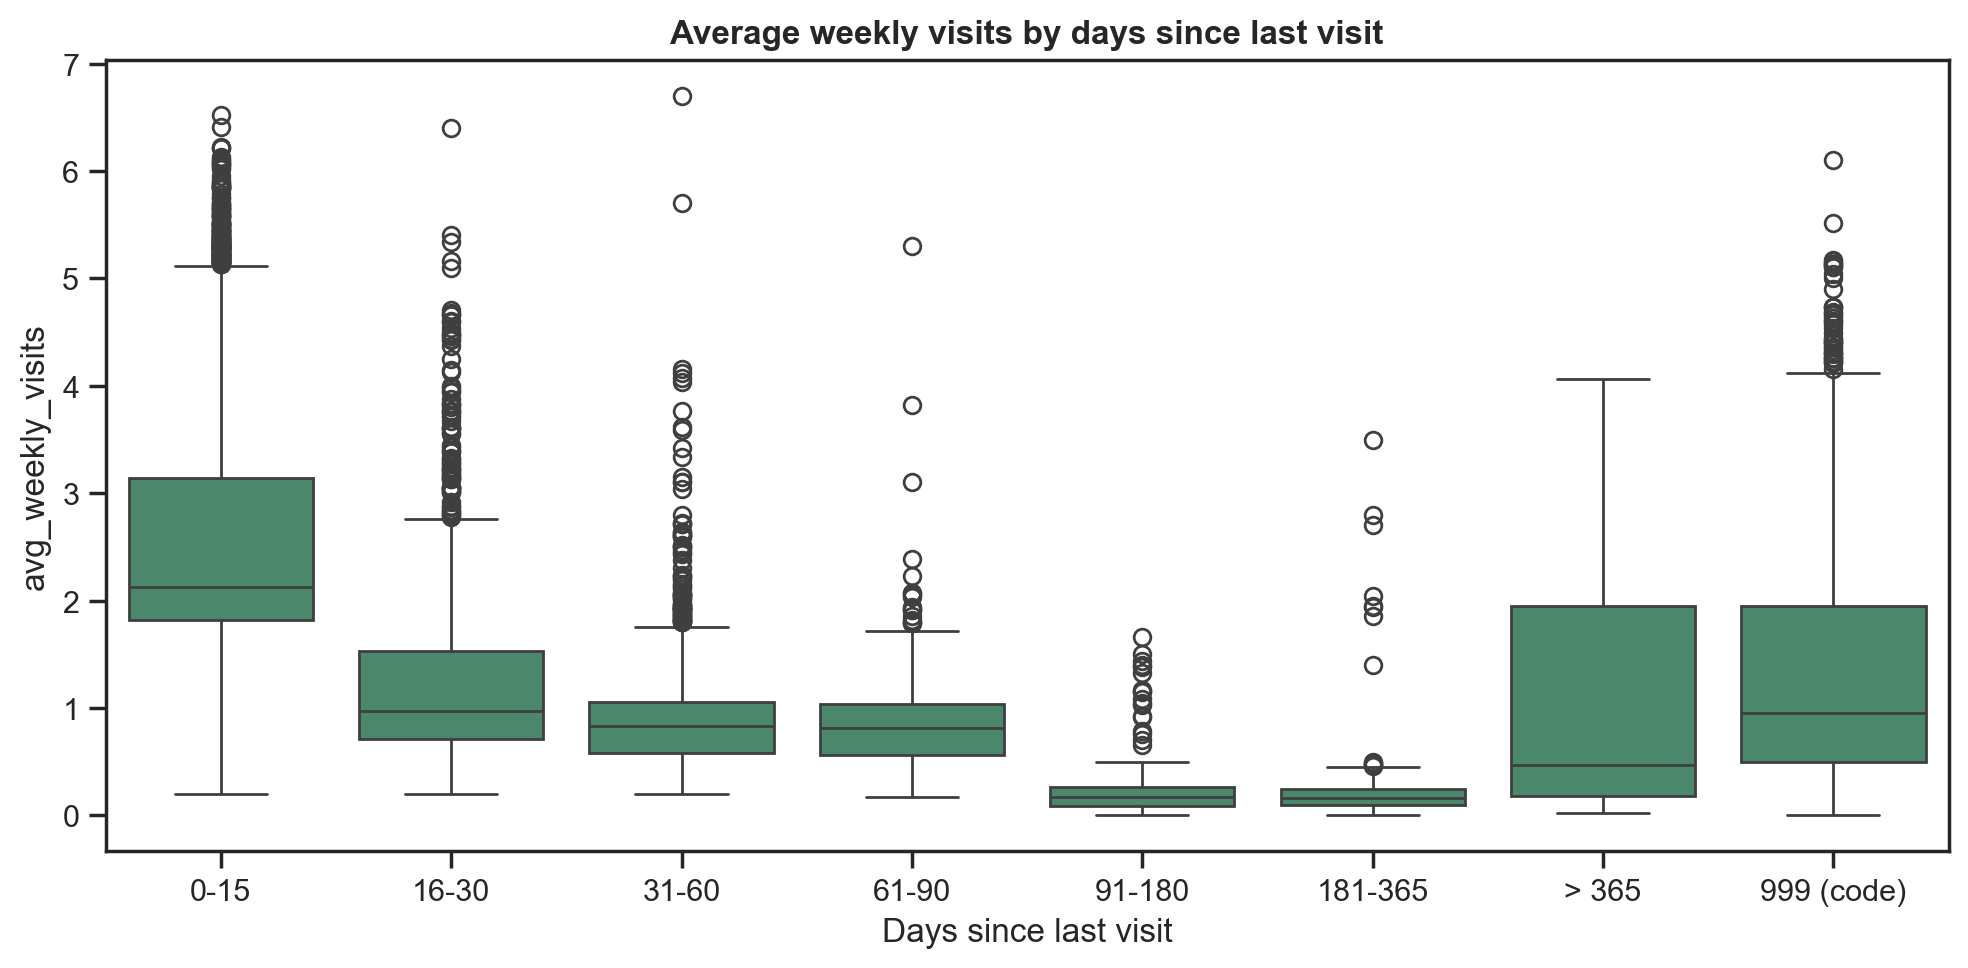

In [58]:
d = df_nodups[(df_nodups["days_since_last_visit"] >= 0) & (df_nodups["avg_weekly_visits"].between(0, 7))].copy()

bins = [-1, 15, 30, 60, 90, 180, 365, np.inf]
labels = ["0-15", "16-30", "31-60", "61-90", "91-180", "181-365", "> 365"]

d["recency"] = pd.cut(d["days_since_last_visit"], bins=bins, labels=labels).astype(object)
d.loc[d["days_since_last_visit"] == 999, "recency"] = "999 (code)"

order = labels + ["999 (code)"]

fig, ax = plt.subplots(figsize=(10, 5))
sns.boxplot(data=d, x="recency", y="avg_weekly_visits", order=order, color=main_color, ax=ax)

ax.set_title("Average weekly visits by days since last visit", fontweight="bold")
ax.set_xlabel("Days since last visit")
ax.set_ylabel("avg_weekly_visits")
plt.tight_layout()
plt.show()

The plot shows that customers who have not visited the space for longer tend to have a lower average number of weekly visits. The median is about 2 visits per week for customers who visited in the last 15 days, drops to about 1 for gaps between 16 and 90 days, and falls to almost 0 (about one visit every 7 weeks) after 90 days, so these customers have a very low use of the space. The code 999 behaves like customers with recent visits (median of about 1 visit per week), not like inactive ones, which supports what we saw before. 

The group with more than 365 days has very few customers, so we do not interpret it. Part of this relationship is expected, since `avg_weekly_visits` is an average over the whole membership, so a long period without visits lowers it.

<b><font size="3" color="#FAA85E">6.3.2.2. `actual_visits_last_period` and `avg_weekly_visits` , `total_visits` and `actual_visits_last_period`,  `total_visits` and `avg_weekly_visits` </font></b><br> 

The three variables compared here measure the number of visits in different ways. They are strongly correlated, as we saw in the correlation matrix, so what is more interesting is to look for customers who do not follow the general pattern. 

For example, customers with many total visits but few visits in the last period may be customers who used to go often and have reduced their use, while customers with few total visits but many recent visits may be recent members. These comparisons also help us decide which of these variables to keep for the clustering. Since all of them are strongly right-skewed, we use a logarithmic transformation (`log1p`) in the plots.

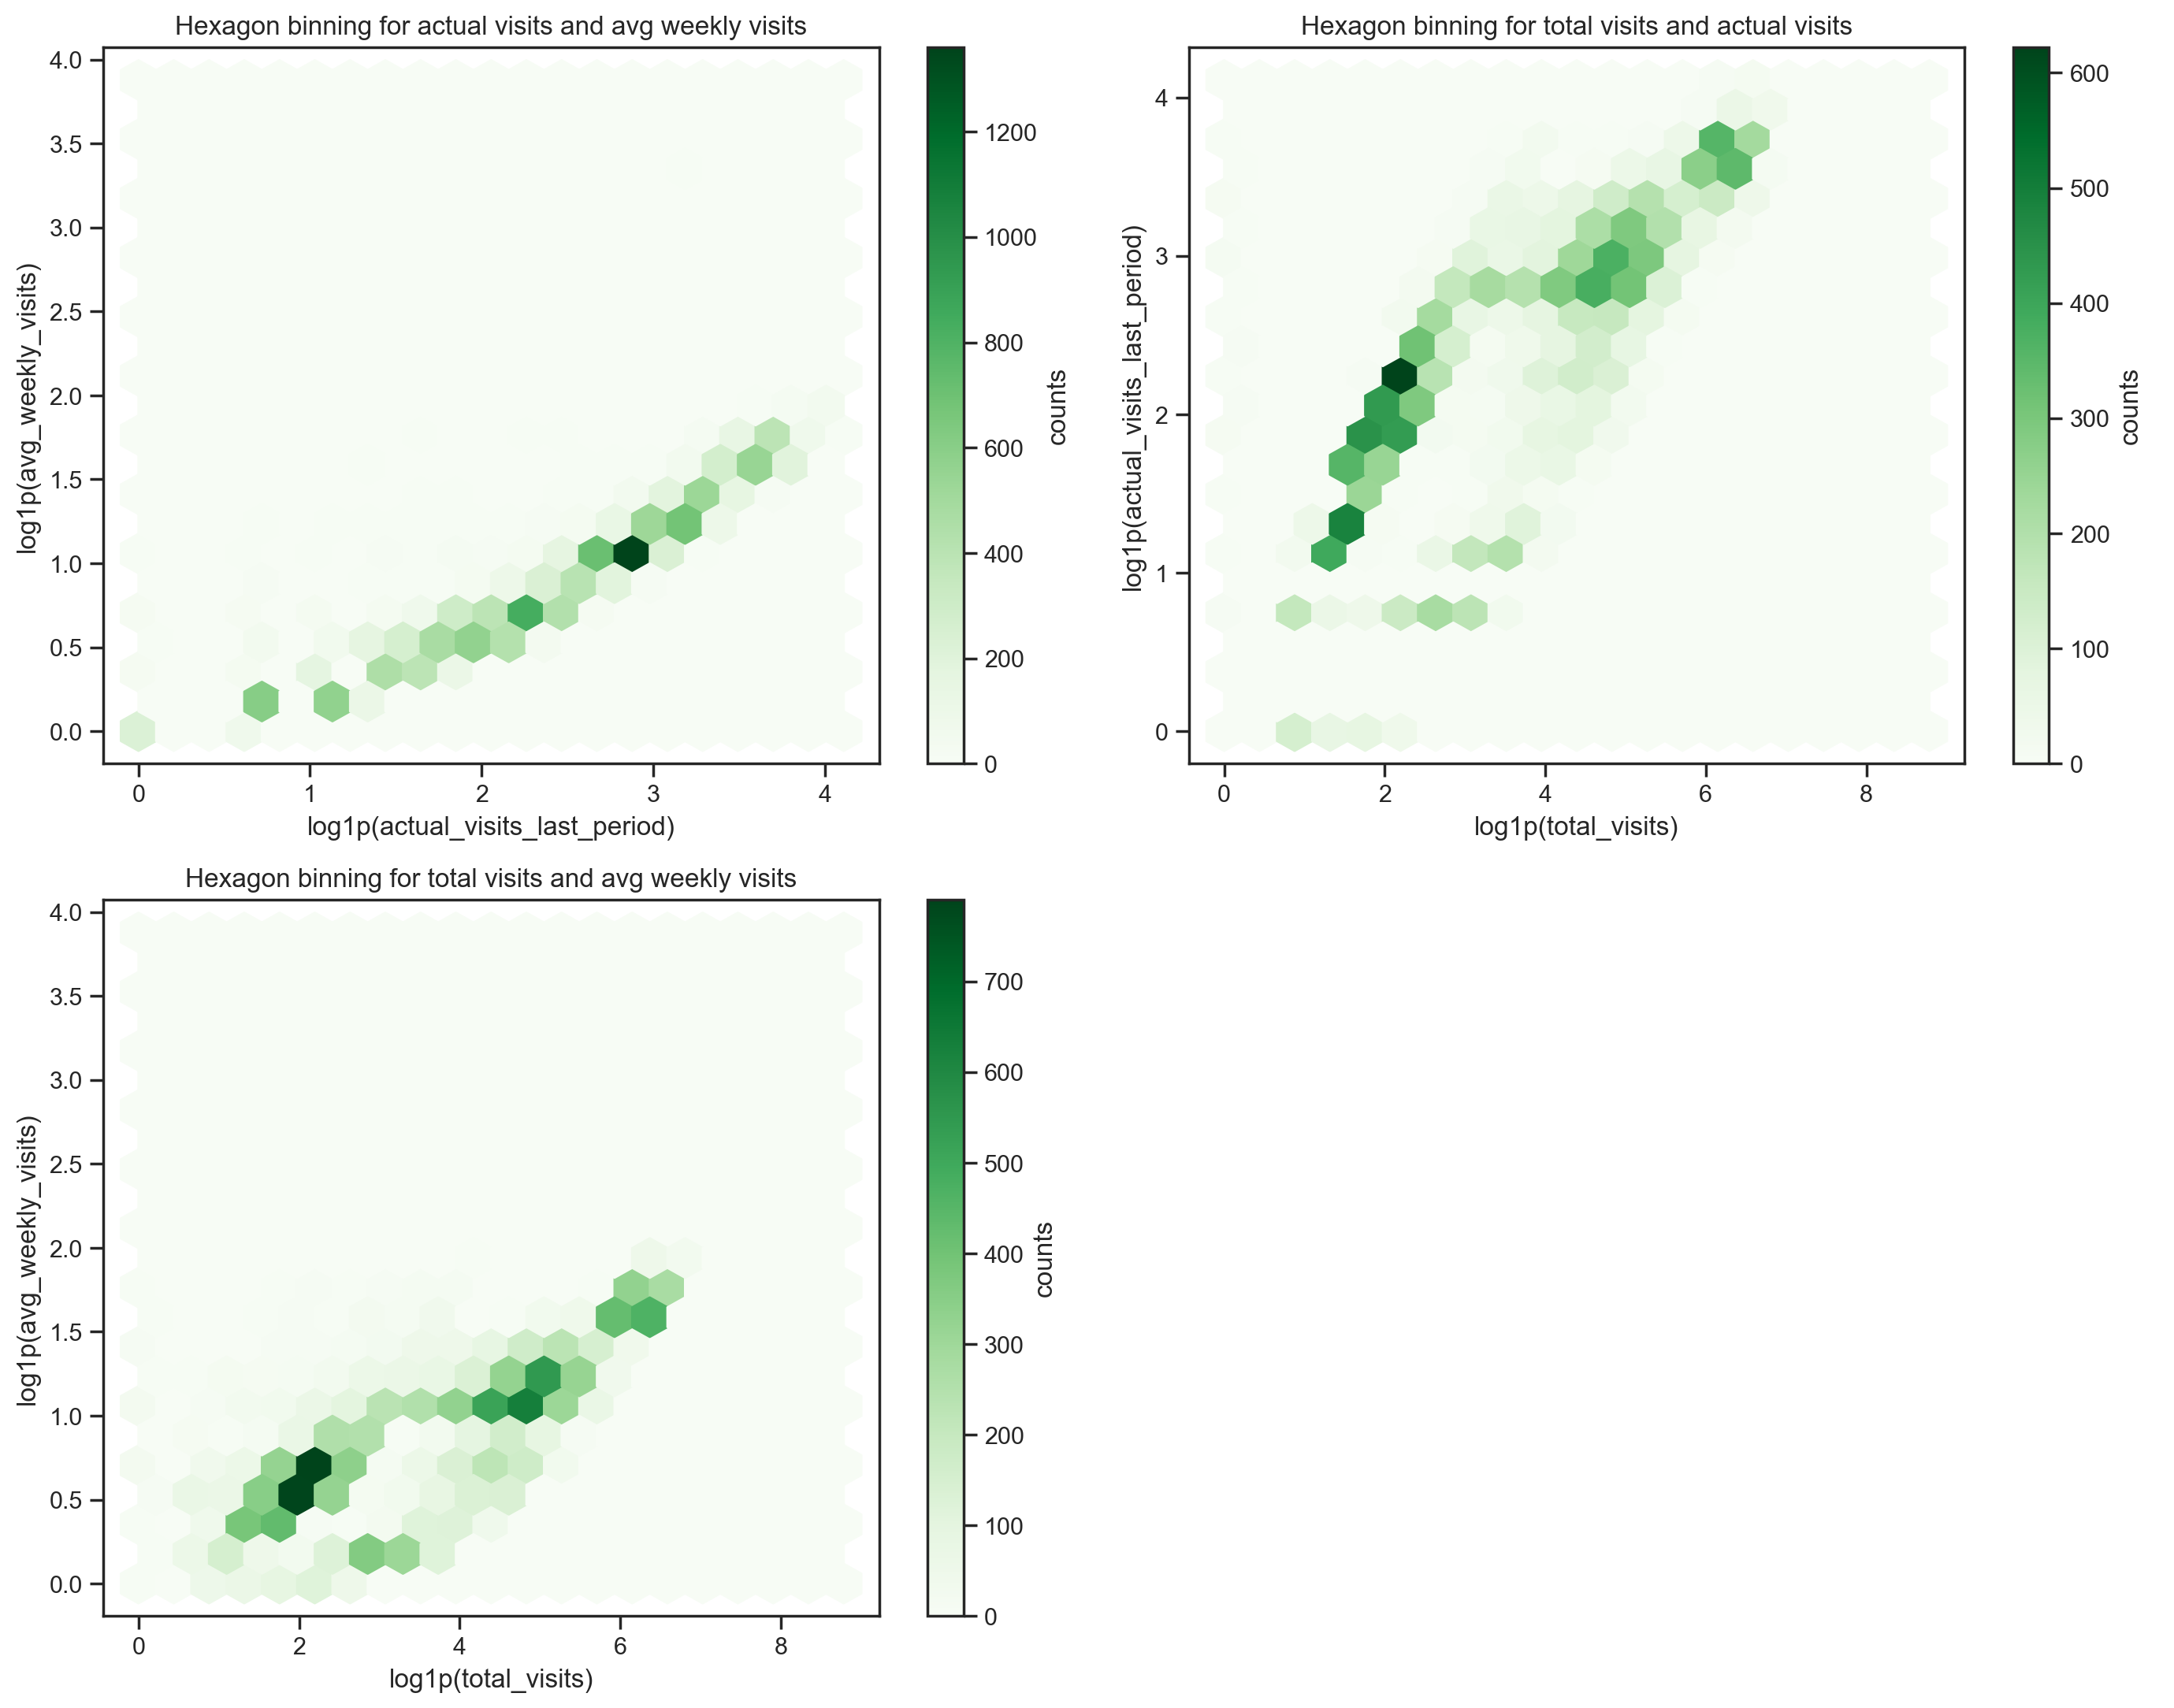

In [59]:
sns.set_style('ticks')

pairs = [
    ("actual_visits_last_period", "avg_weekly_visits", "Hexagon binning for actual visits and avg weekly visits"),
    ("total_visits", "actual_visits_last_period", "Hexagon binning for total visits and actual visits"),
    ("total_visits", "avg_weekly_visits", "Hexagon binning for total visits and avg weekly visits"),
]

sp_rows = 2
sp_cols = 2

fig, axes = plt.subplots(sp_rows,
                         sp_cols,
                         figsize=(14, 11))

axes = axes.flatten()

for ax, (x, y, title) in zip(axes, pairs):
    subset = df_nodups[[x, y]].dropna()
    subset = subset[(subset[x] >= 0) & (subset[y] >= 0)]

    hb = ax.hexbin(np.log1p(subset[x]), np.log1p(subset[y]),
                   gridsize=20,
                   cmap='Greens'
                  )

    ax.set_title(title)
    cb = fig.colorbar(hb, ax=ax, label='counts')
    ax.set_xlabel(f"log1p({x})")
    ax.set_ylabel(f"log1p({y})")

# Hide the unused subplot
axes[-1].axis("off")

plt.tight_layout()
plt.show()

**Actual visits vs avg weekly visits**
- The points follow a very narrow curve, so these two variables are almost the same measure on a different scale: the weekly average is approximately the actual visits divided by the number of weeks of the period (about 8.7).
- For clustering, it is enough to keep only one of them.

**Total visits vs actual visits**
- There is a clear positive relationship: customers with more total visits also tend to have more visits in the last period.
- The densest area is along a narrow diagonal at low values, where total visits and last period visits are almost equal. These customers made most of their visits in the last period, so they are probably recent members.
- Another wider band at high total visits corresponds to long-standing customers, with several hundred total visits but only a few tens in the last period.
- The points below the main band (many total visits, few recent ones) may be customers who used to go often and have reduced their use. A few customers have total visits but none in the last period.

**Total visits vs avg weekly visits**
- The relation is also positive, with a dense group of customers with few total visits and low frequency (about 1 visit per week), and a second group with hundreds of visits and 2 to 3 visits per week.
- In the top right there is a small group of very frequent and long-standing customers (around 5 visits per week).
- This supports the idea that there are different types of customers: newer and occasional ones, and long-standing and regular ones.

<b><font size="3" color="#FAA85E">6.3.2.3. `days_since_last_visit` and `actual_visits_last_period`, `days_since_last_visit` and `total_visits` </font></b><br>  

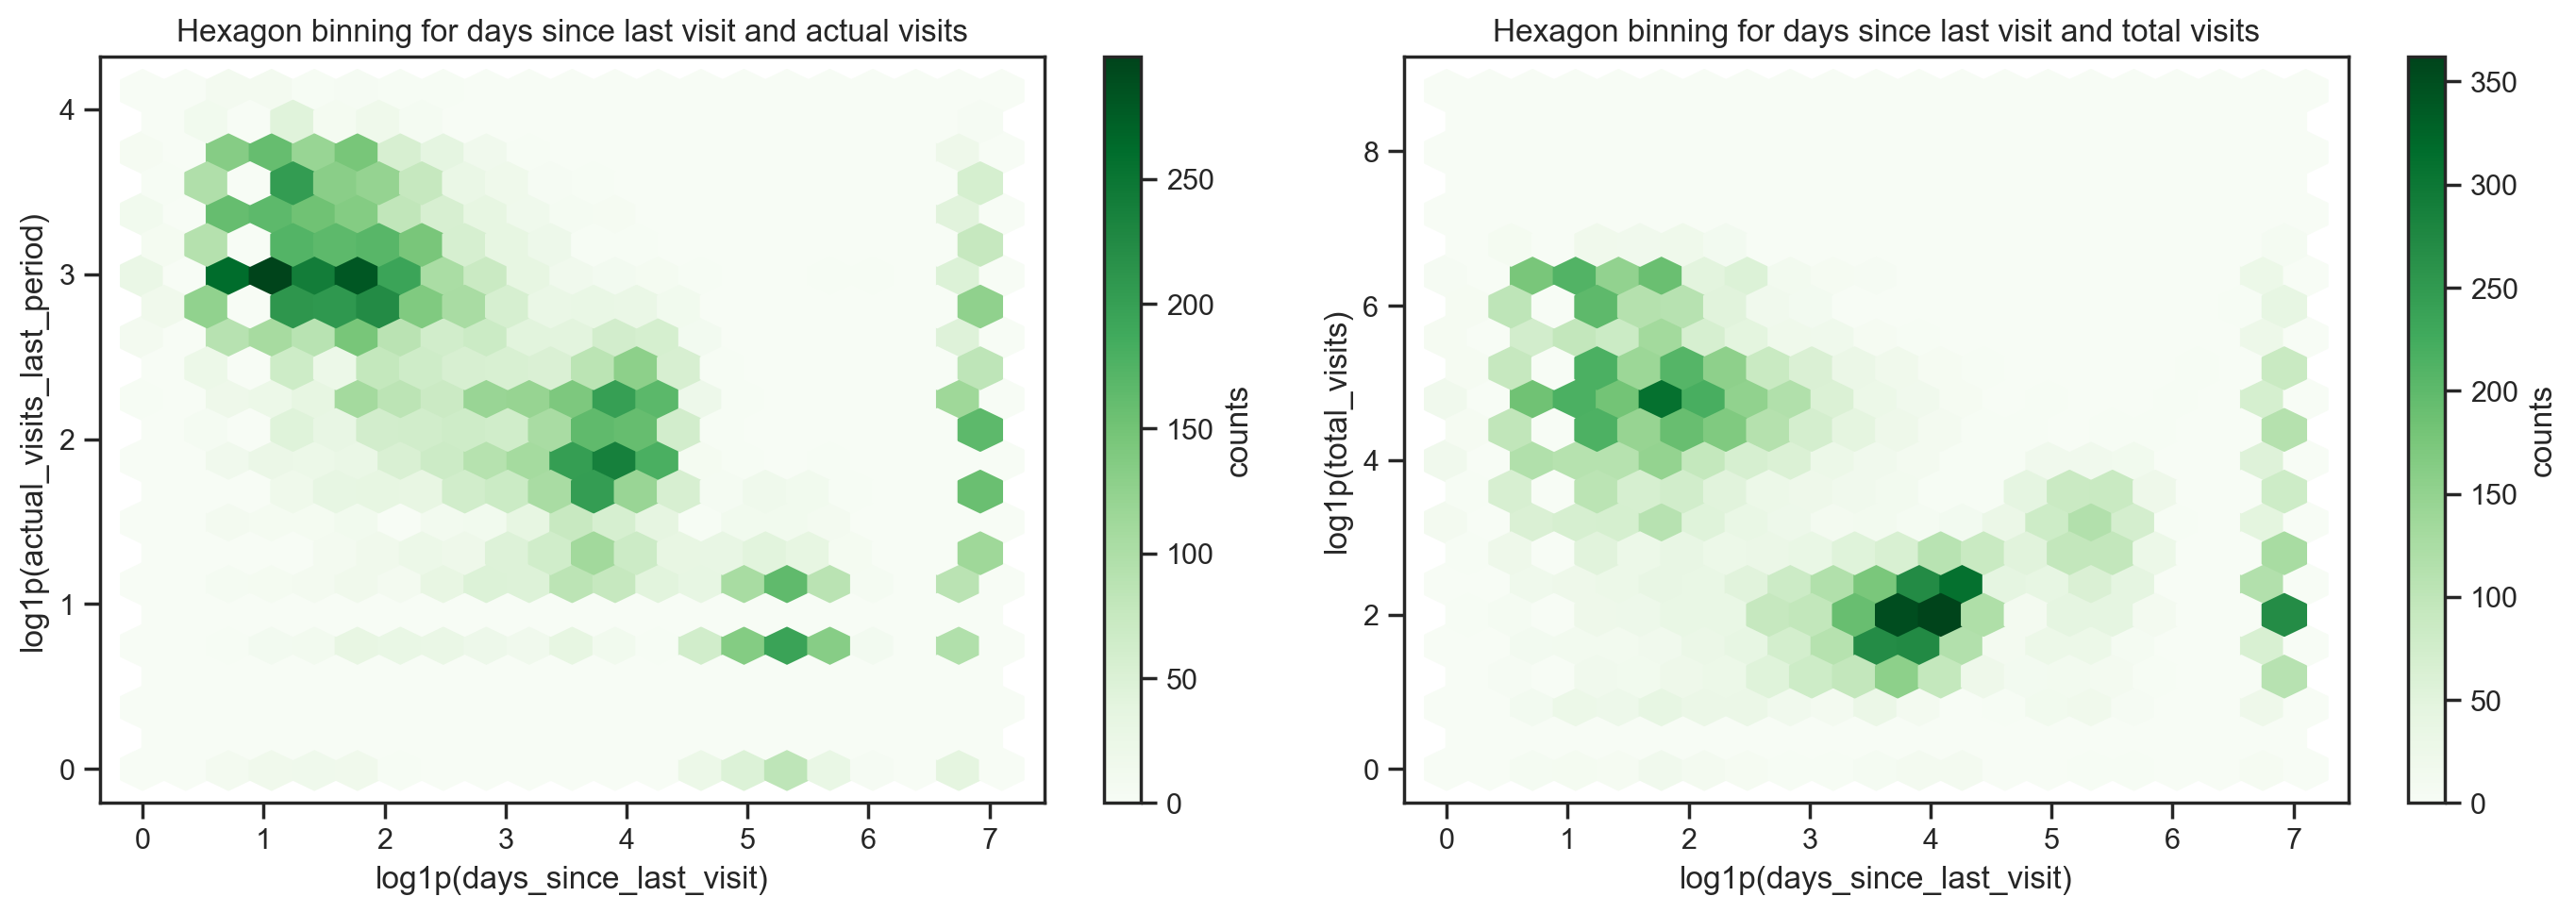

In [60]:
sns.set_style('ticks')

pairs = [
    ("days_since_last_visit", "actual_visits_last_period", "Hexagon binning for days since last visit and actual visits"),
    ("days_since_last_visit", "total_visits", "Hexagon binning for days since last visit and total visits"),
]

sp_rows = 1
sp_cols = len(pairs)

fig, axes = plt.subplots(sp_rows,
                         sp_cols,
                         figsize=(14, 5))

for ax, (x, y, title) in zip(axes.flatten(), pairs):
    subset = df_nodups[[x, y]].dropna()
    subset = subset[(subset[x] >= 0) & (subset[y] >= 0)]

    hb = ax.hexbin(np.log1p(subset[x]), np.log1p(subset[y]),
                   gridsize=20,
                   cmap='Greens'
                  )

    ax.set_title(title)
    cb = fig.colorbar(hb, ax=ax, label='counts')
    ax.set_xlabel(f"log1p({x})")
    ax.set_ylabel(f"log1p({y})")

plt.tight_layout()
plt.show()

**Days since last visit vs actual visits**
- The densest area is at the top left: customers who visited in the last few days (about 2 to 11 days) and made many visits in the last period (about 20 to 40). These are regular and recent customers.
- There is a second group with a gap of about 1 to 3 months and a moderate number of visits in the last period (about 5 to 10), and a third small group with a gap of 5 months or more and almost no visits.
- Overall, the longer the time since the last visit, the fewer visits in the last period.
- The column of the code 999 (right side) covers all levels of visits, including customers with many visits in the last period. This is impossible for a real gap of 999 days, which confirms again that 999 is a placeholder.

**Days since last visit vs total visits**
- Most customers are in one of two main areas: recent visitors (up to about 11 days) with a large number of total visits (about 50 to 600), who are probably long-standing and regular customers, and customers with a gap of 1 to 3 months and very few total visits (about 6 to 8), who may be short-term customers that left soon after joining.
- A smaller group has gaps of 5 months or more and a few tens of total visits.
- Again, the 999 customers appear at all levels of total visits.

So, in this analysis of temporal proximity and frequency, we saw several times that there seem to be two predominant types of customers: recent customers, with few total visits, and long-standing customers, with many visits and a regular use of the space. This is encouraging for the clustering, since it suggests that there are groups in the data. However, part of this separation is probably explained by how long each customer has been a member, which these variables do not measure directly. We will address this later, when we analyse the date variables in more detail and create the tenure of each customer (so we can probably create a new engineered variable).

<b><font size="4" color="#FAA85E">6.3.3. Monetary Relationships </font></b><br>  

<b><font size="4" color="#FAA85E">6.3.3.1. `lifetime_value` and `total_visits` </font></b><br>  
To improve visualization, since there are a lot of high values in both variables, we transformed both axes to a logarithmic scale.

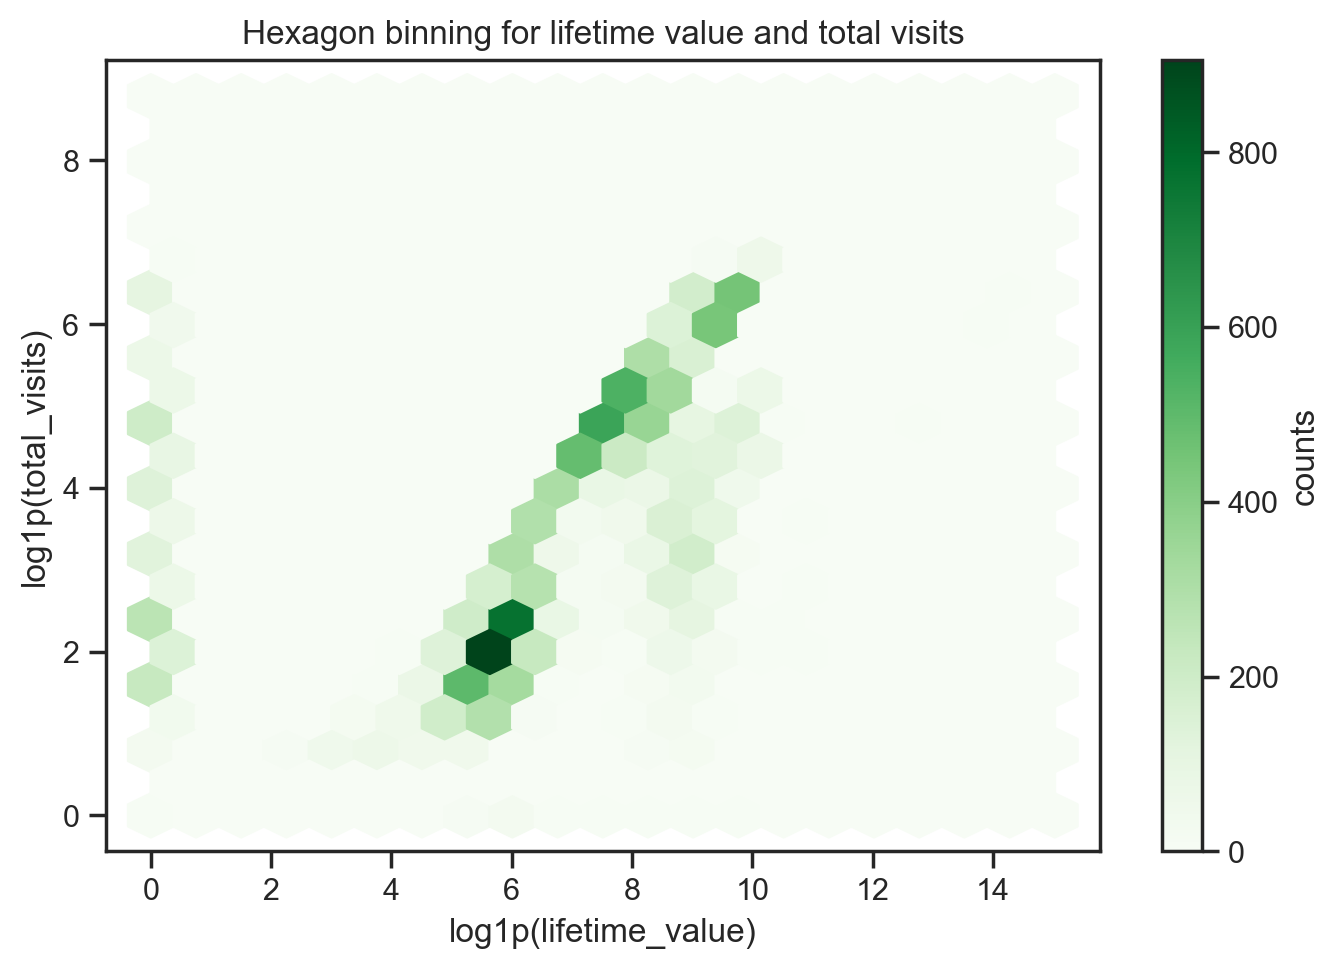

In [61]:
subset = df_nodups[["lifetime_value", "total_visits"]].dropna()
subset = subset[(subset["lifetime_value"] >= 0) & (subset["total_visits"] >= 0)]

fig, ax = plt.subplots(figsize=(7, 5))

hb = ax.hexbin(np.log1p(subset["lifetime_value"]), np.log1p(subset["total_visits"]),
               gridsize=20,
               cmap='Greens'
              )

ax.set_title("Hexagon binning for lifetime value and total visits")
fig.colorbar(hb, ax=ax, label='counts')
ax.set_xlabel("log1p(lifetime_value)")
ax.set_ylabel("log1p(total_visits)")

plt.tight_layout()
plt.show()

The plot shows a clear positive relation: customers with more total visits tend to generate more value, in an approximately proportional way, which is expected since both grow with the time as a member. There is also a second, weaker band of customers who generate much more value for the same number of visits, possibly because of more expensive plans, which we need to confirm. A vertical column at zero shows customers with no recorded value but a wide range of total visits, so zero value does not mean that they do not use the space: it is probably missing revenue or memberships without payment. The few points far to the right are the extreme values we have already identified.

<b><font size="3" color="#FAA85E">6.3.3.2. `entitled_visits_last_period` and `lifetime_value`, `actual_visits_last_period` and `lifetime_value`</font></b><br>  

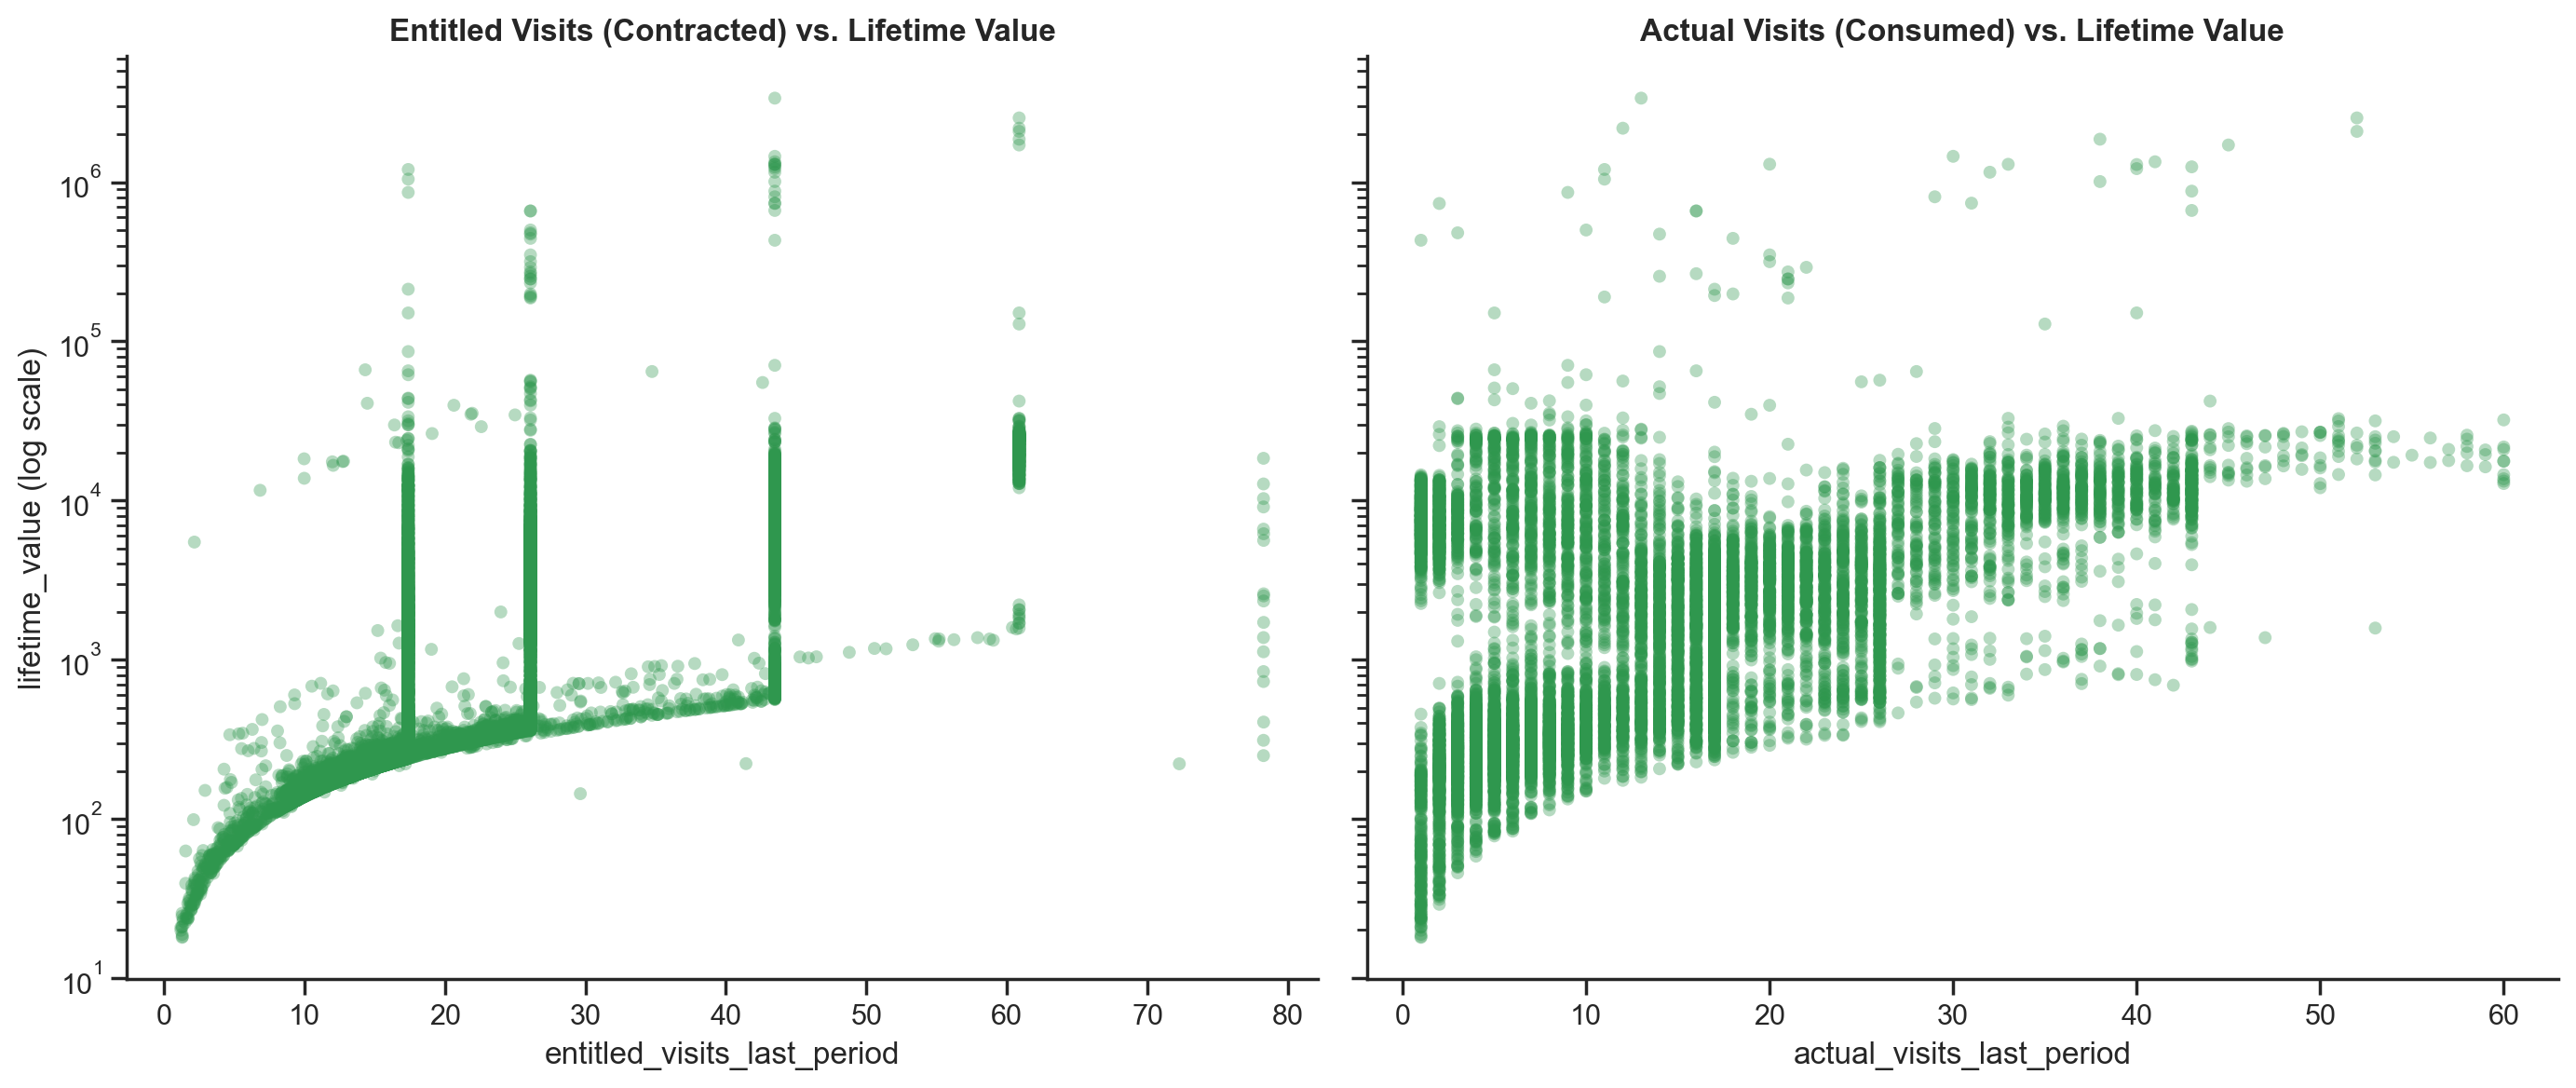

In [62]:
sns.set_style('ticks')

subset = df_nodups[
    (df_nodups["lifetime_value"] > 0) & 
    (df_nodups["entitled_visits_last_period"] > 0) & 
    (df_nodups["actual_visits_last_period"] > 0)
]

green = plt.cm.Greens(0.7)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Entitled Visits vs Lifetime Value 
ax1.scatter(
    subset["entitled_visits_last_period"], 
    subset["lifetime_value"],
    color=green,
    alpha=0.35,
    edgecolors="none",
    s=25
)
ax1.set_yscale('log')
ax1.set_title("Entitled Visits (Contracted) vs. Lifetime Value", fontweight="bold")
ax1.set_xlabel("entitled_visits_last_period")
ax1.set_ylabel("lifetime_value (log scale)")

# Actual Visits vs Lifetime Value 
ax2.scatter(
    subset["actual_visits_last_period"], 
    subset["lifetime_value"],
    color=green,
    alpha=0.35,
    edgecolors="none",
    s=25
)
ax2.set_yscale('log')
ax2.set_title("Actual Visits (Consumed) vs. Lifetime Value", fontweight="bold")
ax2.set_xlabel("actual_visits_last_period")

sns.despine()
plt.tight_layout()
plt.show()

The left plot shows two different patterns. For customers with fewer entitled visits than the maximum of their plan, the lifetime value increases smoothly and almost without dispersion with the entitled visits, which is probably the case of recent customers with only one (partial) period. For customers with the full entitlement (the vertical lines), the lifetime value varies a lot, from hundreds to millions, which probably reflects how long they stayed and how many times they renewed.

The right plot shows two bands. In the lower band the lifetime value increases with the actual visits, while in the upper band it is high and almost constant, regardless of how many visits the customer made. This shows that the value of a customer depends much more on the plan and on the time as a member than on the use of the space in the last period, which is consistent with the low correlation we saw before. The few points above 10⁵ are the extreme values we have already identified.

In short, the value generated by a customer is determined mainly by the plan and by the time as a member, and very little by how much they use the space. For the company, this means that low-use customers can still be very valuable (and very profitable) in the short term, but they may be at risk in the long term, which we explore later.

<b><font size="4" color="#FAA85E"> 6.3.4. Facility Utilization</font></b><br>  

<b><font size="3" color="#FAA85E"> 6.3.4.1. `total_visits` and `meeting_room_hours`, `total_visits` and `event_space_hours`</font></b><br>  

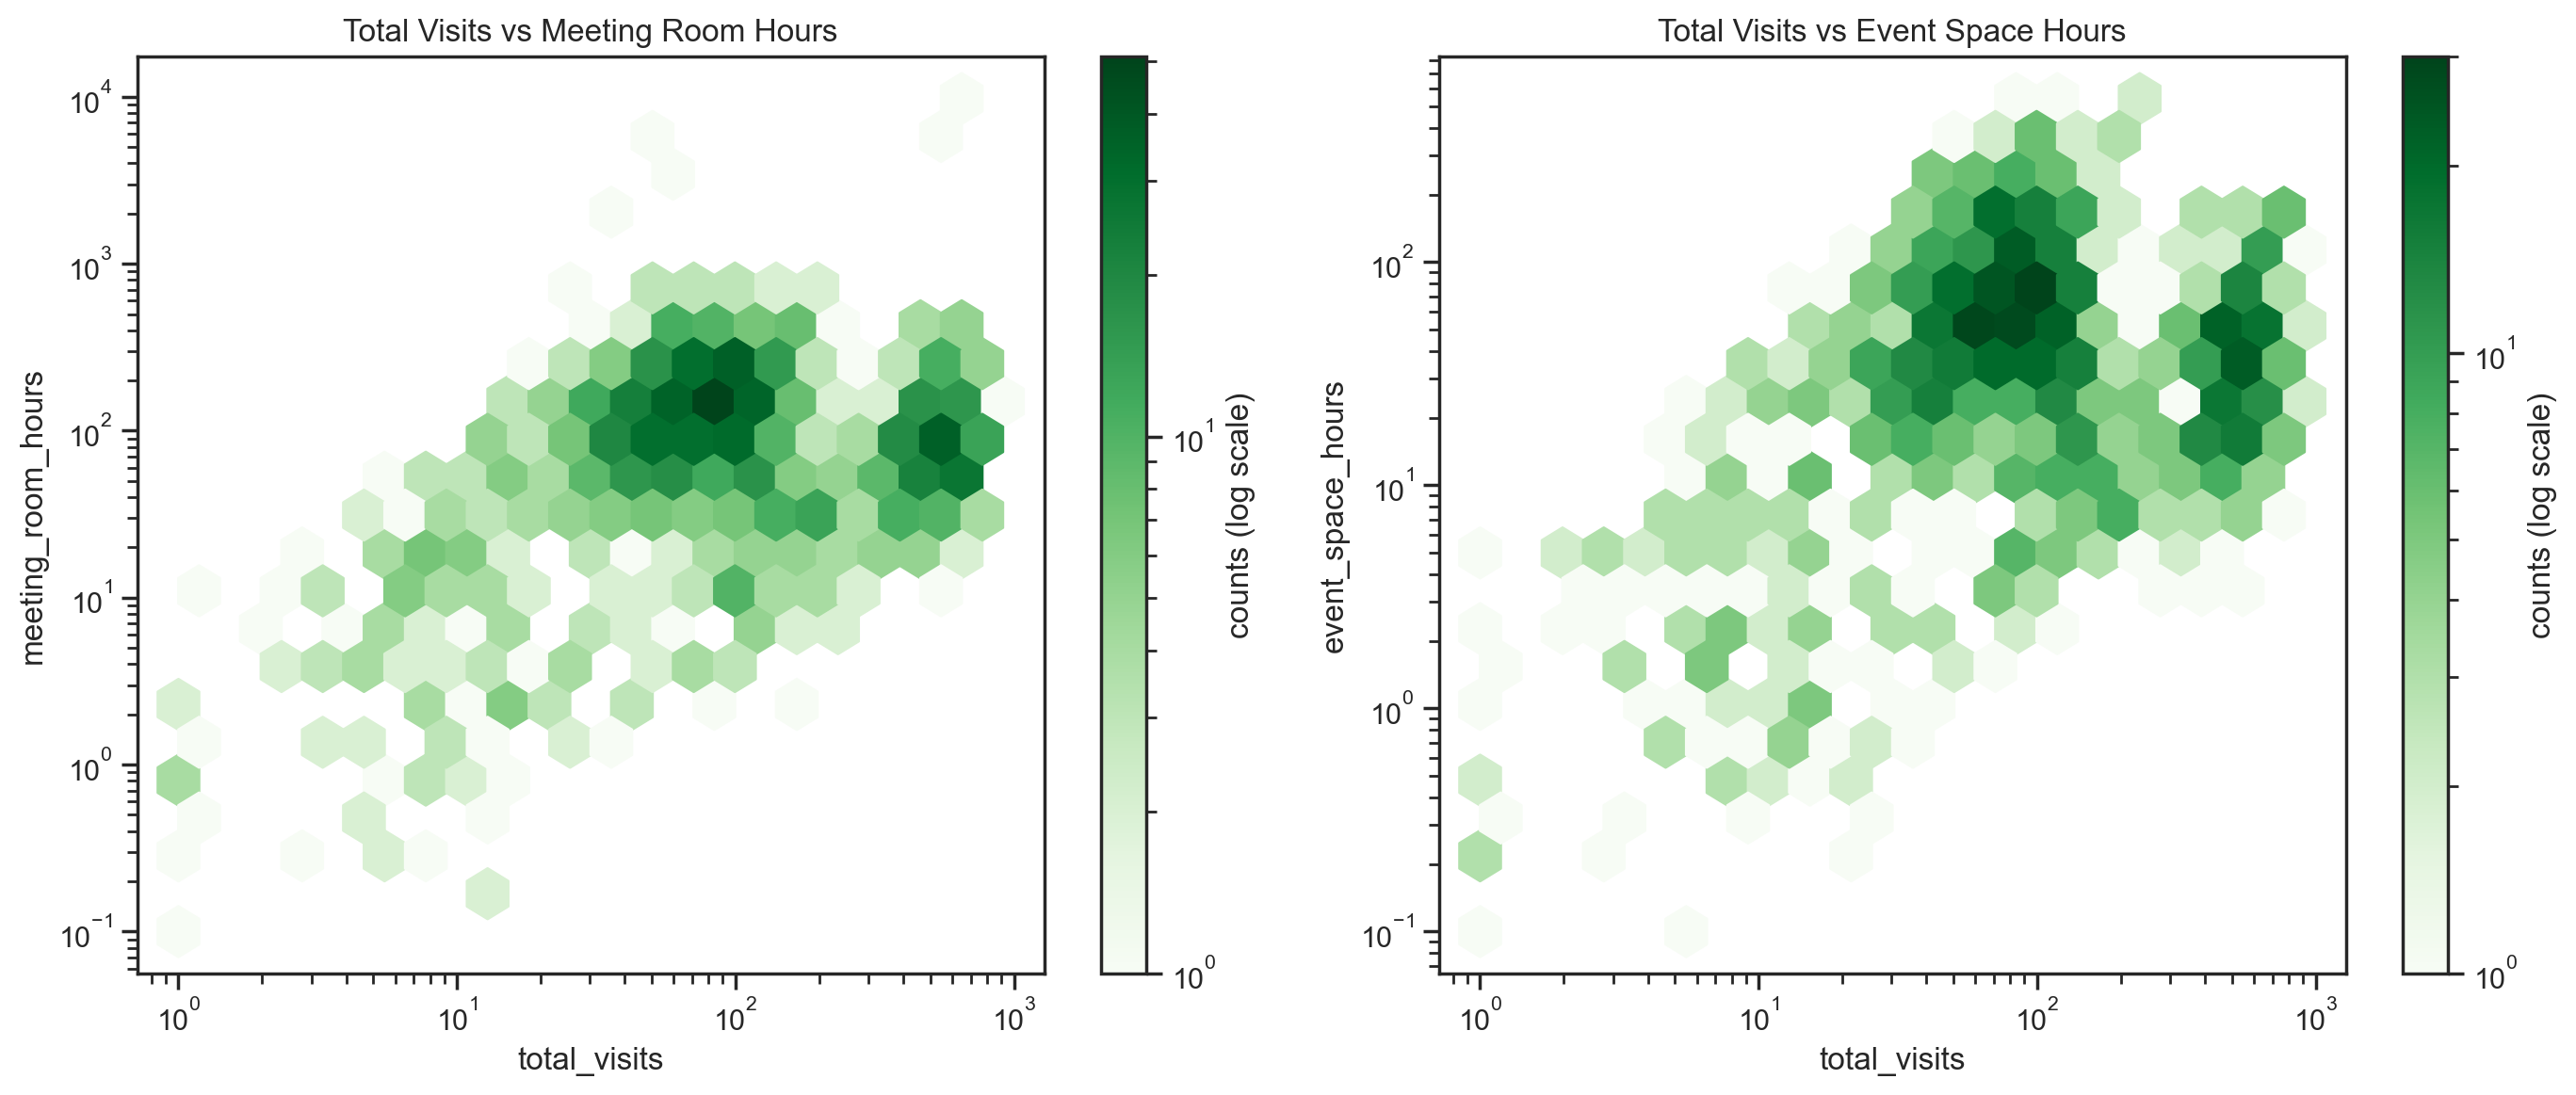

In [63]:
sns.set_style('ticks')

subset = df_nodups[(df_nodups["total_visits"] > 0) & 
            (df_nodups["meeting_room_hours"] > 0) & 
            (df_nodups["event_space_hours"] > 0)]

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 6), sharex=True)

# Total Visits vs Meeting Room Hours
hb1 = ax1.hexbin(subset["total_visits"], subset["meeting_room_hours"], 
                 gridsize=20,
                 cmap='Greens',
                 xscale='log',
                 yscale='log',
                 bins='log',
                 mincnt=1
                )
ax1.set_title("Total Visits vs Meeting Room Hours")
ax1.set_xlabel("total_visits")
ax1.set_ylabel("meeting_room_hours")
cb1 = fig.colorbar(hb1, ax=ax1, label='counts (log scale)')

# Total Visits vs Event Space Hours
hb2 = ax2.hexbin(subset["total_visits"], subset["event_space_hours"], 
                 gridsize=20,
                 cmap='Greens',
                 xscale='log',
                 yscale='log',
                 bins='log',
                 mincnt=1
                )
ax2.set_title("Total Visits vs Event Space Hours")
ax2.set_xlabel("total_visits")
ax2.set_ylabel("event_space_hours")
cb2 = fig.colorbar(hb2, ax=ax2, label='counts (log scale)')

plt.tight_layout()
plt.show()

Customers who visit the space more tend to use more meeting room and event space hours, and customers with fewer than about 10 visits rarely use these services. However, the hours vary a lot for the same number of visits, so the use of these services depends on the needs of each customer and not only on how often they go to the space. In both plots there are two dense areas, around 30 to 200 and around 300 to 800 total visits, with similar numbers of hours, so customers with many more visits do not use proportionally more hours. Note that the plots only include customers who use the services, since zeros cannot be shown on a logarithmic scale.

So, the use of these services is a different dimension of customer behaviour, only partly explained by how often customers visit. For the clustering, it can separate customers that the visit variables cannot, and for the company, it suggests that the demand comes from a specific group of customers and not simply from the most frequent ones.

<b><font size="4" color="#FAA85E"> 6.3.5. `age`</font></b><br>    

<b><font size="3" color="#FAA85E"> 6.3.5.1. `age` and `lifetime_value`, `age` and `plan_days_per_week`</font></b><br>     

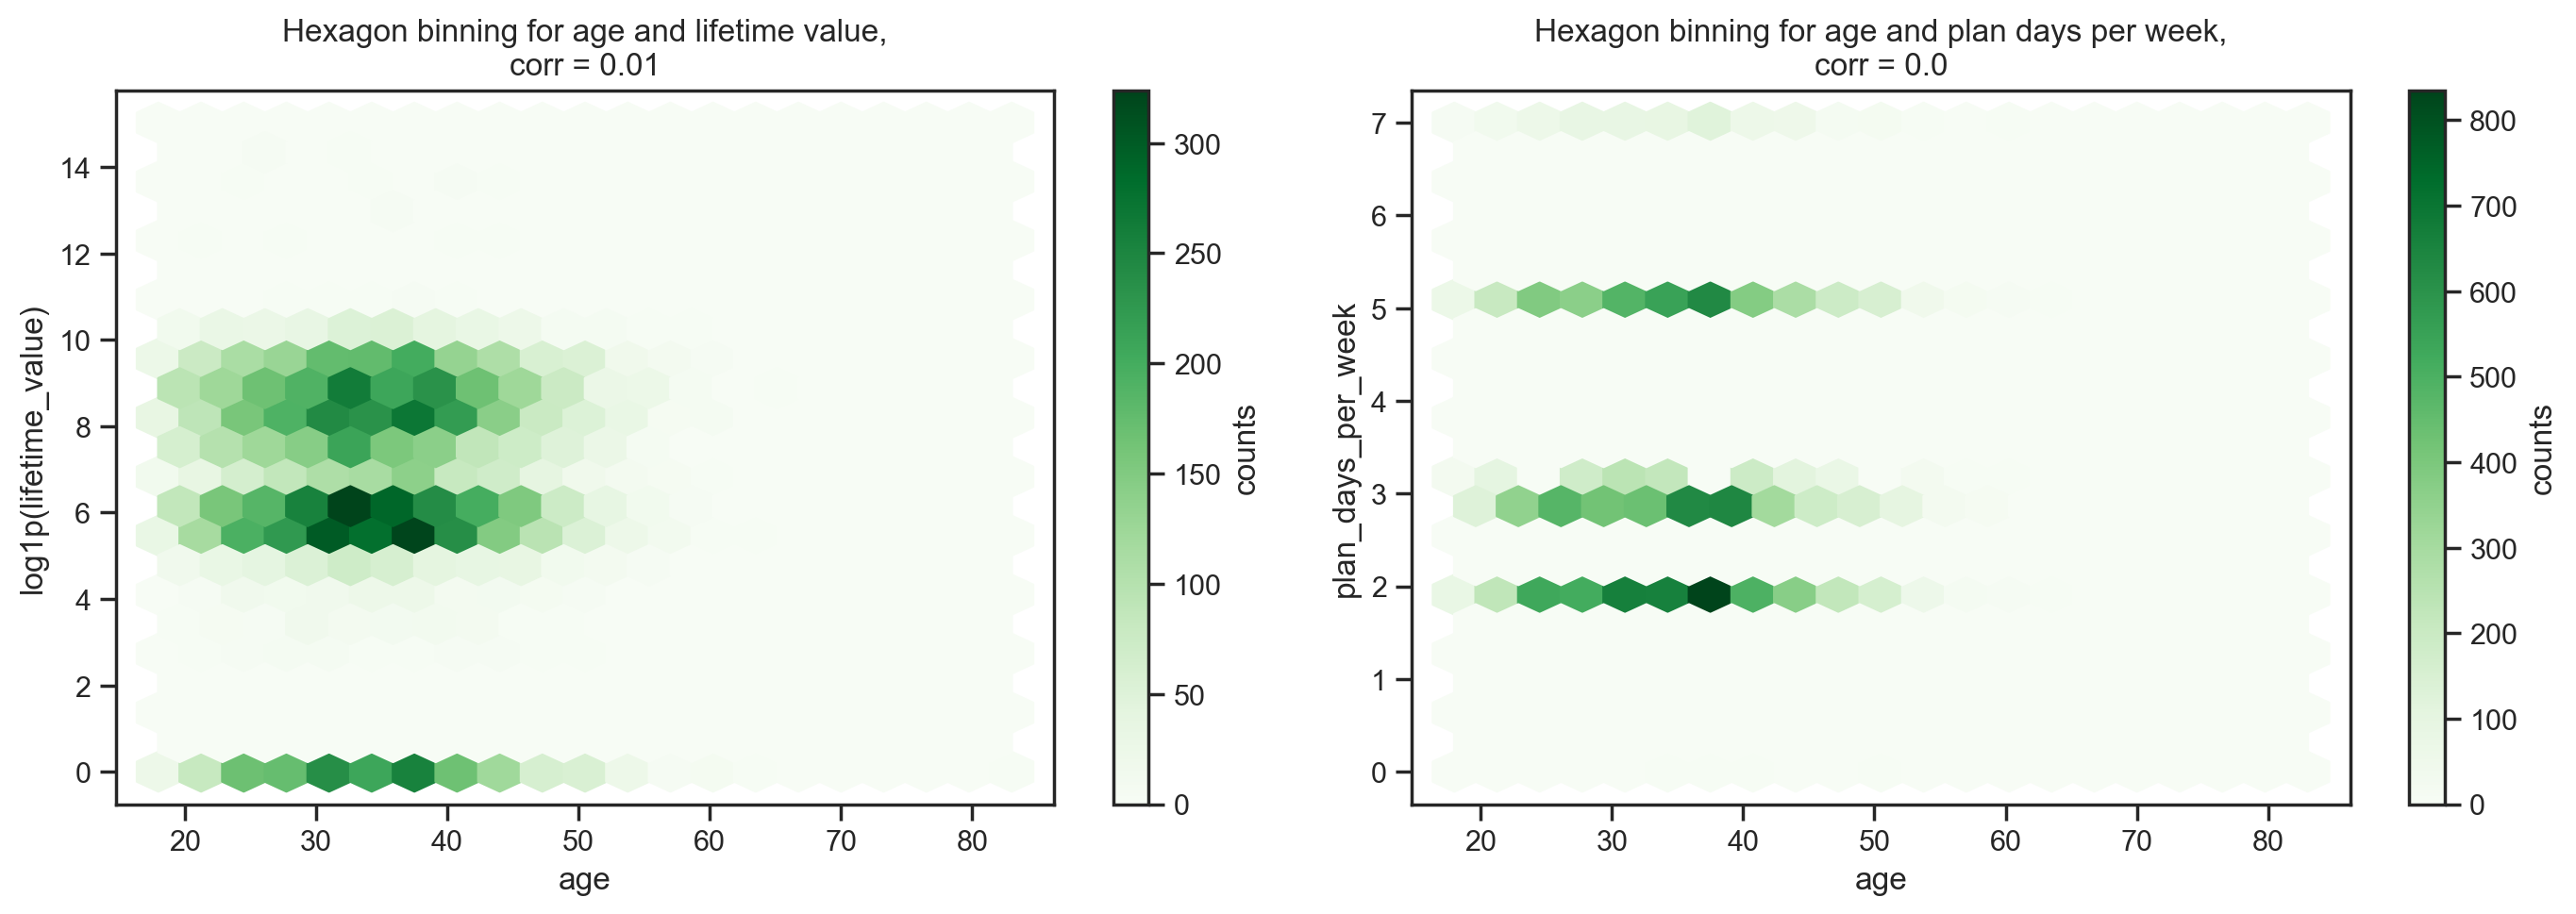

In [64]:
sns.set_style('ticks')

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

df_age = df_nodups[(df_nodups["age"] > 17) & (df_nodups["age"] < 89)]

# age vs lifetime_value
subset1 = df_age[["age", "lifetime_value"]].dropna()
subset1 = subset1[(subset1["age"] >= 0) & (subset1["lifetime_value"] >= 0)]
ax = axes[0]
hb = ax.hexbin(subset1["age"], np.log1p(subset1["lifetime_value"]), 
                gridsize=20,
               cmap='Greens'
              )
ax.set_title(f"Hexagon binning for age and lifetime value,\ncorr = {subset1.corr(method='spearman').values[0,1].round(2)}")
cb = fig.colorbar(hb, ax=ax, label='counts')
ax.set_xlabel("age")
ax.set_ylabel("log1p(lifetime_value)")

# age vs plan_days_per_week
subset2 = df_age[df_age["plan_days_per_week"] <= 7][["age", "plan_days_per_week"]].dropna()
subset2 = subset2[(subset2["age"] >= 0) & (subset2["plan_days_per_week"] >= 0)]
ax = axes[1]
hb = ax.hexbin(subset2["age"], subset2["plan_days_per_week"], 
                gridsize=20,
               cmap='Greens'
              )
ax.set_title(f"Hexagon binning for age and plan days per week,\ncorr = {subset2.corr(method='spearman').values[0,1].round(2)}")
cb = fig.colorbar(hb, ax=ax, label='counts')
ax.set_xlabel("age")
ax.set_ylabel("plan_days_per_week")

plt.tight_layout()
plt.show()

Age does not seem to be related to the value generated by the customers or to the plan they choose (correlations close to 0): customers of all ages are spread in the same way across the lifetime values and the plan days. This includes the customers with zero lifetime value, who do not belong to a specific age group. For the clustering, this suggests that age adds little information to distinguish customers, so it is a candidate to be left out.

<b><font size="5" color="#FAA85E"> 6.3.6. Multiple Bivariate Analysis</font></b><br>

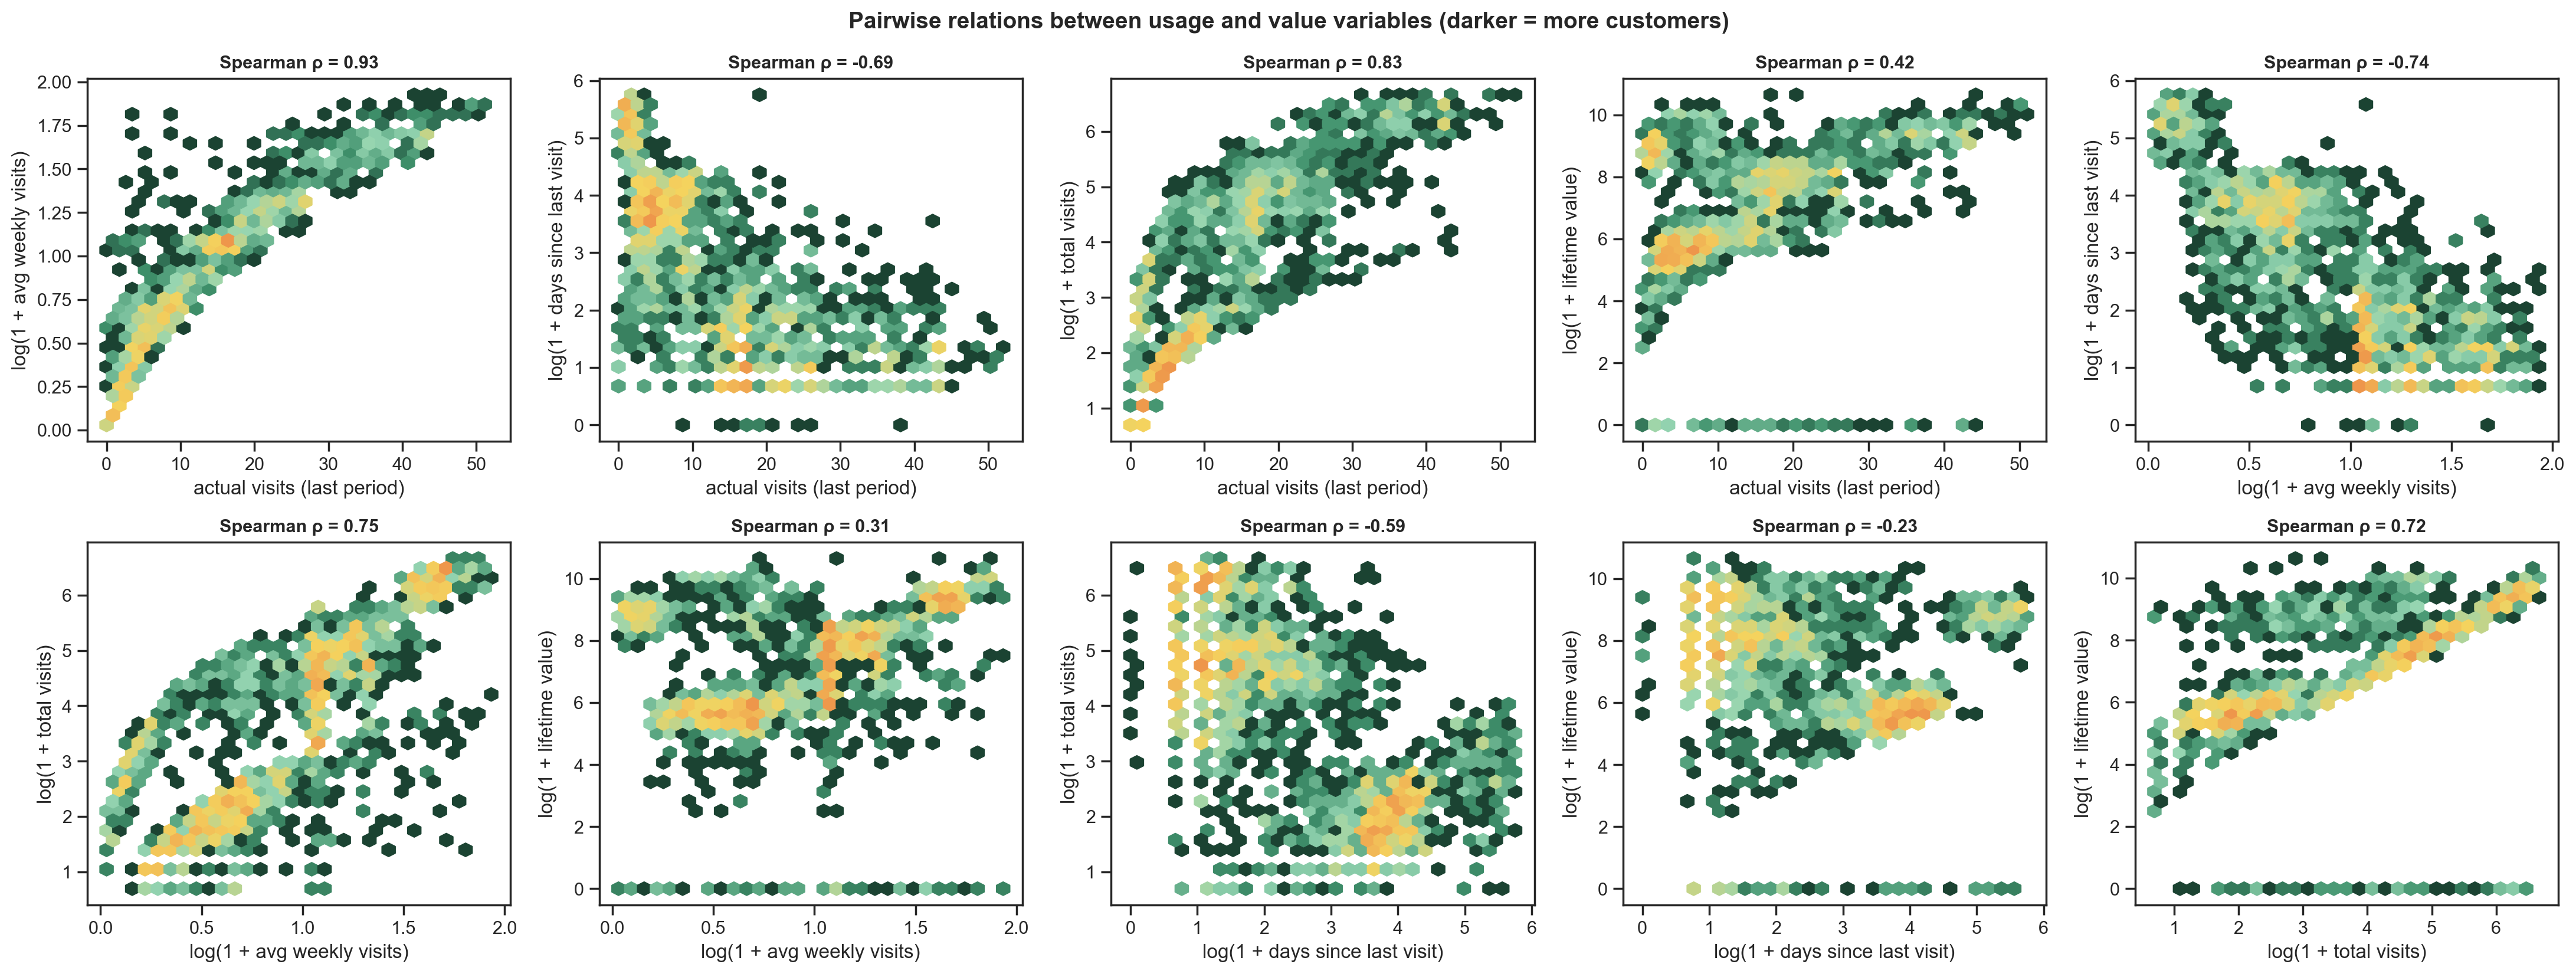

In [65]:
cmap_palette = LinearSegmentedColormap.from_list("custom", colors, N=256)
palette = [cmap_palette(i) for i in np.linspace(0, 1, 11)]

pair_cols = ["plan_days_per_week", "actual_visits_last_period", "avg_weekly_visits",
             "days_since_last_visit", "total_visits", "lifetime_value"]

df_clean_pair = df_nodups[pair_cols].dropna()                                  # sem NaN
df_clean_pair = df_clean_pair[(df_clean_pair >= 0).all(axis=1)]                # sem negativos (o log1p falha abaixo de -1)
df_clean_pair = df_clean_pair[df_clean_pair["days_since_last_visit"] != 999]   # sem o placeholder 999
df_clean_pair = df_clean_pair[df_clean_pair["plan_days_per_week"].isin([2, 3, 5, 7])]   # só planos válidos (0 e 9 são inválidos)

df_pair = pd.DataFrame({
    "plan_days_per_week": df_clean_pair["plan_days_per_week"],
    "actual_visits_last_period": df_clean_pair["actual_visits_last_period"],
    "log1p_avg_weekly_visits": np.log1p(df_clean_pair["avg_weekly_visits"]),
    "log1p_days_since_last_visit": np.log1p(df_clean_pair["days_since_last_visit"]),
    "log1p_total_visits": np.log1p(df_clean_pair["total_visits"]),
    "log1p_lifetime_value": np.log1p(df_clean_pair["lifetime_value"]),
}).sample(2000, random_state=42)

pretty = {
    "actual_visits_last_period": "actual visits (last period)",
    "log1p_avg_weekly_visits": "log(1 + avg weekly visits)",
    "log1p_days_since_last_visit": "log(1 + days since last visit)",
    "log1p_total_visits": "log(1 + total visits)",
    "log1p_lifetime_value": "log(1 + lifetime value)",
}

metric_cols = [c for c in df_pair.columns if c != "plan_days_per_week"]
pairs = list(combinations(metric_cols, 2))

n_cols = 5
n_rows = ceil(len(pairs) / n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(22, 4.2 * n_rows))
axes = axes.flatten()

for ax, (x, y) in zip(axes, pairs):
    d = df_pair[[x, y]].dropna()
    rho = d[x].corr(d[y], method="spearman")          # calculada com todos os pontos da amostra

    xlo, xhi = d[x].quantile([0.005, 0.995])           # corte só dos extremos para o gráfico
    ylo, yhi = d[y].quantile([0.005, 0.995])
    d = d[d[x].between(xlo, xhi) & d[y].between(ylo, yhi)]

    ax.hexbin(d[x], d[y], gridsize=30, cmap=cmap_palette, bins="log", mincnt=1)
    ax.set_title(f"Spearman ρ = {rho:.2f}", fontweight="bold", fontsize=11)
    ax.set_xlabel(pretty[x])
    ax.set_ylabel(pretty[y])

for ax in axes[len(pairs):]:      # esconde eixos sobrantes, se os houver
    ax.axis("off")

fig.suptitle("Pairwise relations between usage and value variables (darker = more customers)",
             fontweight="bold", fontsize=14)
plt.tight_layout()
plt.show()

- The usage variables are strongly related to each other (Spearman between 0.75 and 0.93), so they carry similar information and only a few of them are needed for the clustering.
- Customers with longer gaps since the last visit tend to have lower usage (correlations between -0.59 and -0.74).
- Lifetime value is more related to the accumulated visits (0.72) than to the recent use (0.31 to 0.42) or to recency (-0.23), which is consistent with the idea that value depends more on the time as a member than on current use.
- In all the plots with lifetime value there are two bands of value (around 6 and 9 on the log scale) and a row of customers with zero value spread over all levels of usage, so the value does not seem to be explained by usage alone.

<b><font size="6" color="#EE964B">7. Membership Duration, Renewals and Evolution Over Time</font></b><br>

This chapter looks at how long clients stay and how memberships evolve over time, using the two date variables `membership_start` and `membership_end`. We first analyse the duration of memberships (the number of days between `membership_start` and `membership_end`) and how it relates to the plan tier and to the number of renewals. We then look at the number of new memberships and exits per month.

Customers analysed: 11093 of 15465
count    11093.0
mean       329.0
std        289.0
min          1.0
25%         69.0
50%        252.0
75%        536.0
max       1095.0
Name: tenure_days, dtype: float64


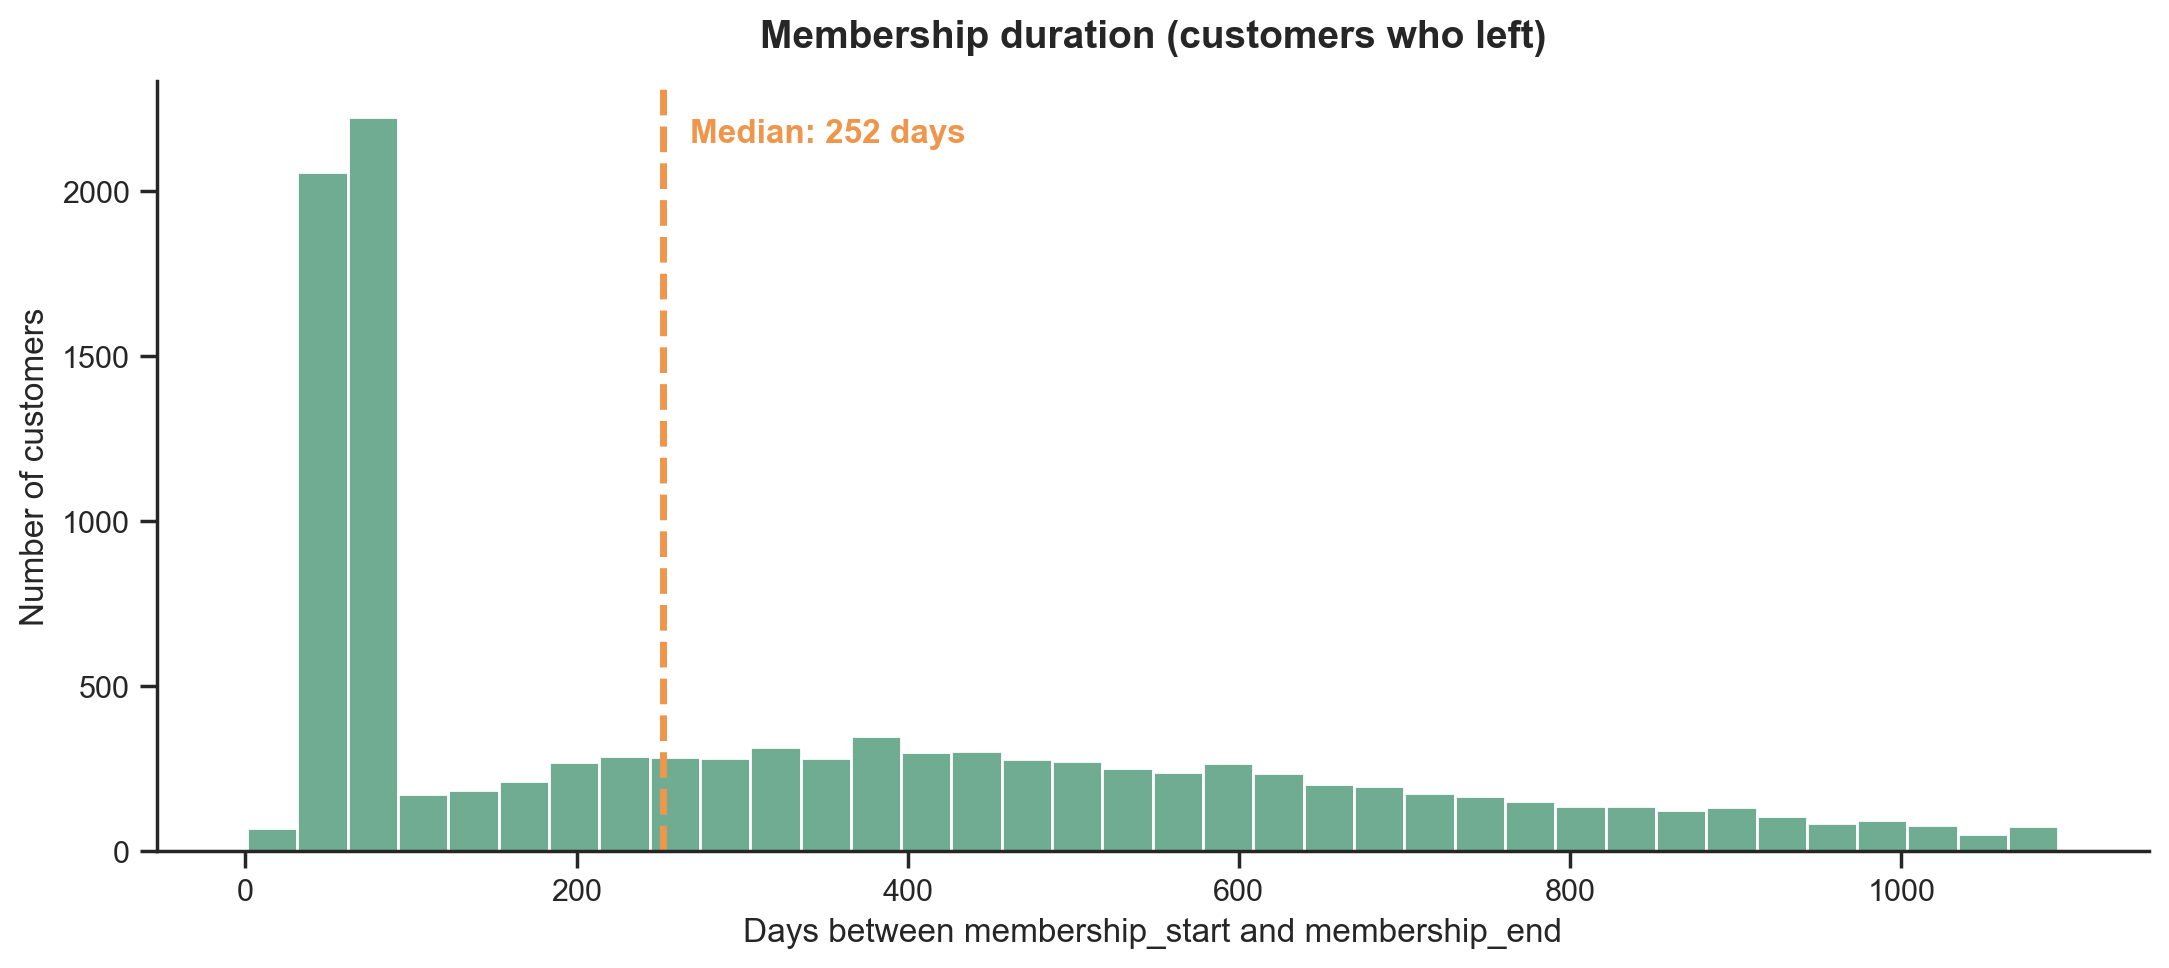

In [66]:
placeholder = pd.Timestamp("1970-01-01")

# só clientes que saíram (sem placeholder) e com datas coerentes
df_tenure = df_nodups.loc[
    (df_nodups["membership_end"] != placeholder) &
    (df_nodups["membership_end"] >= df_nodups["membership_start"])
].copy()

print(f"Customers analysed: {len(df_tenure)} of {len(df)}")
print(df_tenure["tenure_days"].describe().round(0))

fig, ax = plt.subplots(figsize=(11, 5))
sns.histplot(df_tenure["tenure_days"], bins=36, color=main_color, edgecolor="white", ax=ax)

median = df_tenure["tenure_days"].median()
ax.axvline(median, color="#EE964B", linewidth=2.5, linestyle="--")
ax.annotate(f"Median: {median:.0f} days", xy=(median, ax.get_ylim()[1] * 0.92),
            xytext=(10, 0), textcoords="offset points", color="#EE964B", fontweight="bold")

ax.set_title("Membership duration (customers who left)", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Days between membership_start and membership_end")
ax.set_ylabel("Number of customers")
sns.despine()
plt.tight_layout()
plt.show()

Most memberships last between 100 and 1,000 days, with a long tail towards longer durations, and the median duration is **252 days**. There is a clear spike at about **50 to 90 days**, with far more clients than in any other range. This suggests a trial or minimum-term period after which many clients leave. The distribution is right-skewed, so the median is a better summary than the mean.

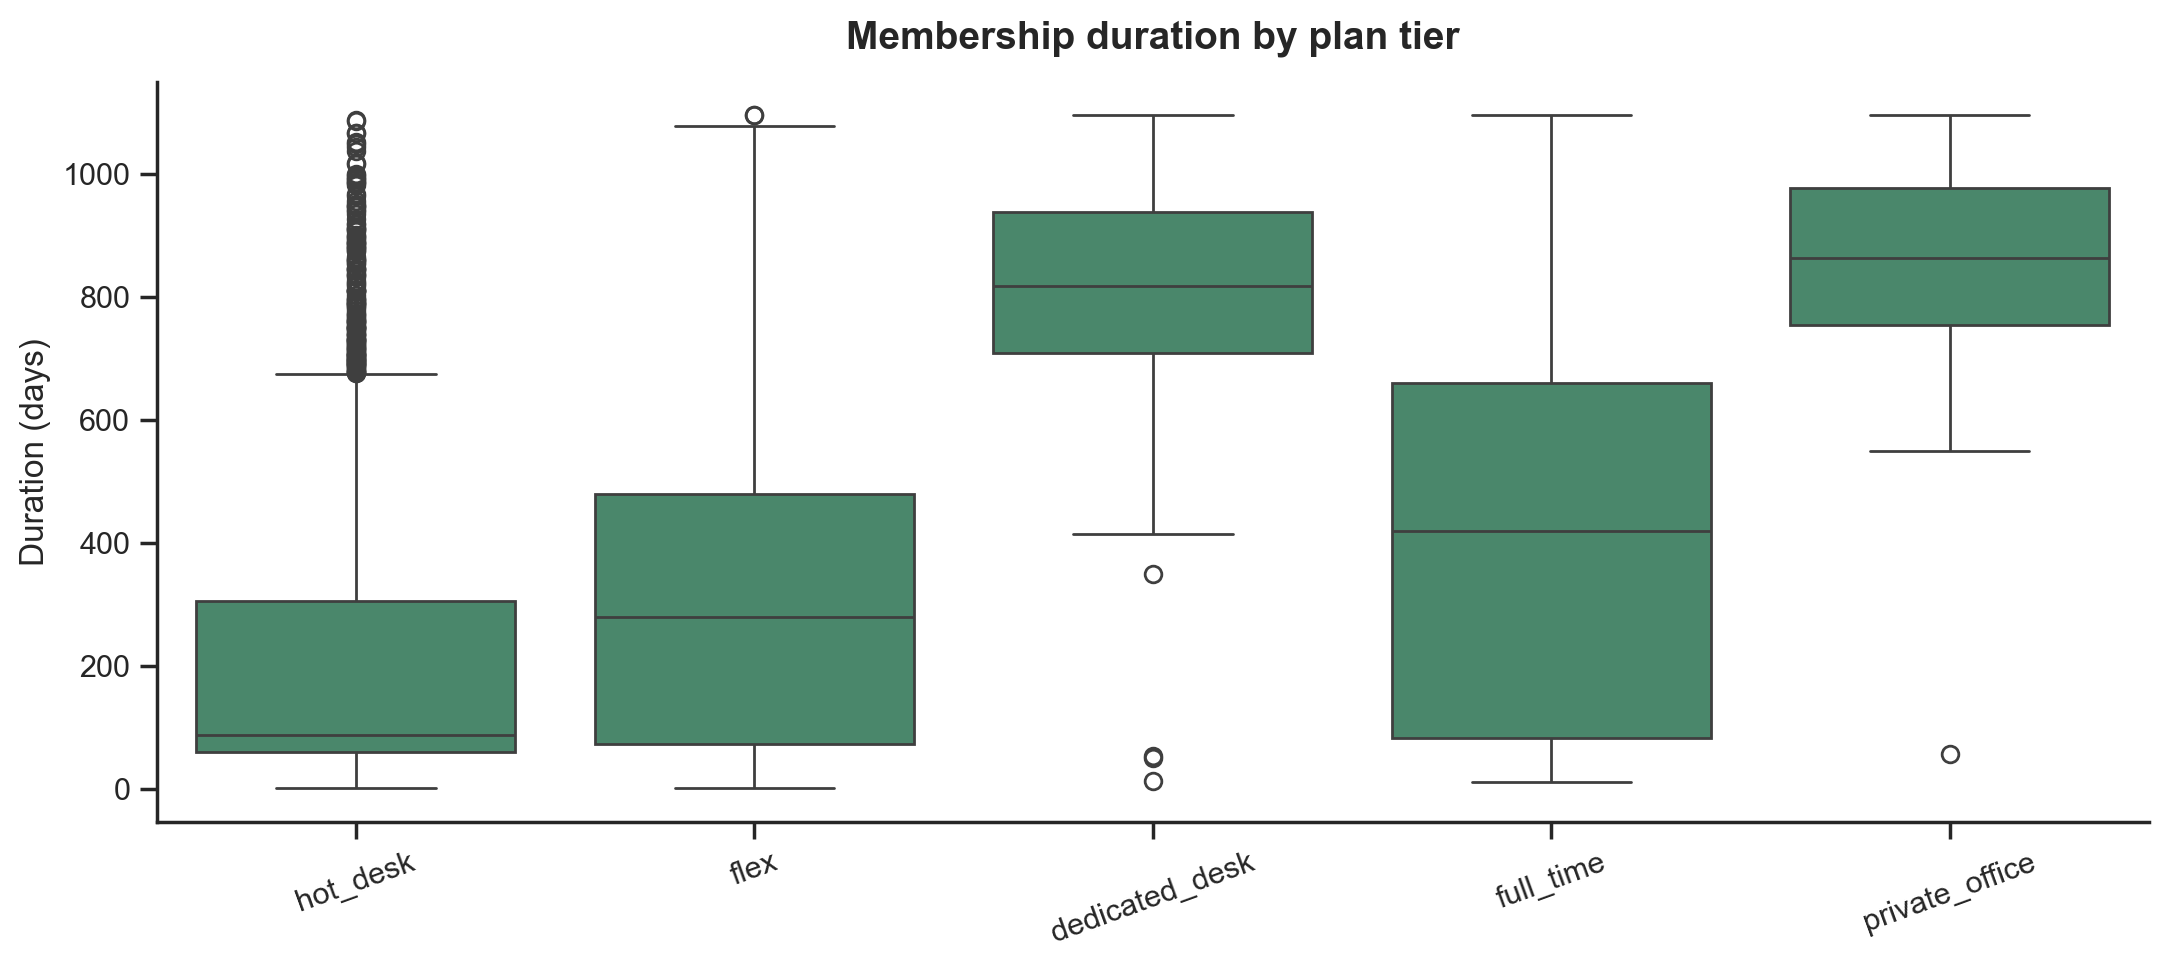

,count,mean,std,min,25%,50%,75%,max
plan_tier,,,,,,,,
hot_desk,4361.0,202.0,208.0,1.0,60.0,87.0,306.0,1087.0
flex,4207.0,303.0,235.0,2.0,72.0,279.0,480.0,1095.0
dedicated_desk,649.0,818.0,152.0,13.0,708.0,817.0,938.0,1095.0
full_time,1476.0,425.0,302.0,11.0,83.0,420.0,660.0,1095.0
private_office,347.0,856.0,151.0,57.0,754.0,863.0,976.0,1095.0


In [67]:
tier_order = ["hot_desk", "flex", "dedicated_desk", "full_time", "private_office"]

fig, ax = plt.subplots(figsize=(11, 5))
sns.boxplot(data=df_tenure, x="plan_tier", y="tenure_days", order=tier_order,
            color=main_color, ax=ax)

ax.set_title("Membership duration by plan tier", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("")
ax.set_ylabel("Duration (days)")
ax.tick_params(axis="x", rotation=20)
sns.despine()
plt.tight_layout()
plt.show()

df_tenure.groupby("plan_tier")["tenure_days"].describe().loc[tier_order].round(0)

`dedicated_desk` and `private_office` are the plans with the longest-lasting customers (median duration of about 817 and 863 days, respectively), while `full_time` is the most heterogeneous plan, with durations spread widely (IQR from 83 to 660 days), possibly reflecting a group of customers who leave quickly alongside a larger group who stay much longer.

`hot_desk` has the shortest durations, with a strongly right-skewed distribution: half of the customers who left did so within 87 days, far below the median of `flex` (279 days), despite both plans having a similar number of customers who left (4,361 vs. 4,207).

These durations only cover customers who already left, and cheaper plans have more recent starts, so absolute values are likely underestimated for them.

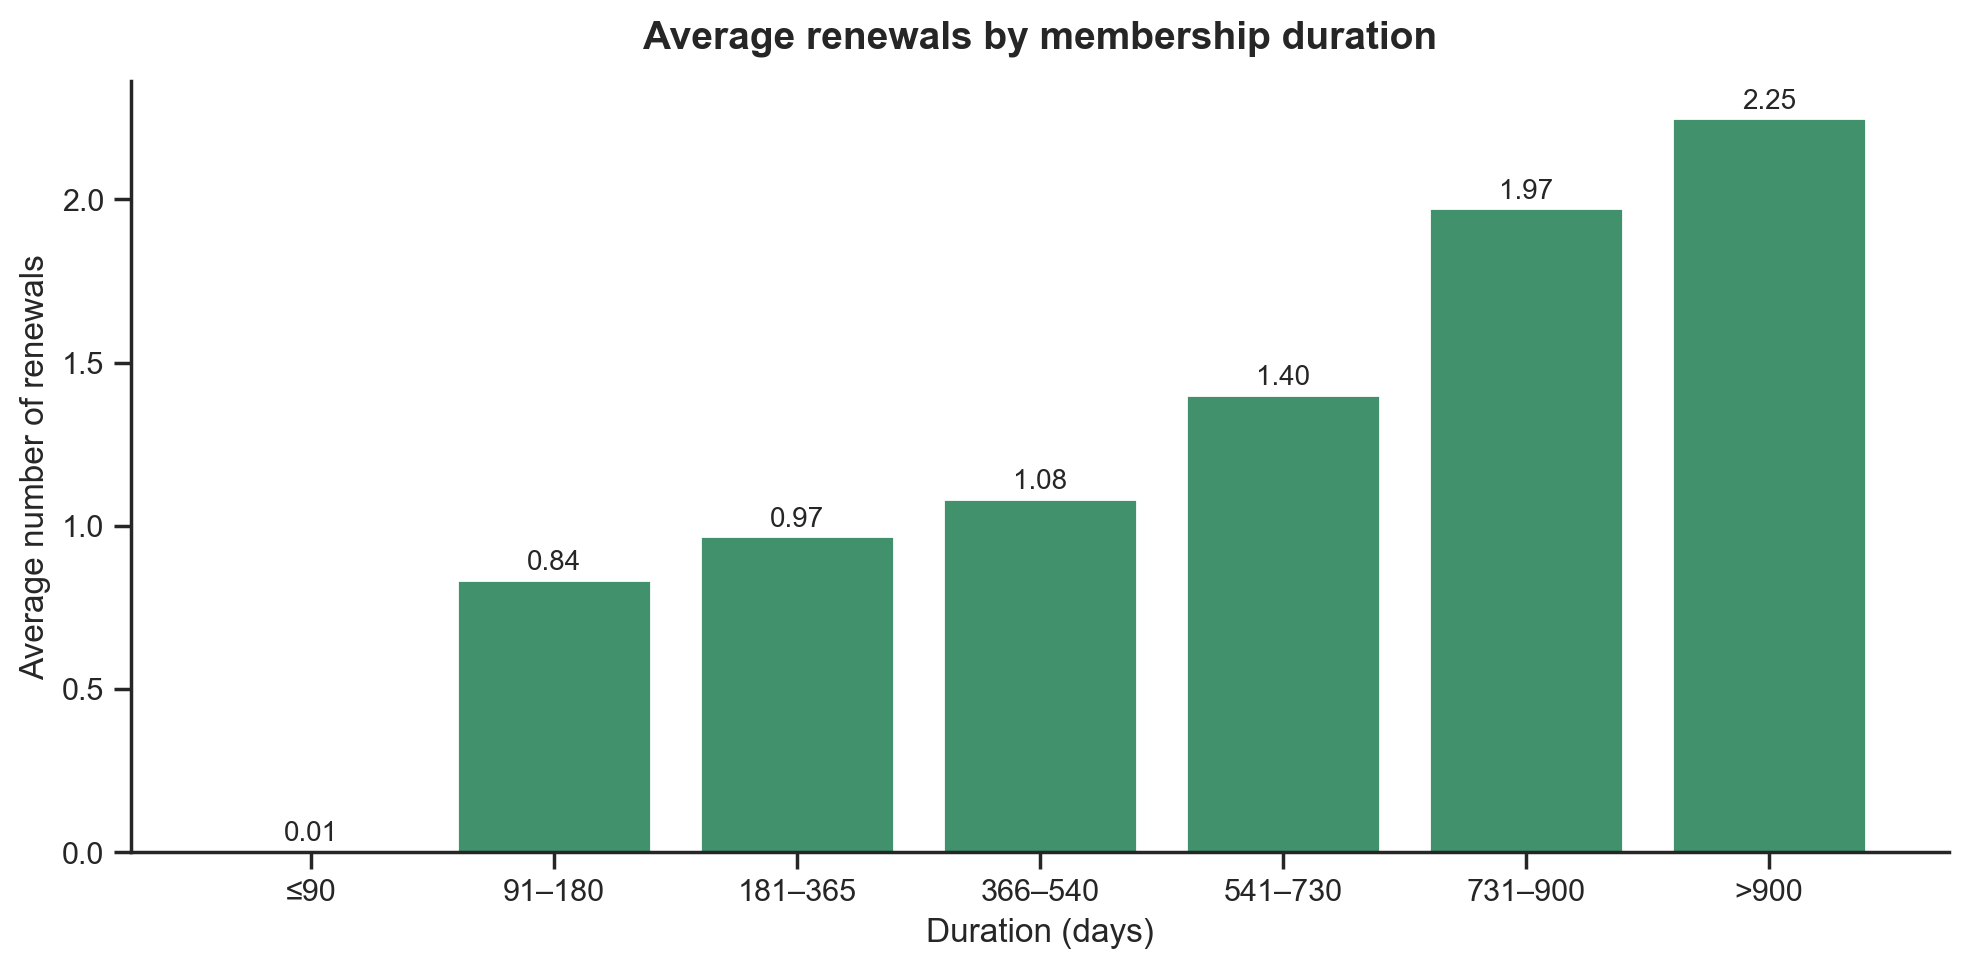

In [68]:
# df_tenure vem da célula anterior (clientes que saíram, datas coerentes)
df_ren = df_tenure[df_tenure["n_renewals"] >= 0].copy()

df_ren["tenure_bin"] = pd.cut(
    df_ren["tenure_days"],
    bins=[0, 90, 180, 365, 540, 730, 900, 1100],
    labels=["≤90", "91–180", "181–365", "366–540", "541–730", "731–900", ">900"]
)

# 1) média de renovações por faixa de duração
mean_by_bin = df_ren.groupby("tenure_bin", observed=True)["n_renewals"].mean()

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(mean_by_bin.index.astype(str), mean_by_bin.values, color=main_color)
for i, v in enumerate(mean_by_bin.values):
    ax.text(i, v + 0.03, f"{v:.2f}", ha="center", fontsize=10)
ax.set_title("Average renewals by membership duration", fontsize=14, fontweight="bold", pad=12)
ax.set_xlabel("Duration (days)")
ax.set_ylabel("Average number of renewals")
sns.despine()
plt.tight_layout()
plt.show()


The average number of renewals increases with membership duration, from about 0.01 for memberships of up to 90 days to **2.25** for those above 900 days. This is partly expected, since a client who stays longer has had more opportunities to renew. The increase is not linear: there is a clear jump after 540 days, and the value is close to zero in the first bin, which matches the clients who leave after the initial period seen in Figure 1.

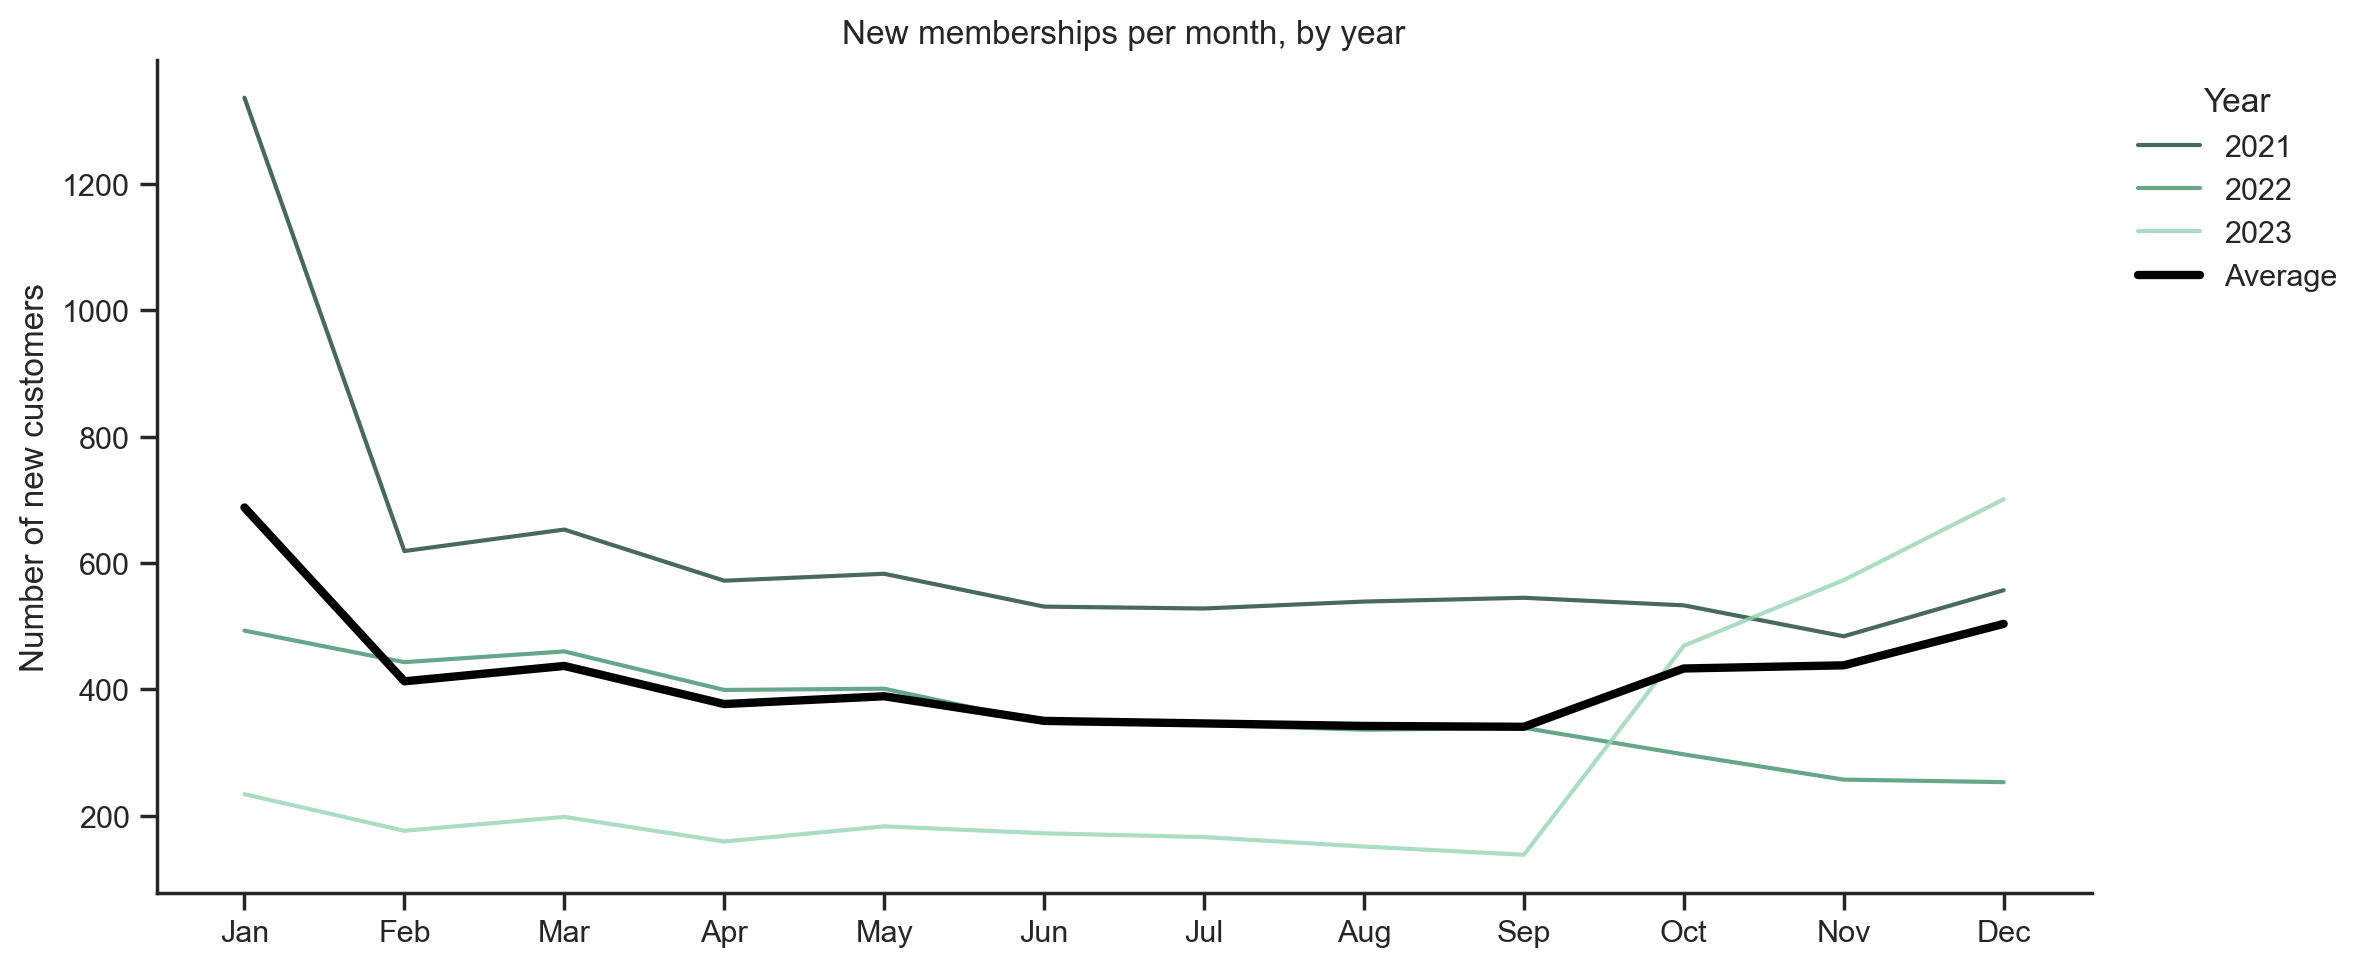

In [69]:
# nº de novos clientes por (ano, mês)
tmp = df_nodups.copy()
tmp["year"] = tmp["membership_start"].dt.year
tmp["month"] = tmp["membership_start"].dt.month

pivot = tmp.pivot_table(index="month", columns="year", values="membership_start", aggfunc="count")

fig, ax = plt.subplots(figsize=(12, 5))

# uma linha fininha por ano
for color, year in zip(colors, pivot.columns):
    ax.plot(pivot.index, pivot[year], color=color, alpha=0.8, label=str(year))

# média de todos os anos (a "tendência" sazonal)
ax.plot(pivot.index, pivot.mean(axis=1), color="black", linewidth=3, label="Average")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("New memberships per month, by year")
ax.set_xlabel("")
ax.set_ylabel("Number of new customers")
ax.legend(title="Year", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

The number of new memberships **decreases** from 2021 to 2023. In 2021 there are about 500 to 650 new clients per month, in 2022 the value falls from about 490 to about 255, and in 2023 it stays between about 140 and 235 until September. In October 2023 there is a sharp increase that reaches about 700 in December. The very high value in **January 2021** (about 1,300) is probably not real: `2021-01-01` was the most frequent start date in the dataset, so it is probably a default value for clients with an unknown start date. The rise at the end of 2023 should be checked, as it may be related to how the data was collected.

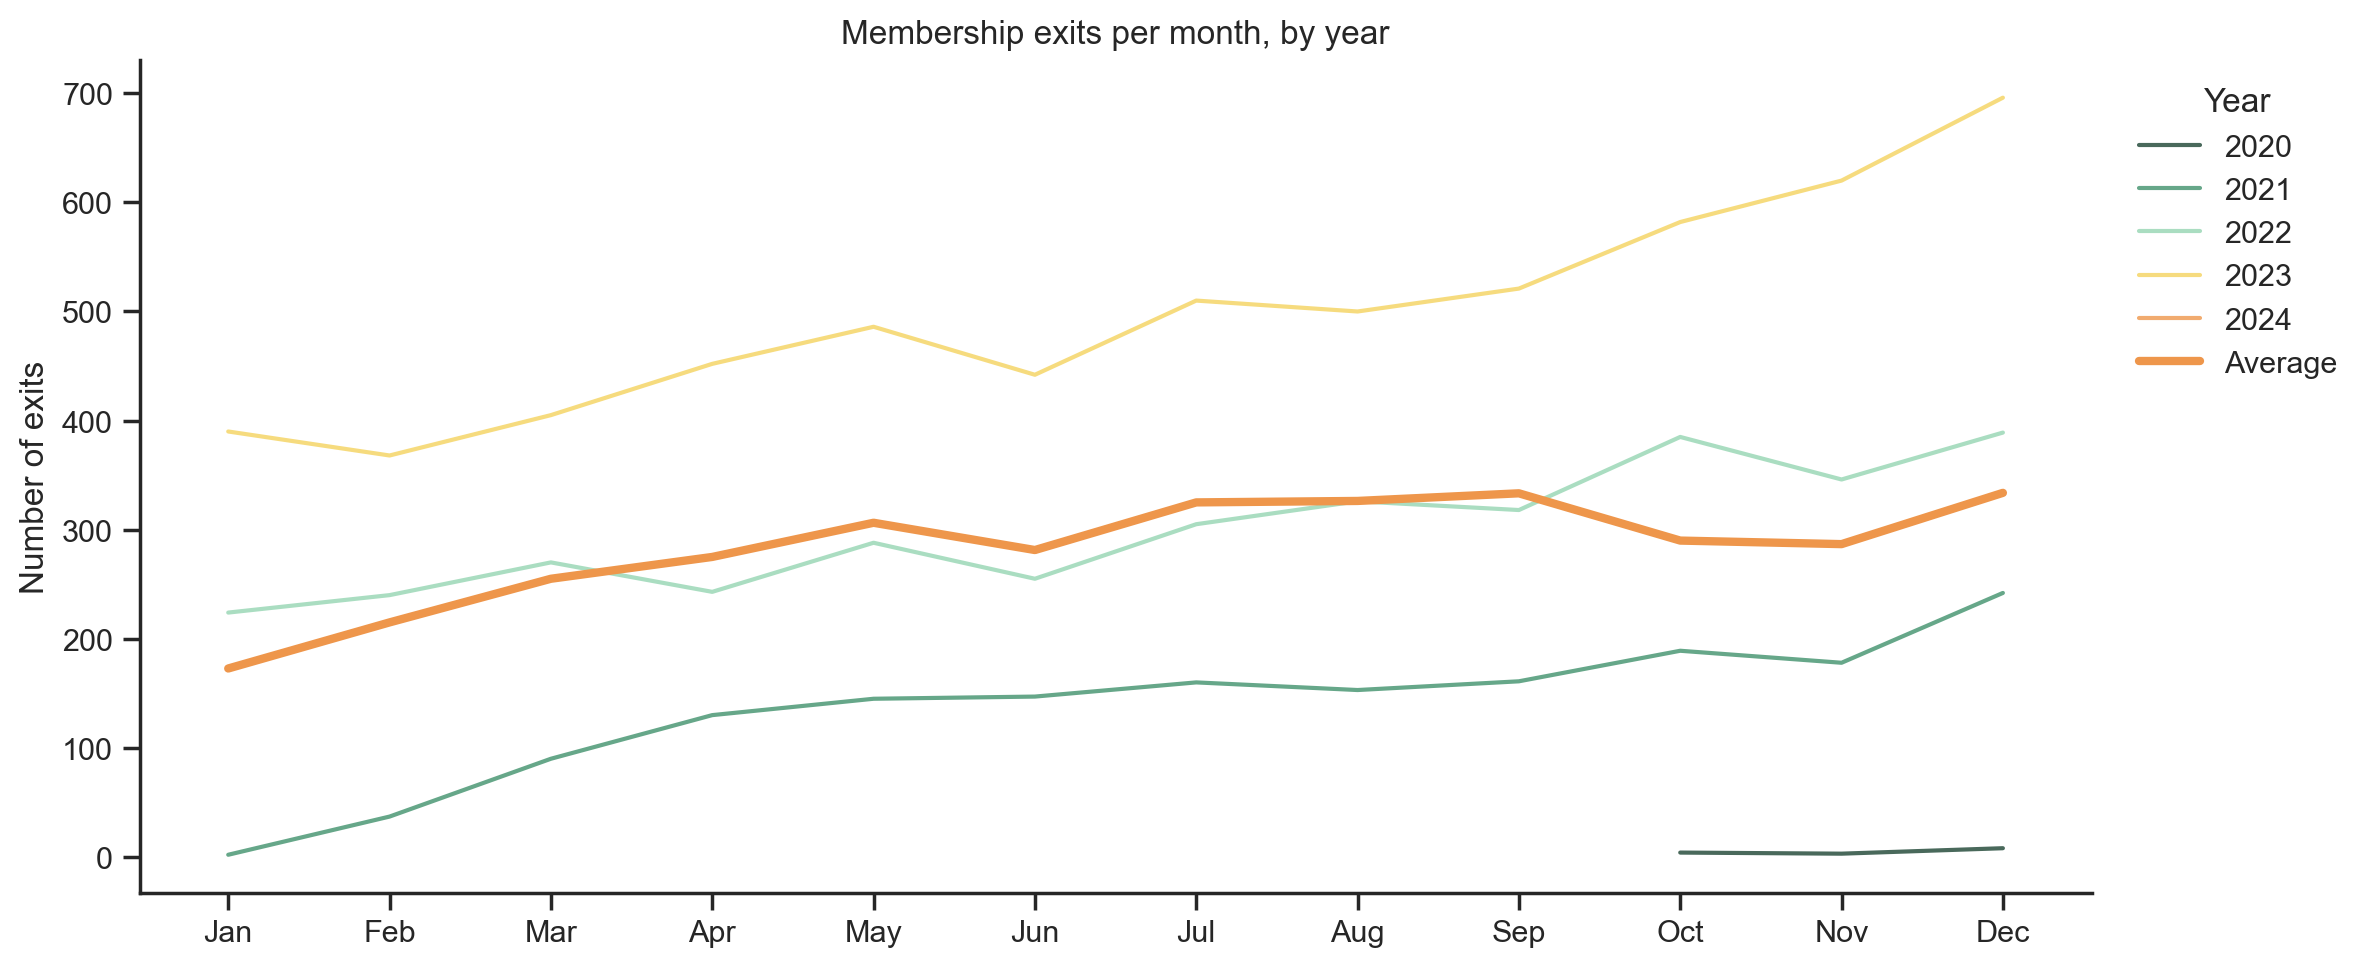

In [70]:
# só saídas reais (exclui o placeholder de 1970)
tmp = df_nodups.loc[df_nodups["membership_end"] != pd.Timestamp("1970-01-01")].copy()
tmp["year"] = tmp["membership_end"].dt.year
tmp["month"] = tmp["membership_end"].dt.month

# nº de saídas por (ano, mês)
pivot = tmp.pivot_table(index="month", columns="year", values="membership_end", aggfunc="count")

fig, ax = plt.subplots(figsize=(12, 5))

# uma linha fininha por ano
for color, year in zip(colors, pivot.columns):
    ax.plot(pivot.index, pivot[year], color=color, alpha=0.8, label=str(year))

# média de todos os anos (a "tendência" sazonal)
ax.plot(pivot.index, pivot.mean(axis=1), color="#EE964B", linewidth=3, label="Average")

ax.set_xticks(range(1, 13))
ax.set_xticklabels(["Jan", "Feb", "Mar", "Apr", "May", "Jun",
                    "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"])
ax.set_title("Membership exits per month, by year")
ax.set_xlabel("")
ax.set_ylabel("Number of exits")
ax.legend(title="Year", frameon=False, bbox_to_anchor=(1.01, 1), loc="upper left")
sns.despine()
plt.tight_layout()
plt.show()

The number of exits **increases** over time. In 2021 it rises from almost zero in January to about 240 in December, which is expected because the first memberships had just started. In 2022 there are about 225 to 390 exits per month, and in 2023 the values are the highest, from about 370 to almost 700 in December. Together with Figure 4, this shows that the company has been **losing clients faster than it has been gaining them**: new memberships decrease while exits increase. The values for 2020 (a few exits) are very small and may come from incorrect dates.

<b><font size="6" color="#FAA85E">8. Categorical Features Visualization</font></b><br>

In this section we built an interactive dashboard to analyze the categorical features and to compare them with the metric features.

In [71]:
object_features = ["industry", "country", "gender", "plan_tier"]
date_cols = ["membership_start", "membership_end", "last_badge_swipe"]
# Stringify dates so the grid can serialize them
df_grid = df_nodups.copy()
for c in date_cols:
    if c in df_grid.columns:
        df_grid[c] = df_grid[c].astype(str)

# Radio buttons: no raw date columns
radio_features = [c for c in metric_features
                  if c not in ["membership_start", "membership_end", "last_badge_swipe"]]

external_stylesheets = ['https://codepen.io/chriddyp/pen/bWLwgP.css']
app = Dash(external_stylesheets=external_stylesheets)

app.layout = html.Div(
    style={
        'backgroundColor': '#F7F9FB',
        'color': '#264653',
        'fontFamily': 'Helvetica, Arial, sans-serif',
        'padding': '20px',
        'minHeight': '100vh',
    },
    children=[
        # Title
        html.Div(className='row', children='My First App with Data, Graph, and Controls',
         style={'textAlign': 'center', 'color': colors[0], 'fontSize': 36,
                'fontWeight': 'bold', 'marginBottom': '20px'}),
        
        # Controls row: grouping
        html.Div(className='row', children=[
            html.Div(className='four columns', children=[
                dcc.Dropdown(options=object_features, value='industry',
                             id='group-dropdown', clearable=False),
    ]),
]),
            
        
        # Table
        html.Div(className='row', children=[
        html.Div(className='five columns', children=[
            dag.AgGrid(
                rowData=df_grid.to_dict('records'),
                columnDefs=[{"field": i, "filter": True, "sortable": True} for i in df_grid.columns],
                defaultColDef={"resizable": True},
                dashGridOptions={"pagination": True, "paginationPageSize": 15},
            )
        ]),
        html.Div(className='seven columns', children=[
            dcc.Graph(figure={}, id='categorical-dist')
        ]),
    ]),

        # Controls row: metric + aggregation
        html.Div(className='row', children=[
            html.Div(className='four columns', children=[
                dcc.Dropdown(options=radio_features, value=radio_features[0],
                             id='metric-dropdown', clearable=False),
            ]),
                ]),
        html.Div(className='row', children=[
            dcc.RadioItems(options=['avg', 'sum', 'count'], value='avg',
                           inline=True, id='agg-radio'),
                ]),

        # Controls row: filters
        html.Div(className='row', children=[
            html.Div(className='six columns', children=[
                dcc.Checklist(options=sorted(df_nodups['plan_tier'].dropna().unique()),
                            value=list(df_nodups['plan_tier'].dropna().unique()),
                            inline=True, id='tier-filter'),
                            ]),
            html.Div(className='six columns', children=[
                dcc.RadioItems(options=['All', 'Team', 'Individual'], value='All',
                            inline=True, id='team-filter'),
                            ]),
                ]),

        # normalized barchart and barchart
        html.Div(className='row', children=[
            html.Div(className='six columns', children=[
                dcc.Graph(figure={}, id='histo-chart-final')
            ]),

            html.Div(className='six columns', children=[
                            dcc.Graph(figure={}, id='norm-histo-chart-final')
                        ]),
        ]),
        
            # Second graph (boxplot)
            html.Div(className='row', children=[
                dcc.Graph(figure={}, id='box-chart')
            ]),
        ],
)

@callback(
    Output('categorical-dist', 'figure'),
    Input('group-dropdown', 'value'),
)
def update_cat_distribution(group):
    counts = (df_nodups[group].value_counts(dropna=False)
              .rename_axis(group).reset_index(name='count'))

    fig = px.bar(counts, x=group, y='count', color_discrete_sequence=colors)
    fig.update_layout(
        template='simple_white',
        paper_bgcolor='white',       # area around the plot
        plot_bgcolor='white',        # plot area
        font=dict(family='Helvetica', color='#264653', size=13),
        title_font_color=colors[0],
        )
    fig.update_xaxes(showgrid=False, linecolor='#264653')
    fig.update_yaxes(gridcolor='#E5E5E5')
    return fig

@callback(
        Output('histo-chart-final', 'figure'),
        Output('norm-histo-chart-final', 'figure'),
        Output('box-chart', 'figure'),
        Input('group-dropdown', 'value'),
        Input('metric-dropdown', 'value'),
        Input('tier-filter', 'value'),
        Input('team-filter', 'value'),
        Input('agg-radio', 'value'),
)
def update_graph(group, col_chosen, tiers, team, agg):
    d = df_nodups[df_nodups['plan_tier'].isin(tiers)]
    if team == 'Team':
        d = d[d['is_team_account']]
    elif team == 'Individual':
        d = d[~d['is_team_account']]

    fig1 = px.histogram(d, x=group, y=col_chosen, histfunc=agg,
                    color="plan_tier", barmode="stack",
                    color_discrete_sequence=colors)
    fig1.update_layout(template='simple_white')

    fig2 = px.histogram(d, x=group, y=col_chosen, histfunc=agg,
                        color="plan_tier", barmode="stack", barnorm="percent",
                        color_discrete_sequence=colors)
    fig2.update_layout(template='simple_white')

    fig3 = px.box(d, x=group, y=col_chosen, color_discrete_sequence=colors)
    fig3.update_layout(template='simple_white')

    for f in (fig1, fig2, fig3):
        f.update_layout(
        template='simple_white',
        paper_bgcolor='white',       # area around the plot
        plot_bgcolor='white',        # plot area
        font=dict(family='Helvetica', color='#264653', size=13),
        title_font_color=colors[0],
        )
        f.update_xaxes(showgrid=False, linecolor='#264653')
        f.update_yaxes(gridcolor='#E5E5E5')
    return fig1, fig2, fig3


if __name__ == '__main__':
    app.run(debug=True)

OSError: Address 'http://127.0.0.1:8050' already in use.
    Try passing a different port to run.

<b><font size="5" color="#FAA85E"> 9. Deeper exploration of relations between variable</font></b><br>     

<b><font size="4" color="#FAA85E"> 9.1. What is happening with customers on the 5-day and 7-day plans?</font></b><br>     

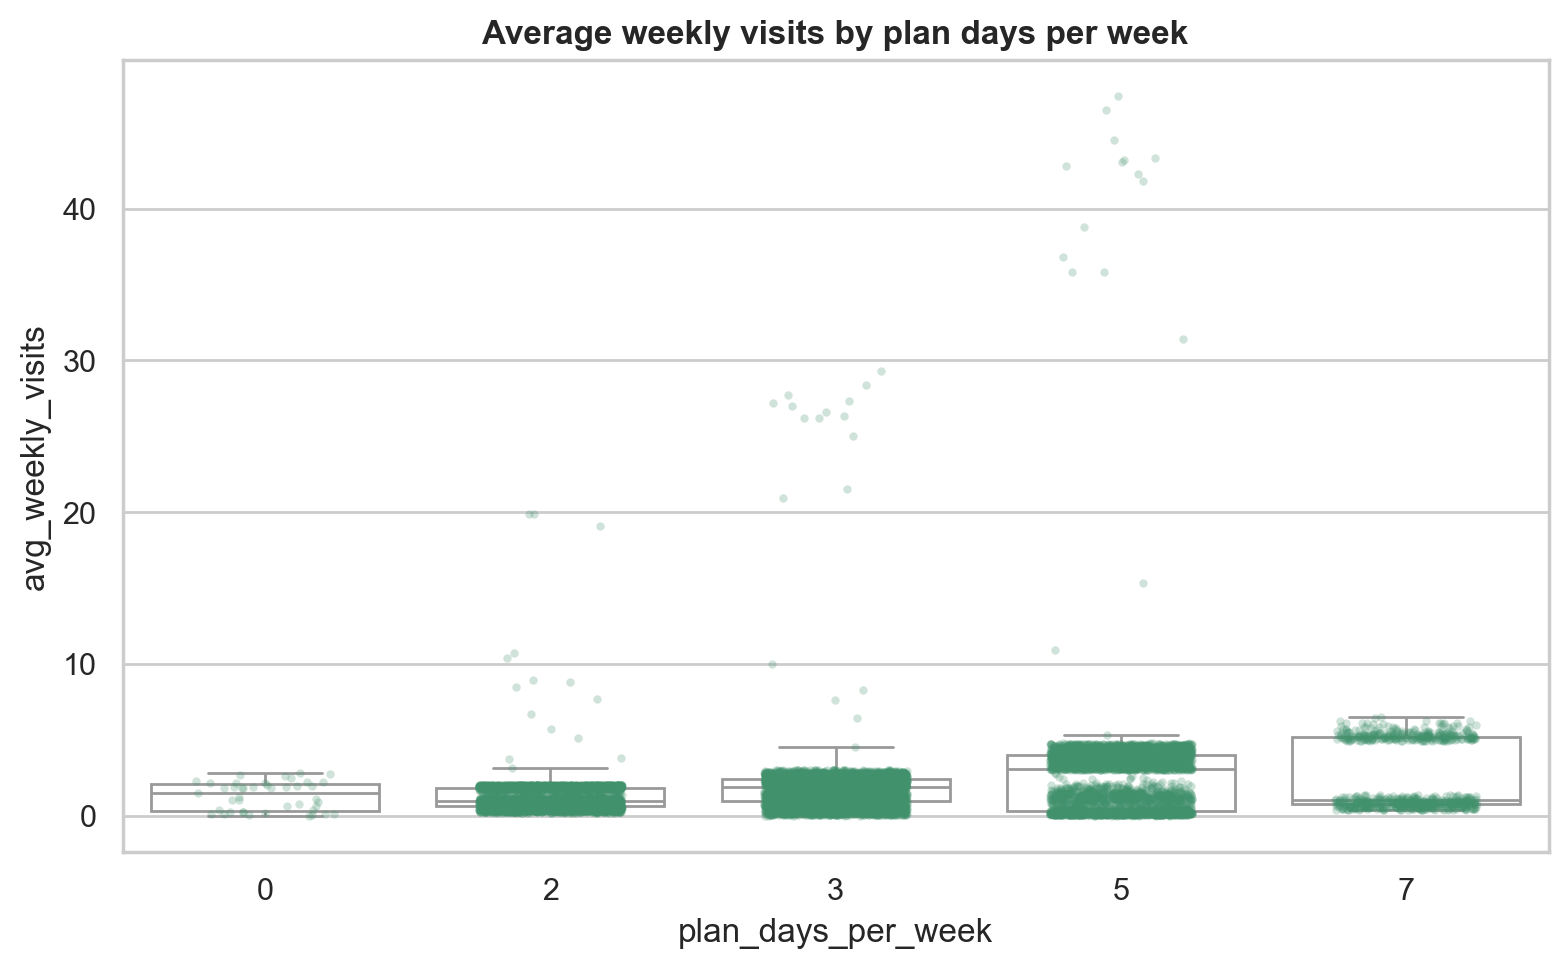

In [82]:
d = df_nodups[df_nodups["plan_days_per_week"] <= 7].dropna(subset=["avg_weekly_visits", "plan_days_per_week"]).copy()

with sns.axes_style("whitegrid"):
    fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(data=d, x="plan_days_per_week", y="avg_weekly_visits", color="white", showfliers=False, ax=ax)
sns.stripplot(data=d, x="plan_days_per_week", y="avg_weekly_visits", color=main_color,
              alpha=0.25, size=3, jitter=0.25, ax=ax)
ax.set_title('Average weekly visits by plan days per week', fontweight="bold")
ax.set_xlabel('plan_days_per_week')
ax.set_ylabel('avg_weekly_visits')

plt.tight_layout()
plt.show()

This plot caught our attention because there seems to be a strong polarization in the behaviour of the customers who subscribe to the plans with the highest number of days, especially the 5-day and 7-day plans: some customers use the space very little (about one visit per week), while others use it almost every day of their plan. Consequently, it may be particularly relevant for the company to understand why this happens. Some hypotheses to analyse:

- **Team accounts:** are most subscribers team accounts that subscribe to the service so that the company has the space available, and therefore do not feel the need to use the coworking space frequently? (this can be tested with `is_team_account`)
- **Plan type:** could the polarization come from a mix of plan types (`plan_tier`) with the same number of days?
- **Personal preference:** some customers may choose a plan with many days just to be covered in case they need it, and visit rarely by personal choice, which would have nothing to do with the quality of the plan. If this is the case, we would expect low-use customers to renew as much as high-use customers (`n_renewals`).

These are only hypotheses, and they will be tested by comparing the two groups of usage.

In [83]:
print(f"{(df_nodups["plan_days_per_week"]==5).sum()} subscribed a 5-day plan")
print(f"{(df_nodups["plan_days_per_week"]==7).sum()} subscribed a 7-day plan")

3973 subscribed a 5-day plan
704 subscribed a 7-day plan


In [84]:
counts = df_nodups.groupby(["plan_days_per_week", "usage_group"]).size().rename("n")
pct = (counts / counts.groupby(level=0).transform("sum") * 100).round(1).rename("% of plan")

table = pd.concat([counts, pct], axis=1).sort_index(level=[0, 1], ascending=[True, False])
table

n  % of plan
plan_days_per_week usage_group                 
5                  1            2106       53.0
                   0            1867       47.0
7                  1             279       39.6
                   0             425       60.4

We use 3 visits per week as the threshold between low and high use. It is a reasonable number of visits for a customer, even with a plan with many days, and in the plot it falls between the two groups we can see. 

With this threshold, the pattern of the plot is confirmed: the customers of the 5-day plan are almost evenly split between low use (47%) and high use (53%), while most customers of the 7-day plan (60%) belong to the low-use group and only 40% use the plan intensively. This means that the 7-day plan is, more often than the 5-day plan, used much less than it allows. In both plans, however, the two groups are large, so they represent two real profiles of customers and not rare cases.

#### Are these team accounts?

In [85]:
d["usage_group"] = np.where(d["avg_weekly_visits"] >= 3, "High use", "Low use")

table = d.groupby(["plan_days_per_week", "is_team_account"]).agg(
    n=("usage_group", "size"),
    low_use_pct=("usage_group", lambda s: round((s == "Low use").mean() * 100, 1))
)

table["% of plan"] = (table["n"] / table.groupby(level=0)["n"].transform("sum") * 100).round(1)
table = table[["n", "% of plan", "low_use_pct"]]
table

n  % of plan  low_use_pct
plan_days_per_week is_team_account                              
0                  False              27       62.8        100.0
                   True               16       37.2        100.0
2                  False            3661       71.9         99.7
                   True             1428       28.1         99.7
3                  False            3789       71.4         99.4
                   True             1519       28.6         99.9
5                  False            2905       73.1         47.4
                   True             1068       26.9         45.8
7                  False             486       69.0         59.7
                   True              218       31.0         61.9

To test the first hypothesis, we compared team accounts with the other customers. Team accounts are a minority in both plans (27% in the 5-day plan and 31% in the 7-day plan) and their share of low-use customers is practically the same as for the other customers (45.8% vs 47.4% in the 5-day plan, and 61.9% vs 59.7% in the 7-day plan). Therefore, team accounts do not explain the polarization.

#### Are low-use customers unhappy with the plan, or is it just a personal choice?

In [86]:
d.groupby(["plan_days_per_week", "usage_group"]).agg(
    n=("usage_group", "size"),
    mean_renewals=("n_renewals", "mean"),
    median_renewals=("n_renewals", "median")
).round(1)

n  mean_renewals  median_renewals
plan_days_per_week usage_group                                      
0                  Low use        43            1.0              1.0
2                  High use       15            0.2              0.0
                   Low use      5074            0.4              0.0
3                  High use       22            0.5              0.0
                   Low use      5286            0.8              0.0
5                  High use     2106            2.1              2.0
                   Low use      1867            1.4              1.0
7                  High use      279            2.3              2.0
                   Low use       425            2.7              2.0

Our initial scenario seems to be inverted. Low-use customers of the 5-day plan renew less than low-use customers of the 7-day plan (median of 1.0 vs. 2.0 renewals), and also less than high-use customers of their own plan (mean of 1.4 vs. 2.1). Moreover, low-use customers of the 7-day plan renew slightly more, on average, than high-use customers (2.7 vs. 2.3), which makes us believe that their low use could just be a personal choice.

However, this is still not enough to state a strong conclusion, as renewals also depend on how long a customer has been subscribed. Still, we now know there could be a problem among the low-use customers of the 5-day plan, which we did not expect at the beginning, since the most polarized group seemed to be the 7-day plan. Next, we are going to analyse something that may clarify this: the `plan_tier`. Could it be the real reason for the differences in renewals?

#### Breaking down the results by plan tier

In [87]:
d_ok = d[d["plan_tier"].notna()].copy()

rows = ["plan_days_per_week", "usage_group"]

mean_ren = d_ok.pivot_table(index=rows, columns="plan_tier", values="n_renewals", aggfunc="mean").round(1)
n_cust = pd.crosstab([d_ok["plan_days_per_week"], d_ok["usage_group"]], d_ok["plan_tier"])

table = pd.concat({"mean renewals": mean_ren, "n customers": n_cust}, axis=1)
table

mean renewals                          \
plan_tier                      dedicated_desk flex full_time hot_desk   
plan_days_per_week usage_group                                          
0                  Low use                1.0  1.1       1.8      0.5   
2                  High use               NaN  NaN       NaN      0.2   
                   Low use                NaN  NaN       NaN      0.4   
3                  High use               NaN  0.5       NaN      NaN   
                   Low use                NaN  0.8       NaN      NaN   
5                  High use               2.4  NaN       1.8      NaN   
                   Low use                2.1  NaN       1.1      NaN   
7                  High use               NaN  NaN       NaN      NaN   
                   Low use                NaN  NaN       NaN      NaN   

                                                 n customers                  \
plan_tier                      private_office dedicated_desk  flex full_time   
plan_days_per_week usage_group                                                 
0                  Low use                3.0              3    20         5   
2                  High use               NaN              0     0         0   
                   Low use                NaN              0     0         0   
3                  High use               NaN              0    22         0   
                   Low use                NaN              0  5286         0   
5                  High use               NaN            992     0      1074   
                   Low use                NaN            521     0      1337   
7                  High use               2.3              0     0         0   
                   Low use                2.7              0     0         0   

                                                        
plan_tier                      hot_desk private_office  
plan_days_per_week usage_group                          
0                  Low use           14              1  
2                  High use          15              0  
                   Low use         5074              0  
3                  High use           0              0  
                   Low use            0              0  
5                  High use           0              0  
                   Low use            0              0  
7                  High use           0            254  
                   Low use            0            397

There is an interesting finding in this table: plan type and number of days are strongly linked. Only `dedicated_desk` and `full_time` customers have the 5-day plan, and the 7-day plan is made only of `private_office` customers. This makes it easier to relate the differences to a specific plan type. Looking at the average number of renewals in the table above:

- **`dedicated_desk`:** renewals are similar whether customers use the plan often or not (2.4 for high use vs. 2.1 for low use).
- **`full_time`:** renewals are clearly lower for low-use customers (1.1 vs. 1.8 for high use). This is also the largest low-use group (1,337 customers), so it is the one that deserves more attention.
- **`private_office`:** as we concluded before, it does not seem to be a problem for now, since low-use customers renew as much as high-use ones (2.7 vs. 2.3).

These are only averages, and, as mentioned before, renewals also depend on how long a customer has been subscribed, so this still needs to be checked.

To compute the length of subscription we assume that the data were extracted on 2024-01-01 and that `membership_end = 1970-01-01` means that the customer is still active (in this case, the subscription is counted until the extraction date). Records with a non-positive length of subscription were excluded, which is why the number of customers is slightly lower than in the previous table.

In [88]:
d_ok = d[d["plan_tier"].notna()].copy()

snapshot = pd.Timestamp("2024-01-01")    # data aproximada do snapshot (assumida)
start = d_ok["membership_start"]
end = d_ok["membership_end"]
end = end.where(end > pd.Timestamp("1970-01-01"), snapshot)    # o 1970-01-01 é o placeholder de "ainda ativo"

d_ok["tenure_years"] = (end - start).dt.days / 365
d_ok = d_ok[d_ok["tenure_years"] > 0]

res = d_ok.groupby(["plan_days_per_week", "plan_tier", "usage_group"]).agg(
    n=("usage_group", "size"),
    median_tenure_years=("tenure_years", "median"),
    mean_renewals=("n_renewals", "mean"),
    total_renewals=("n_renewals", "sum"),
    total_tenure=("tenure_years", "sum")
)

res["renewals_per_year"] = res["total_renewals"] / res["total_tenure"]

res[["n", "median_tenure_years", "mean_renewals", "renewals_per_year"]].round(2)

n  median_tenure_years  \
plan_days_per_week plan_tier      usage_group                              
0                  dedicated_desk Low use         3                 1.89   
                   flex           Low use        20                 1.27   
                   full_time      Low use         5                 1.82   
                   hot_desk       Low use        14                 0.22   
                   private_office Low use         1                 2.56   
2                  hot_desk       High use       14                 0.18   
                                  Low use      4999                 0.22   
3                  flex           High use       22                 0.55   
                                  Low use      5229                 0.72   
5                  dedicated_desk High use      984                 2.24   
                                  Low use       518                 2.17   
                   full_time      High use     1058                 1.59   
                                  Low use      1317                 1.27   
7                  private_office High use      249                 2.26   
                                  Low use       391                 2.72   

                                               mean_renewals  \
plan_days_per_week plan_tier      usage_group                  
0                  dedicated_desk Low use               1.00   
                   flex           Low use               1.10   
                   full_time      Low use               1.80   
                   hot_desk       Low use               0.50   
                   private_office Low use               3.00   
2                  hot_desk       High use              0.21   
                                  Low use               0.42   
3                  flex           High use              0.55   
                                  Low use               0.80   
5                  dedicated_desk High use              2.43   
                                  Low use               2.13   
                   full_time      High use              1.76   
                                  Low use               1.11   
7                  private_office High use              2.33   
                                  Low use               2.70   

                                               renewals_per_year  
plan_days_per_week plan_tier      usage_group                     
0                  dedicated_desk Low use                   0.51  
                   flex           Low use                   0.81  
                   full_time      Low use                   1.02  
                   hot_desk       Low use                   0.77  
                   private_office Low use                   1.17  
2                  hot_desk       High use                  0.52  
                                  Low use                   0.79  
3                  flex           High use                  0.74  
                                  Low use                   0.93  
5                  dedicated_desk High use                  1.14  
                                  Low use                   0.98  
                   full_time      High use                  1.12  
                                  Low use                   0.91  
7                  private_office High use                  1.11  
                                  Low use                   1.11

Since the number of renewals depends on how long a customer has been subscribed, we compared the number of renewals per year of subscription, which changes some of the previous conclusions:

- In the **7-day plan (`private_office`)**, low-use and high-use customers renew at exactly the same rate (1.11 renewals per year). The fact that low-use customers seemed to renew more before was only because they are older customers (2.7 vs. 2.3 years). So their low use does not seem to affect renewals, and it is probably a personal choice.
- In the **5-day plan**, low-use customers renew somewhat less than high-use ones, in both `dedicated_desk` (0.98 vs. 1.14) and `full_time` (0.91 vs. 1.12), which is about 14% and 19% less. The difference is smaller than the raw number of renewals suggested (for `full_time`, a large part was due to low-use customers being more recent), and they still renew almost once a year. Therefore, the problem we thought we had found in the 5-day plan is real but moderate, and not specific to one plan type.

In short, low use is not strongly related to fewer renewals, so it should be seen as a different way of using the plan and not as a clear sign of dissatisfaction. Still, the low-use customers of the 5-day plan (about 1,800) are a group worth monitoring.

In [89]:
pd.crosstab(df_nodups["plan_days_per_week"], df_nodups["plan_tier"])

plan_tier,dedicated_desk,flex,full_time,hot_desk,private_office
plan_days_per_week,,,,,
0,3,20,5,14,1
2,0,0,0,5089,0
3,0,5308,0,0,0
5,1513,0,2411,0,0
7,0,0,0,0,651
9,6,22,10,14,1


**Implications for the segmentation.** The main finding of this section is that, in the 5-day and 7-day plans, customers split into two clearly different usage profiles (low and high use), and plan variables alone cannot separate them. This suggests that the clustering should also include usage variables, such as `avg_weekly_visits`, so that low-use and high-use customers of the same plan can end up in different clusters.

**Additional finding:** the cross-tabulation of `plan_tier` and `plan_days_per_week` shows that each plan type corresponds to a single number of days (`hot_desk` to 2, `flex` to 3, `dedicated_desk` and `full_time` to 5 and `private_office` to 7), except for a few records with 0 or 9 days, which are invalid values. Thus, `plan_days_per_week` is redundant given `plan_tier`, and keeping only `plan_tier` is enough for the clustering.

<b><font size="5" color="#FAA85E"> 9.2. Individual vs Team Account</font></b><br>

We assume that when `membership_end` = _1970-01-01_ it means the client did not end the membership.

We also assume that the reference date (the last date recorded in the system) is _2023-12-31_.

!!! ver em que DF criar as variáveis

First we will check how the type of account (individual or team) affects the canceled memberships (costumers that churned).

has_churned,False,True,All
is_team_account,,,
False,2837,8068,10905
True,1048,3217,4265
All,3885,11285,15170


has_churned,False,True
is_team_account,,
False,26.02,73.98
True,24.57,75.43
All,25.61,74.39


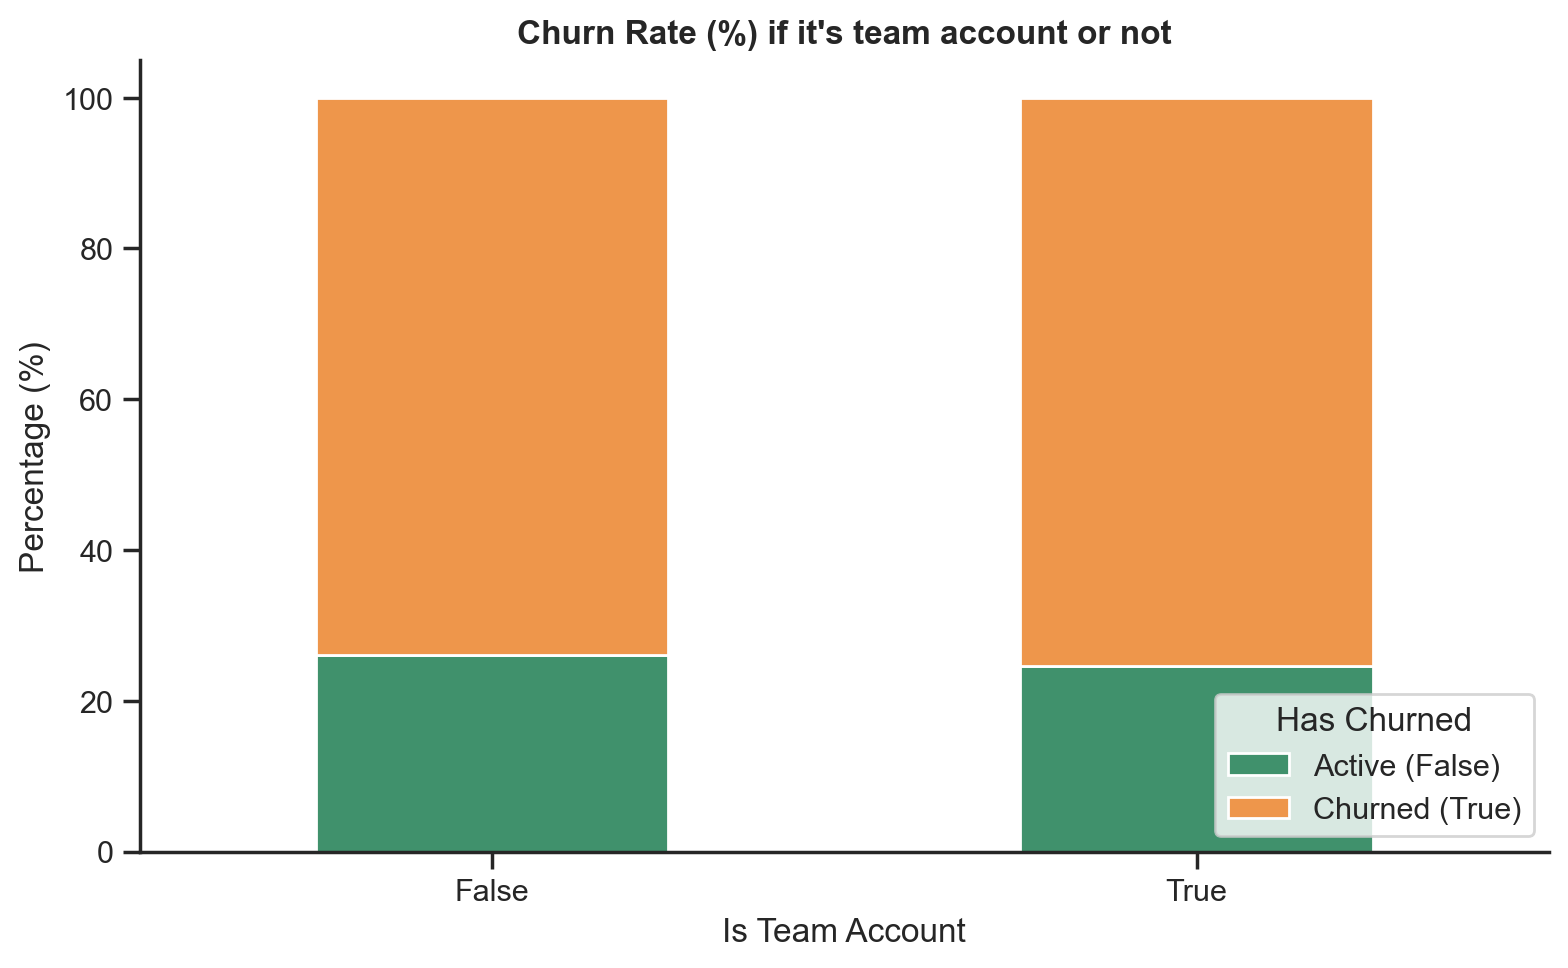

In [76]:
ct_churn = pd.crosstab(
    df_nodups["is_team_account"], 
    df_nodups["has_churned"],
     margins=True
)
display(ct_churn)

ct_churn_pct = (pd.crosstab(
    df_nodups["is_team_account"], 
    df_nodups["has_churned"],
    normalize="index",
    margins=True
) * 100).round(2)
display(ct_churn_pct)

with sns.axes_style("ticks"):
    ax = ct_churn_pct.drop("All", errors="ignore").plot.bar(
        stacked=True, 
        color=[main_color, colors[4]], 
        figsize=(8, 5)
    )

ax.set_title("Churn Rate (%) if it's team account or not", fontweight="bold")
ax.set_xlabel("Is Team Account")
ax.set_ylabel("Percentage (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Has Churned", labels=["Active (False)", "Churned (True)"], loc="lower right")

sns.despine()
plt.tight_layout()
plt.show()

We conclude that it does not affect the probability of cancelation significatly.

But what about the number of clients in each account? Does that have anything to do with cancelling the membership?

has_churned,False,True,All
n_colleagues_on_account,,,
1,422,1300,1722
2,268,821,1089
3,206,507,713
4,75,305,380
5,36,104,140
6,8,47,55
7,3,11,14
All,1018,3095,4113


has_churned,False,True
n_colleagues_on_account,,
1,24.51,75.49
2,24.61,75.39
3,28.89,71.11
4,19.74,80.26
5,25.71,74.29
6,14.55,85.45
7,21.43,78.57


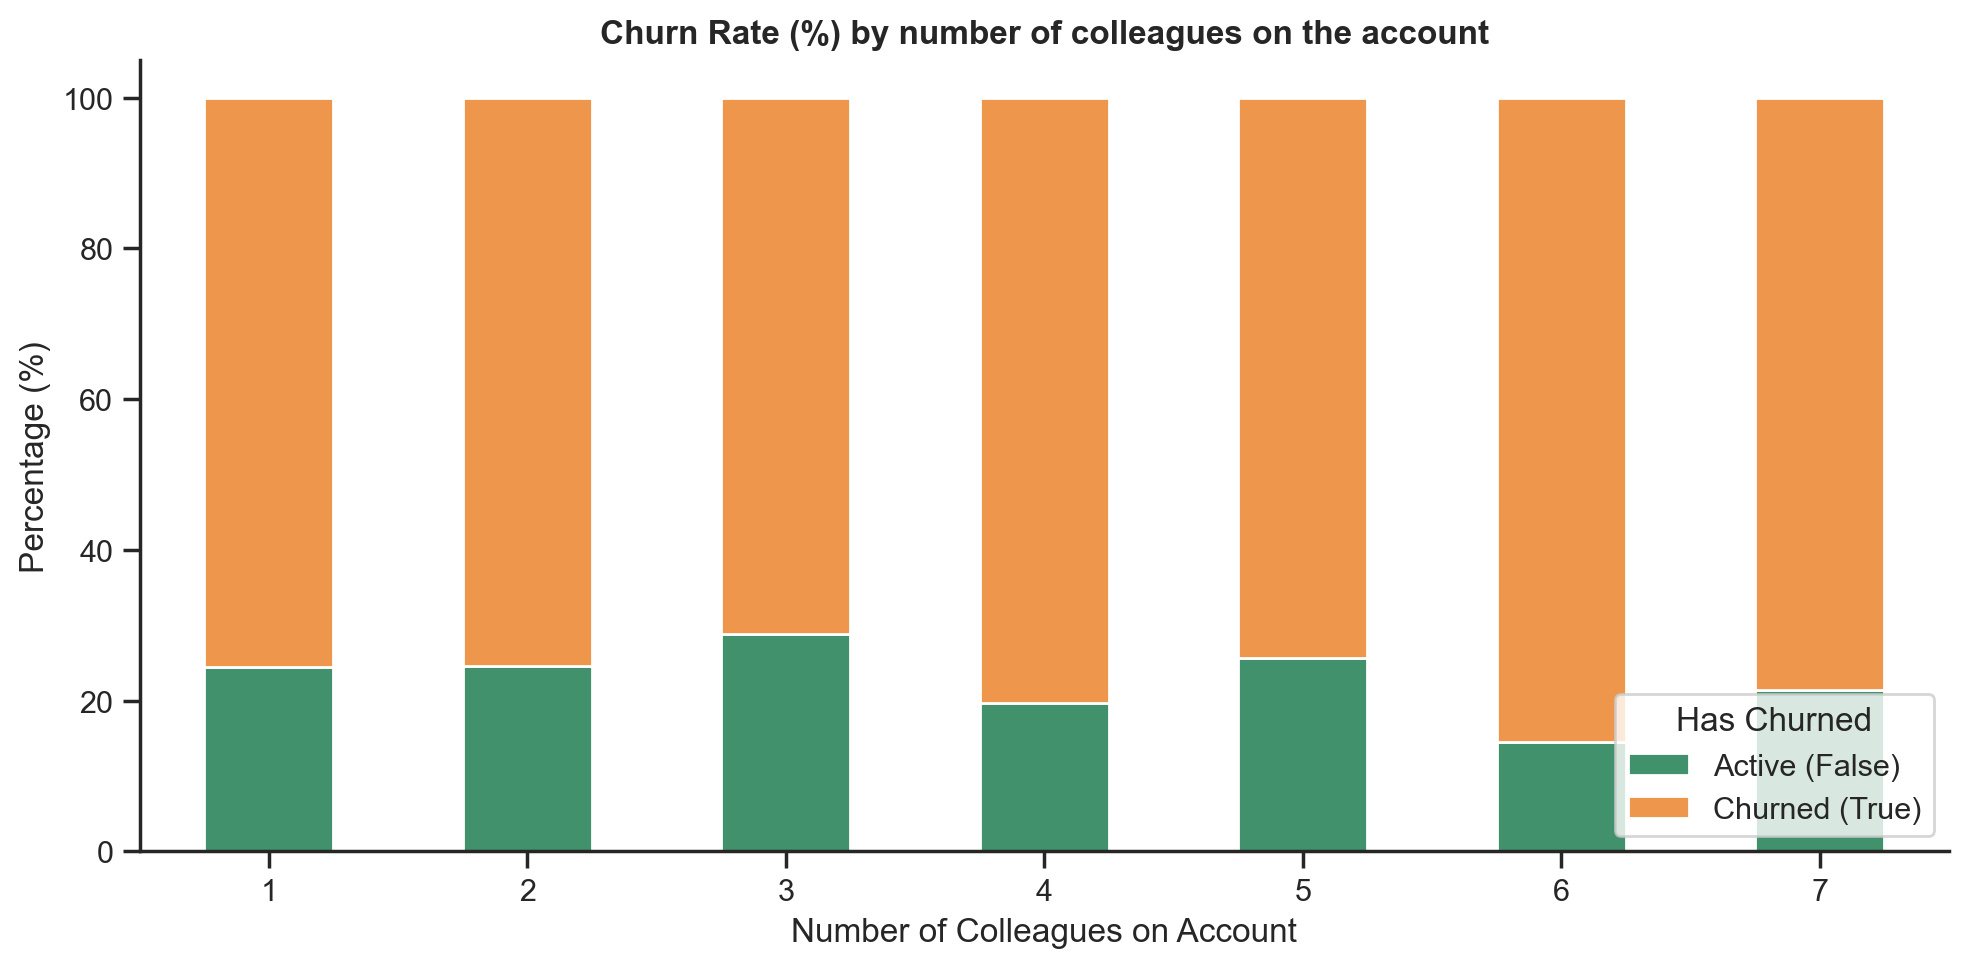

In [77]:
df_colleagues_churn = df_nodups[(df_nodups["n_colleagues_on_account"] > 0) & (df_nodups["n_colleagues_on_account"] <=7)]

ct_col_churn = pd.crosstab(
    df_colleagues_churn["n_colleagues_on_account"],
    df_colleagues_churn["has_churned"],
    margins=True
)
display(ct_col_churn)

ct_col_churn_pct = (pd.crosstab(
    df_colleagues_churn["n_colleagues_on_account"],
    df_colleagues_churn["has_churned"],
    normalize="index"
) * 100).round(2)
display(ct_col_churn_pct)

with sns.axes_style("ticks"):
    ax = ct_col_churn_pct.plot.bar(
        stacked=True,
        color=[main_color, colors[4]],
        figsize=(10, 5)
    )

ax.set_title("Churn Rate (%) by number of colleagues on the account", fontweight="bold")
ax.set_xlabel("Number of Colleagues on Account")
ax.set_ylabel("Percentage (%)")
ax.tick_params(axis="x", rotation=0)
ax.legend(title="Has Churned", labels=["Active (False)", "Churned (True)"], loc="lower right")

sns.despine()
plt.tight_layout()
plt.show()

The number of colleagues on account also does not have significant impact on the cancelation of the membership.

What about the total duration of the contract? Is that afected by the type of account? 

,count,mean,median,std
is_team_account,,,,
False,10772,374.49,283.0,338.40
True,4206,379.51,295.0,339.29


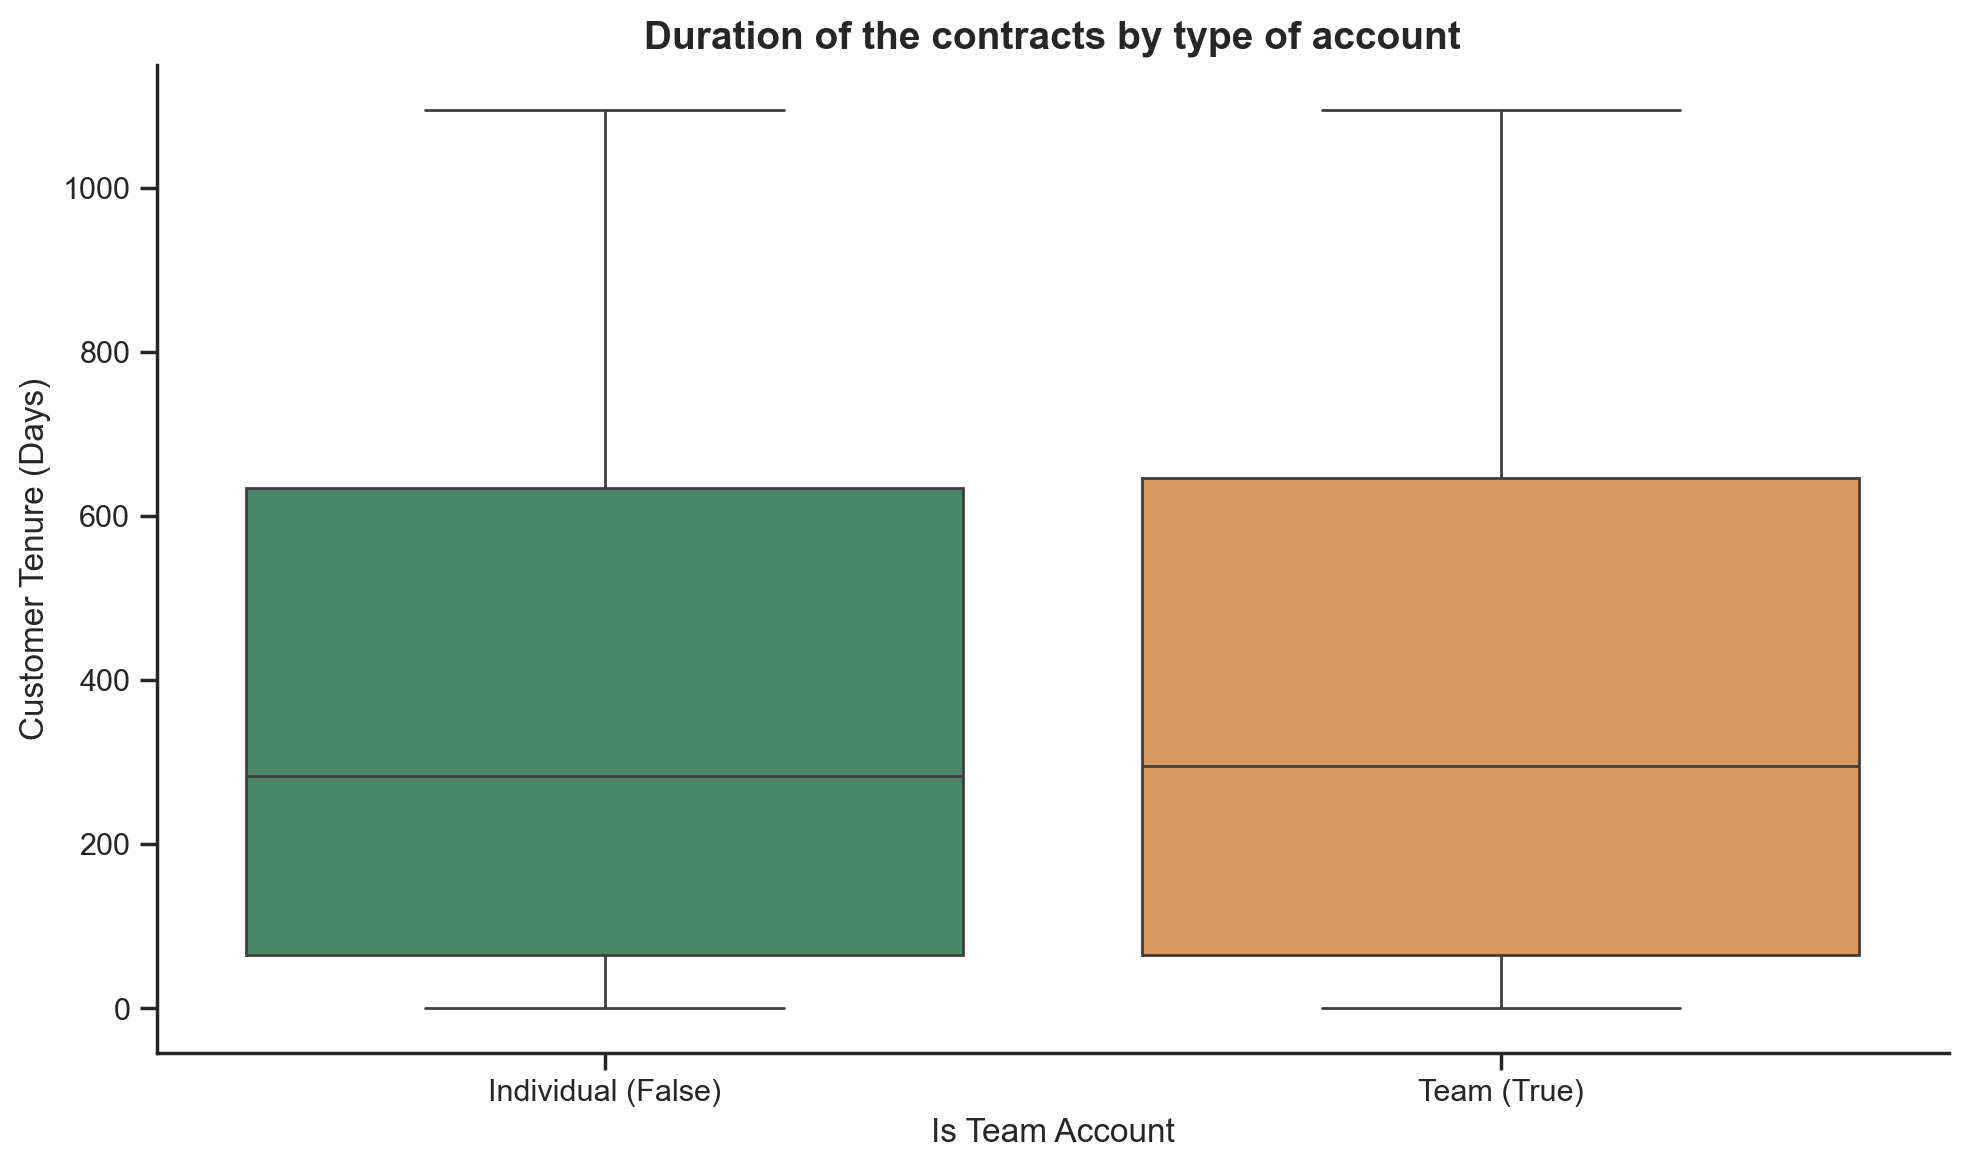

In [78]:
df_tenure_clean = df_nodups[df_nodups['tenure_days'] >= 0]

tenure_summary = df_tenure_clean.groupby("is_team_account")["tenure_days"].agg(
    ["count", "mean", "median", "std"]
).round(2)

display(tenure_summary)

sns.set_style('ticks')

fig, ax = plt.subplots(figsize=(10, 6))

sns.boxplot(
    data=df_tenure_clean,
    x="is_team_account",
    y="tenure_days",
    hue="is_team_account",          
    palette=[main_color, colors[4]],
    legend=False,
    ax=ax
)

ax.set_title("Duration of the contracts by type of account", fontweight="bold", fontsize=14)
ax.set_xlabel("Is Team Account", fontsize=12)
ax.set_ylabel("Customer Tenure (Days)", fontsize=12)
ax.set_xticks([0, 1])
ax.set_xticklabels(["Individual (False)", "Team (True)"])

sns.despine()
plt.tight_layout()
plt.show()

We also conclude that does not happen.

The 2 types of accounts behave very similarly when it comes to canceling the membership or the duration of it.

!! no final meter a matriz de correlação com todas as variáveis? (para incluir as novas)

<b><font size="5" color="#FAA85E"> 9.3. </font></b><br>

In [97]:
# Age groups: only valid ages (18-90), the same filter used in the age analysis
df_age = df_nodups[(df_nodups["age"] >= 18) & (df_nodups["age"] <= 90)].copy()

age_bins = [17, 24, 34, 44, 54, 90]
age_labels = ["18-24", "25-34", "35-44", "45-54", "55+"]
df_age["age_group"] = pd.cut(df_age["age"], bins=age_bins, labels=age_labels)

print("Customers with a valid age:", len(df_age), "of", len(df_nodups))
display(df_age["age_group"].value_counts().sort_index())

# valid versions of the metrics to compare (invalid / non-paying values left out)
df_age["ltv_pos"] = df_age["lifetime_value"].where(df_age["lifetime_value"] > 0)
df_age["utilization_valid"] = df_age["utilization_rate"].where(df_age["utilization_rate"] >= 0)
df_age["tenure_valid"] = df_age["tenure_days"].where(df_age["tenure_days"] >= 0)

# Summary table by age group
summary_age = df_age.groupby("age_group", observed=True).agg(
    n_customers=("age", "size"),
    churn_rate=("has_churned", "mean"),
    median_ltv=("ltv_pos", "median"),
    median_utilization=("utilization_valid", "median"),
    median_tenure_days=("tenure_valid", "median"),
    mean_n_add_on=("n_add_on", "mean"),
    mean_renewals_per_year=("renewals_per_year", "mean")
).round(2)
display(summary_age)

Customers with a valid age: 14480 of 15170


age_group
18-24    1689
25-34    5634
35-44    5377
45-54    1608
55+       172
Name: count, dtype: int64

,n_customers,churn_rate,median_ltv,median_utilization,median_tenure_days,mean_n_add_on,mean_renewals_per_year
age_group,,,,,,,
18-24,1689,0.75,1866.36,0.50,298.0,1.86,3.57
25-34,5634,0.74,1638.79,0.52,277.0,1.78,2.53
35-44,5377,0.75,1659.22,0.52,288.0,1.84,2.33
45-54,1608,0.73,1914.74,0.48,319.5,1.84,1.91
55+,172,0.70,2779.60,0.53,396.0,1.98,2.42


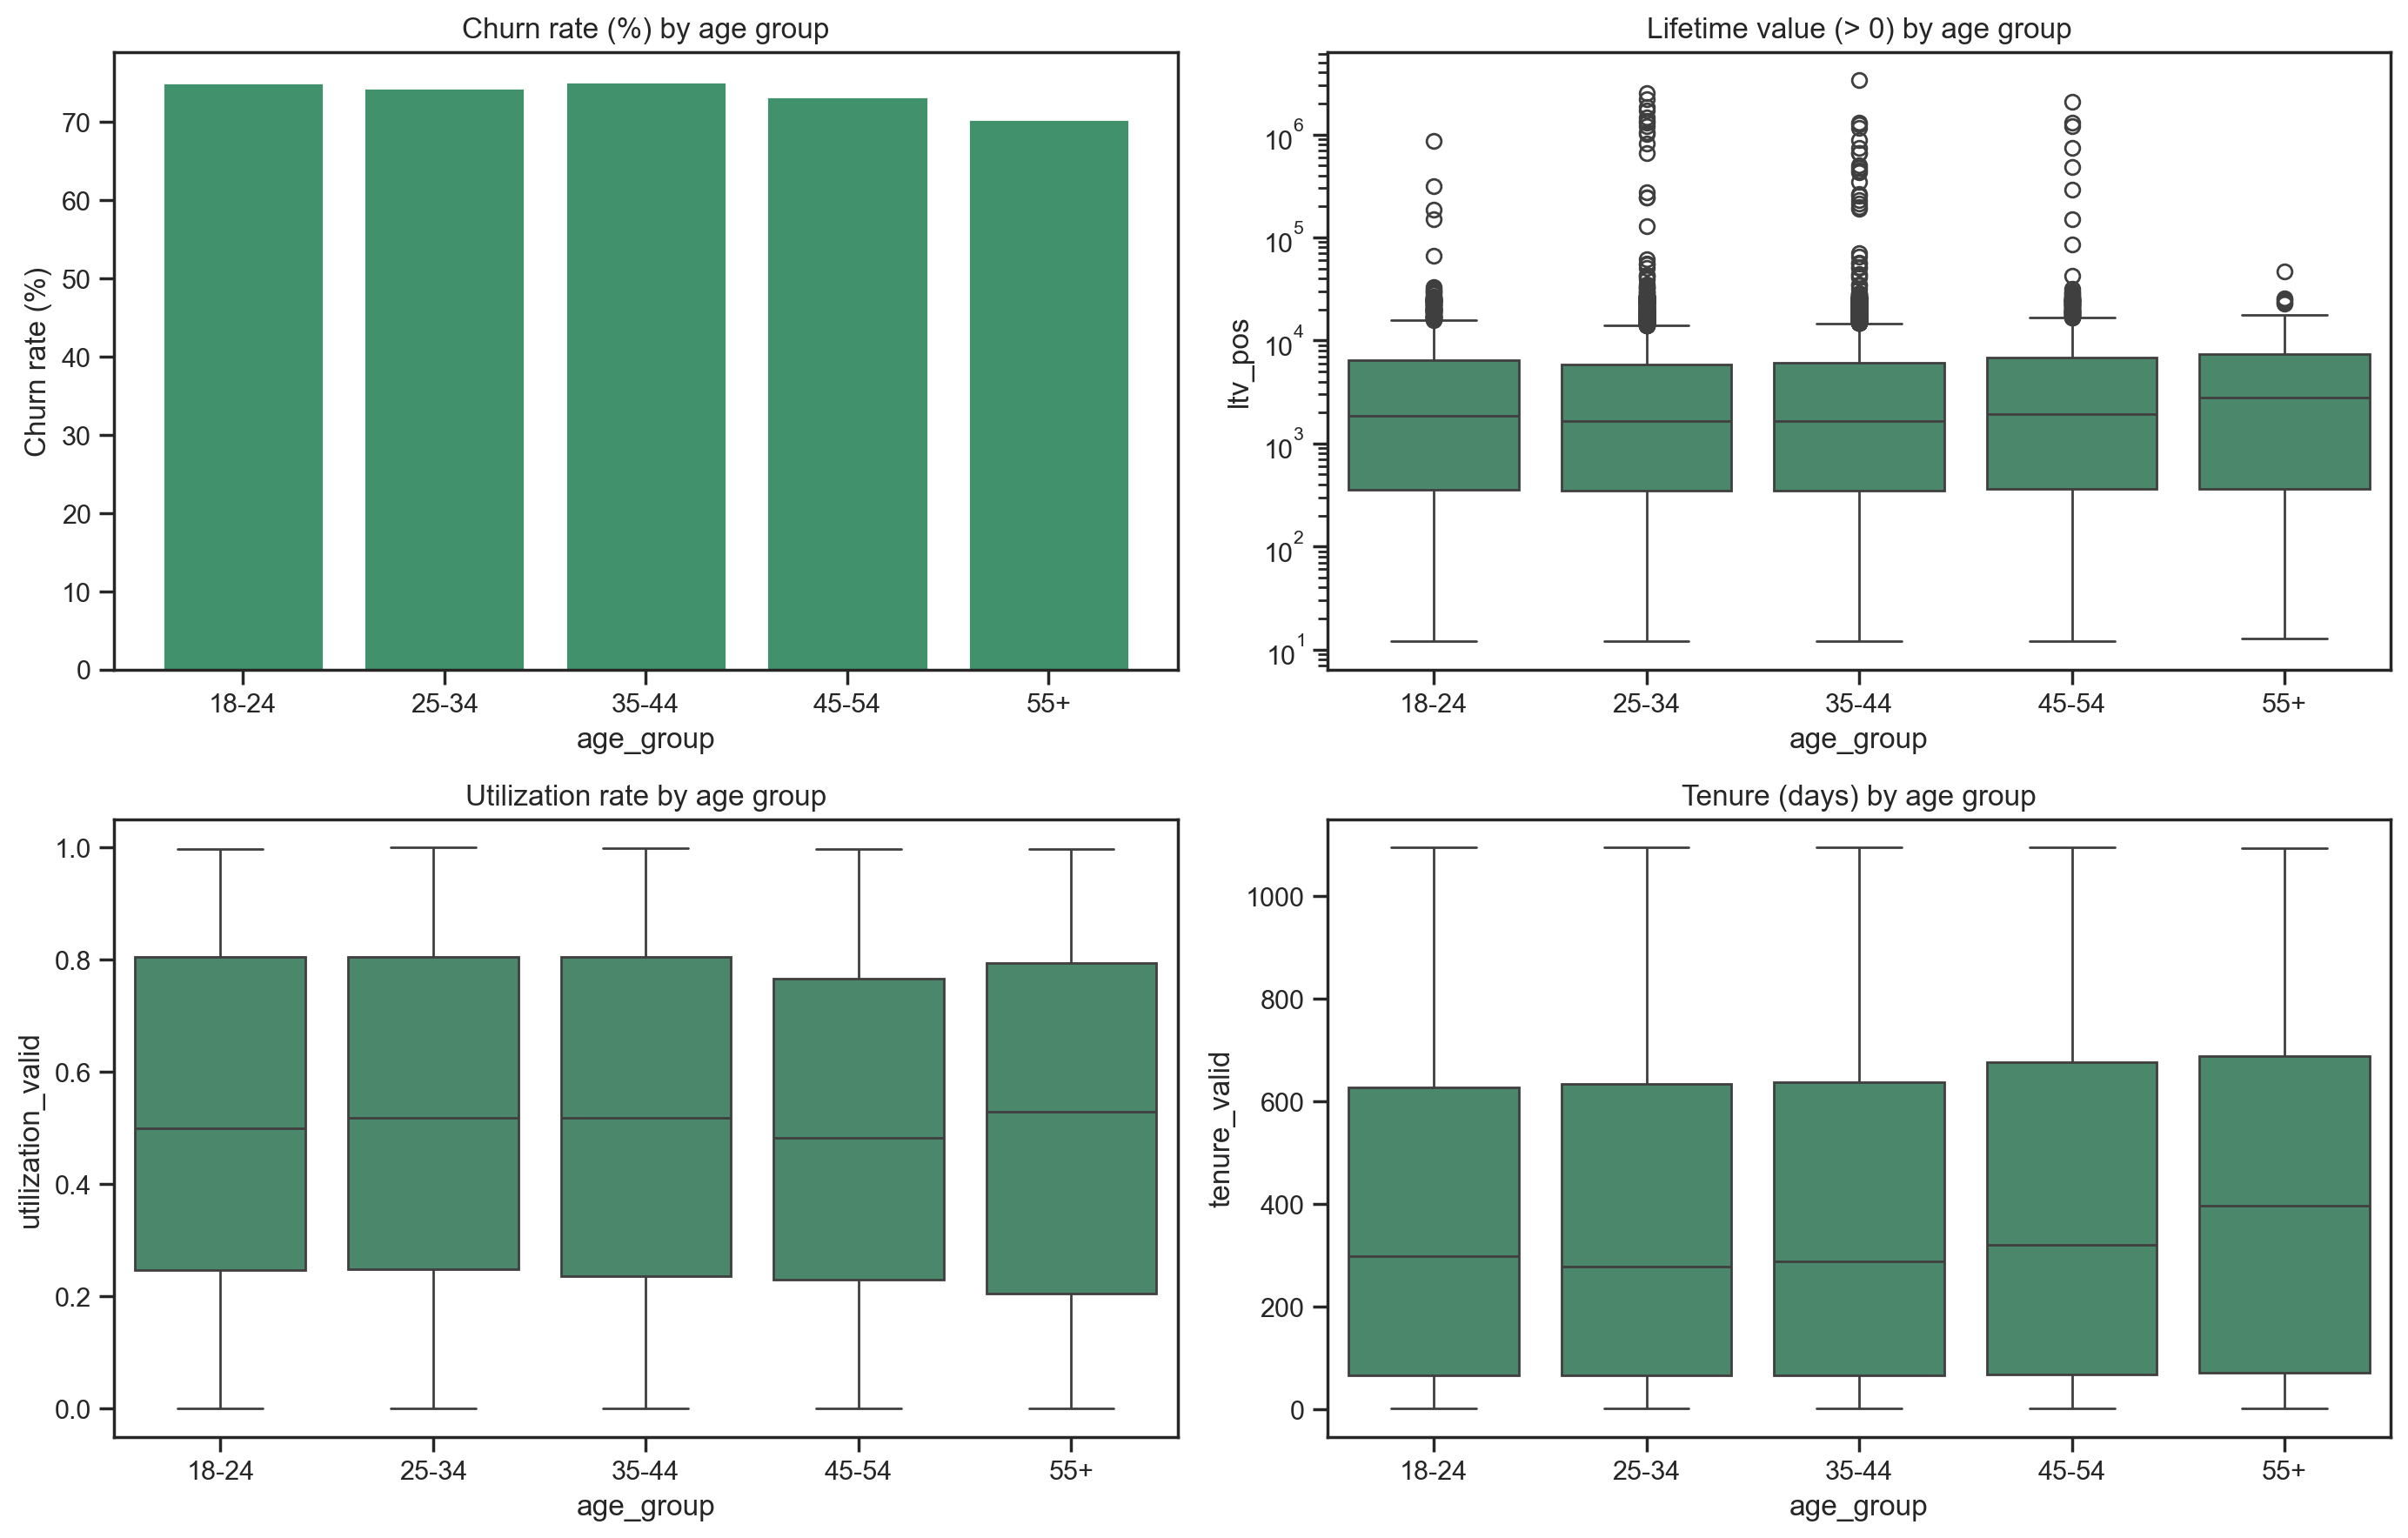

In [98]:
# Visual comparison
sns.set_style("ticks")

sp_rows = 2
sp_cols = 2
fig, axes = plt.subplots(sp_rows, sp_cols, figsize=(14, 9))

# 1. churn rate (bar)
churn_pct = df_age.groupby("age_group", observed=True)["has_churned"].mean() * 100
axes[0, 0].bar(churn_pct.index.astype(str), churn_pct.values, color=main_color)
axes[0, 0].set_title("Churn rate (%) by age group")
axes[0, 0].set_xlabel("age_group")
axes[0, 0].set_ylabel("Churn rate (%)")

# 2-4. numeric features (boxplots)
box_features = [
    ("ltv_pos", "Lifetime value (> 0) by age group", True),
    ("utilization_valid", "Utilization rate by age group", False),
    ("tenure_valid", "Tenure (days) by age group", False),
]

for ax, (feat, title, log_scale) in zip(axes.flatten()[1:], box_features):
    sns.boxplot(data=df_age, x="age_group", y=feat, color=main_color, ax=ax)
    if log_scale:
        ax.set_yscale("log")
    ax.set_title(title)
    ax.set_xlabel("age_group")

plt.tight_layout()
plt.show()